<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_notas_im_kf_ekf_eskf_iekf_ieskf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

*O Filtro de Kalman para Cientistas da Computação* · [← guia da série](kalman_guia_da_serie.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/kalman/notebooks/kalman_guia_da_serie.ipynb)) · [repositório](https://github.com/saulobortolon/Quaternios-Kalman-CC) · série irmã: [*Números, movimento e Kalman*](../../dominios/notebooks/X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb))

# Notas sobre o Filtro de Kalman: KF, EKF, ESKF, IEKF e IESKF

## Tradução comentada, com código e conferências, das notas de Gyubeom Edward Im (2024)

> **Obra original.** Gyubeom Edward Im, *Notes on Kalman Filter (KF, EKF, ESKF, IEKF, IESKF)*, arXiv:2406.06427v3, 28 de junho de 2024. Blog do autor: [alida.tistory.com](https://alida.tistory.com). Página: [arxiv.org/abs/2406.06427](https://arxiv.org/abs/2406.06427).
>
> **Licença.** A obra foi distribuída sob licença Creative Commons Atribuição (CC BY), conforme indicado pelo professor responsável por este material. Confira a versão exata da licença na página do arXiv.
>
> **O que foi alterado.** Este notebook é uma **tradução para o português, adaptada**:
> - o texto segue a ordem e o conteúdo do original, às vezes condensado (por exemplo, os sete passos da dedução do filtro de Bayes, que no original repetem a equação inteira a cada passo);
> - as **figuras são as do original**, sem alteração, extraídas do código-fonte LaTeX do arXiv;
> - foram **acrescentados** código Python, exemplos numéricos, conferências e exercícios;
> - os erros encontrados no original estão **corrigidos no texto** e sinalizados em caixas **Nota do tradutor** (lista completa na seção 12).
>
> O autor original não revisou esta versão e não responde por ela.

**Como ler.** As notas de Im são um excelente **mapa** da família Kalman: cada filtro é apresentado com o mesmo molde (modelo, linearização, predição, correção, resumo). O que falta ao texto, e que este notebook acrescenta, é **ver os filtros funcionando** e **conferir** cada fórmula com números. Cada seção traduzida é seguida de células de código; cada célula de conferência imprime `OK` ou interrompe a execução.

**Lugar na série.** Este é o notebook de **referência teórica** da série. Ele reúne, com notação única, os algoritmos usados nos outros:
- **KF:** `kalman_passo_a_passo`, `kalman_produto_de_gaussianas_faragher` e a trilha A de `mq_hmm_kalman_duas_trilhas`;
- **EKF e IEKF:** `pepe_kalman_parte1_ekf_iekf` e as seções C5 e C5b de `mq_hmm_kalman_duas_trilhas`;
- **ESKF e IESKF:** **novos** na série. São os filtros usados em robótica e em odometria visual e inercial, quando parte do estado é uma **rotação**.

**Roteiro** (numeração do original, de 1 a 11, mais os acréscimos)
1. Preliminares
2. Filtro de Bayes recursivo
3. Filtro de Kalman (KF)
4. Filtro de Kalman estendido (EKF)
5. Filtro de Kalman de estado de erro (ESKF)
6. Filtro de Kalman estendido iterado (IEKF)
7. Filtro de Kalman de estado de erro iterado (IESKF)
8. Dedução do filtro de Kalman
9. MAP, Gauss–Newton e EKF
10. Dedução da correção do IESKF
11. Resumo em slides
12. Notas do tradutor: lista consolidada
13. Exercícios
14. Referências

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(2406)

def confere(nome, a, b, tol=1e-8, relativo=False):
    # compara duas quantidades numéricas; imprime OK ou interrompe
    a, b = np.asarray(a, float), np.asarray(b, float)
    erro = np.max(np.abs(a - b)) / (np.max(np.abs(b)) if relativo else 1.0)
    print(f"{'OK ' if erro < tol else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert erro < tol, nome

def gauss(x, mu, var):
    return np.exp(-0.5 * (x - mu)**2 / var) / np.sqrt(2 * np.pi * var)

def jacobiano_numerico(f, x, eps=1e-6):
    # diferenças centradas: coluna i = (f(x + eps e_i) - f(x - eps e_i)) / (2 eps)
    x = np.asarray(x, float)
    colunas = []
    for i in range(x.size):
        e = np.zeros_like(x); e[i] = eps
        colunas.append((np.asarray(f(x + e)) - np.asarray(f(x - e))) / (2 * eps))
    return np.column_stack(colunas)

---
# 1. Preliminares

O **filtro de Kalman** é um algoritmo que **prevê e atualiza**, de forma recursiva, o estado de um **sistema que varia no tempo**, combinando as **previsões** de um modelo do sistema com **observações** ruidosas.

Esta seção resume o conhecimento básico necessário antes de chegar ao filtro propriamente dito.

## 1.1 Teoria da estimação

A **teoria da estimação** reúne os métodos para obter os parâmetros ou os estados de um modelo a partir de dados observados. É usada em análise de dados, processamento de sinais, aprendizado de máquina, finanças e robótica, como ferramenta para decidir bem sob incerteza.

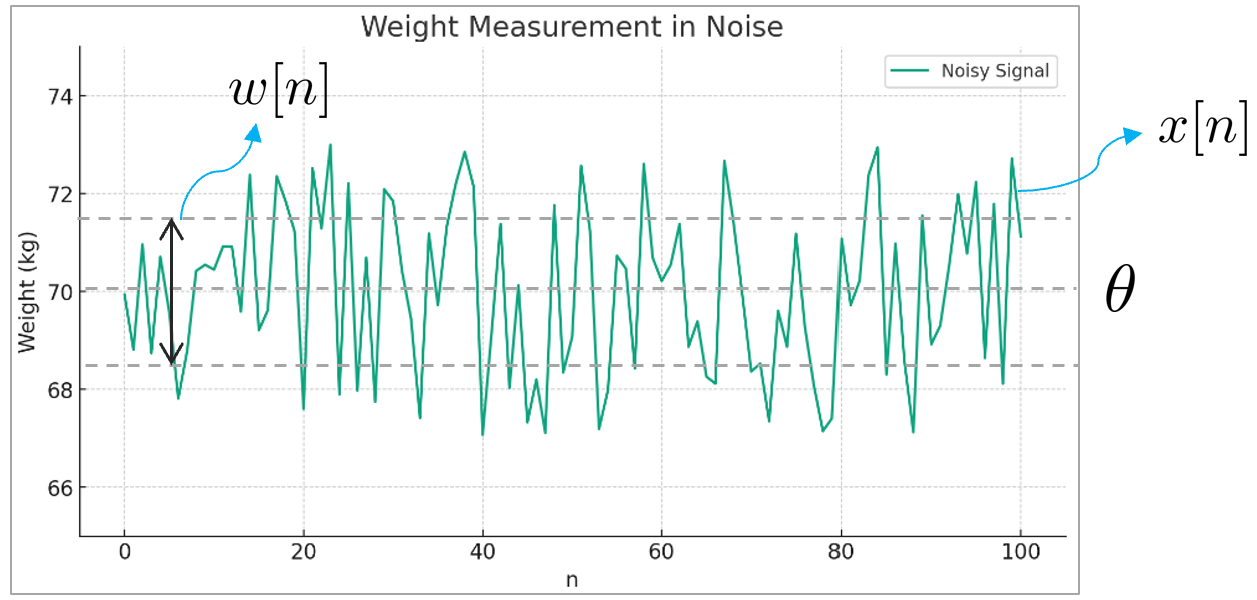

Por exemplo, suponha que, ao longo de um ano, medimos o peso de uma pessoa cujo peso médio é 70 kg (figura acima). Os dados em verde formam a sequência $x[n]$; o valor central desses dados é o parâmetro $\theta$ que queremos estimar; a dispersão em torno de $\theta$ é representada pelo ruído $w[n]$. O problema de estimar $\theta$ a partir de $x[n]$ tem o modelo

$$x[n]=\theta+w[n],\qquad n=0,1,\dots,N-1,$$

- $x[n]$: dado observado;
- $\theta$: parâmetro a estimar;
- $w[n]$: ruído aleatório.

## 1.2 A visão bayesiana

A teoria da estimação se divide em duas visões, conforme o que se pensa do parâmetro $\theta$:
- **frequentista:** $\theta$ é um parâmetro **determinístico** desconhecido;
- **bayesiana:** $\theta$ é uma **variável aleatória**, com uma distribuição *a priori*.

$$\text{Frequentista:}\quad \underbrace{x[n]}_{\text{v.a.}}=\underbrace{\theta}_{\text{determinístico}}+w[n]\qquad\qquad \text{Bayesiana:}\quad \underbrace{x[n]}_{\text{v.a.}}=\underbrace{\theta}_{\text{v.a.}}+w[n]$$

A filosofia bayesiana parte da premissa de que, **se temos informação prévia** sobre $\theta$, podemos usá-la para estimar melhor. Para isso, é preciso fornecer (ou conseguir calcular) uma densidade *a priori* $p(\theta)$. Como $\theta$ também é variável aleatória, vale a regra de Bayes:

$$p(\theta\mid x)=\frac{p(\theta)\,p(x\mid\theta)}{p(x)},$$

- $p(\theta\mid x)$: distribuição *a posteriori* de $\theta$ dados os dados $x$;
- $p(x\mid\theta)$: distribuição de $x$ dado $\theta$, a **verossimilhança**;
- $p(x)$: distribuição de $x$ (a constante de normalização);
- $p(\theta)$: distribuição *a priori* de $\theta$.

### Acréscimo: as duas visões no exemplo do peso, e o primeiro filtro de Kalman

Vamos refazer o exemplo da figura 16 com números. A estimativa **frequentista** de $\theta$ é a média amostral. A **bayesiana**, com *a priori* $\theta\sim\mathcal N(m_0,s_0^2)$ e ruído $w[n]\sim\mathcal N(0,\sigma^2)$, tem *a posteriori* gaussiana, com fórmula fechada (soma de precisões):

$$\frac1{s_N^2}=\frac1{s_0^2}+\frac N{\sigma^2},\qquad m_N=s_N^2\Big(\frac{m_0}{s_0^2}+\frac{\sum_n x[n]}{\sigma^2}\Big).$$

O ponto da conferência abaixo: **processar as medidas uma a uma**, com um filtro de Kalman escalar em que o estado não muda ($F=1$, $Q=0$, $H=1$), dá **exatamente** a mesma *a posteriori* que a fórmula em lote. Este é o filtro de Kalman mais simples possível, e já é um estimador bayesiano recursivo.

frequentista (média amostral): 70.0841
bayesiana em lote:             70.0739  ± 0.1498
bayesiana recursiva (Kalman):  70.0739  ± 0.1498
OK   Kalman recursivo = a posteriori em lote (média):  diferença máxima = 2.84e-14
OK   Kalman recursivo = a posteriori em lote (variância):  diferença máxima = 1.04e-17


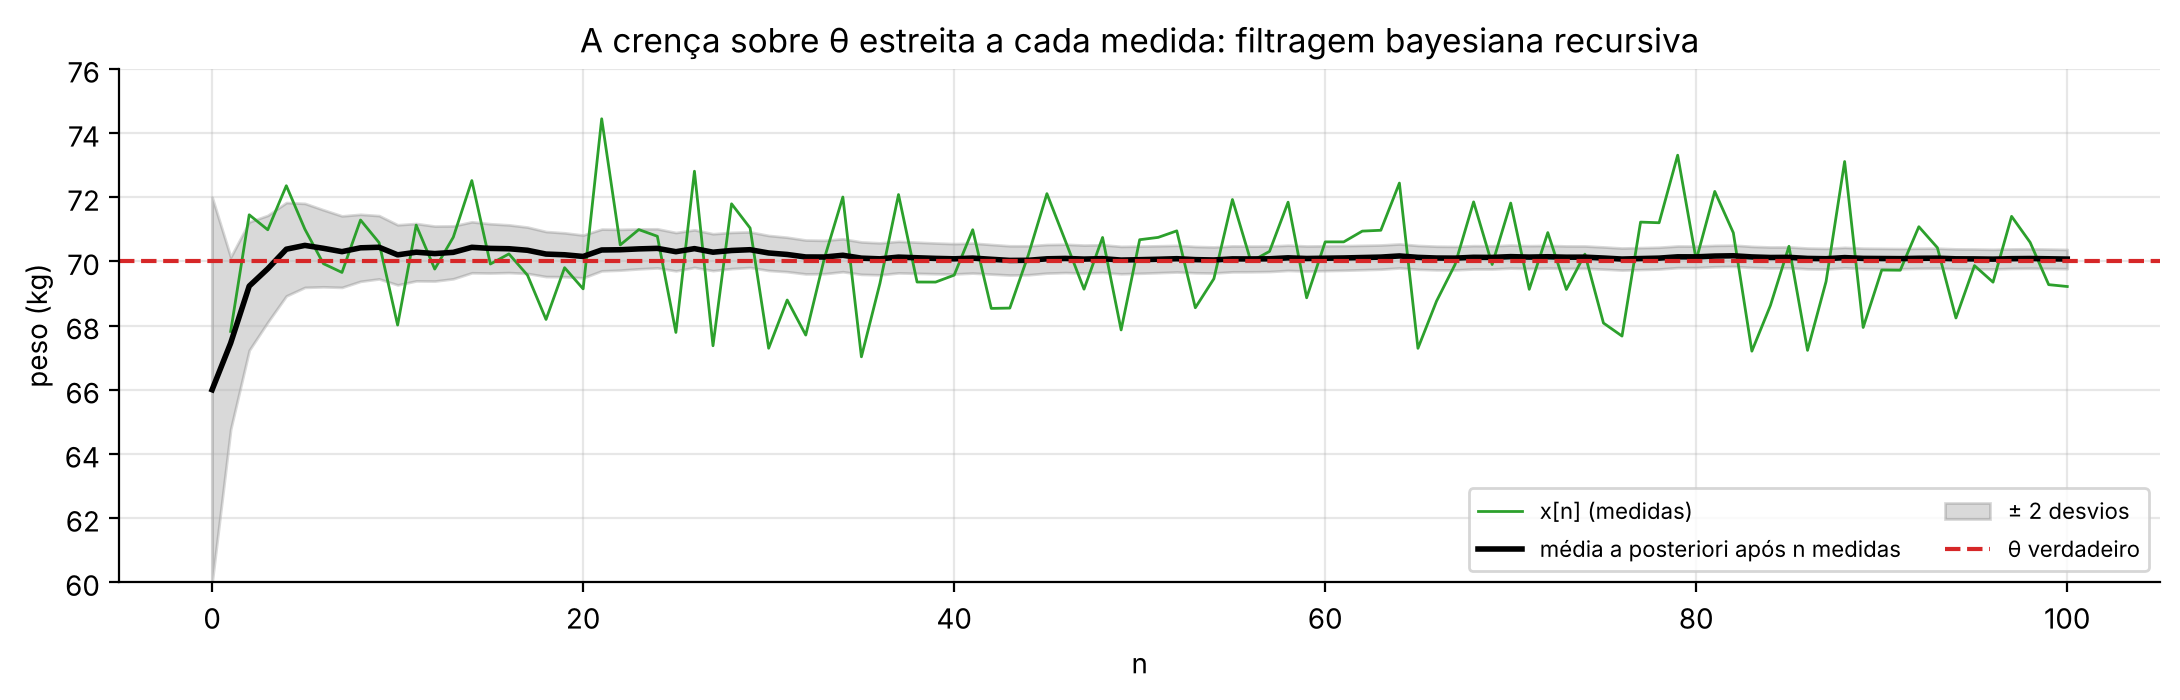

In [2]:
THETA, SIG_PESO, N_PESO = 70.0, 1.5, 100
x_peso = THETA + SIG_PESO * rng.standard_normal(N_PESO)

# frequentista: média amostral
theta_freq = x_peso.mean()

# bayesiana em lote (a priori razoavelmente errada, de propósito)
m0, s0sq = 66.0, 3.0**2
sN2 = 1.0 / (1.0 / s0sq + N_PESO / SIG_PESO**2)
mN = sN2 * (m0 / s0sq + x_peso.sum() / SIG_PESO**2)

# bayesiana recursiva = Kalman escalar com F = 1, Q = 0, H = 1
m, s2 = m0, s0sq
hist_m, hist_s = [m], [np.sqrt(s2)]
for xn in x_peso:
    K = s2 / (s2 + SIG_PESO**2)          # ganho
    m = m + K * (xn - m)                  # média corrigida
    s2 = (1 - K) * s2                     # variância corrigida
    hist_m.append(m); hist_s.append(np.sqrt(s2))

print(f"frequentista (média amostral): {theta_freq:.4f}")
print(f"bayesiana em lote:             {mN:.4f}  ± {np.sqrt(sN2):.4f}")
print(f"bayesiana recursiva (Kalman):  {m:.4f}  ± {np.sqrt(s2):.4f}")
confere("Kalman recursivo = a posteriori em lote (média)", m, mN, tol=1e-10)
confere("Kalman recursivo = a posteriori em lote (variância)", s2, sN2, tol=1e-12)

hist_m, hist_s = np.array(hist_m), np.array(hist_s)
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(range(1, N_PESO + 1), x_peso, color="tab:green", lw=1, label="x[n] (medidas)")
ax.plot(range(N_PESO + 1), hist_m, "k", lw=2, label="média a posteriori após n medidas")
ax.fill_between(range(N_PESO + 1), hist_m - 2 * hist_s, hist_m + 2 * hist_s, color="k", alpha=.15, label="± 2 desvios")
ax.axhline(THETA, ls="--", color="tab:red", label="θ verdadeiro")
ax.set_xlabel("n"); ax.set_ylabel("peso (kg)"); ax.legend(fontsize=8, ncol=2); ax.set_ylim(60, 76)
ax.set_title("A crença sobre θ estreita a cada medida: filtragem bayesiana recursiva")
plt.tight_layout(); plt.show()

## 1.3 O problema de estimação

O problema de estimação pode ser ilustrado assim:

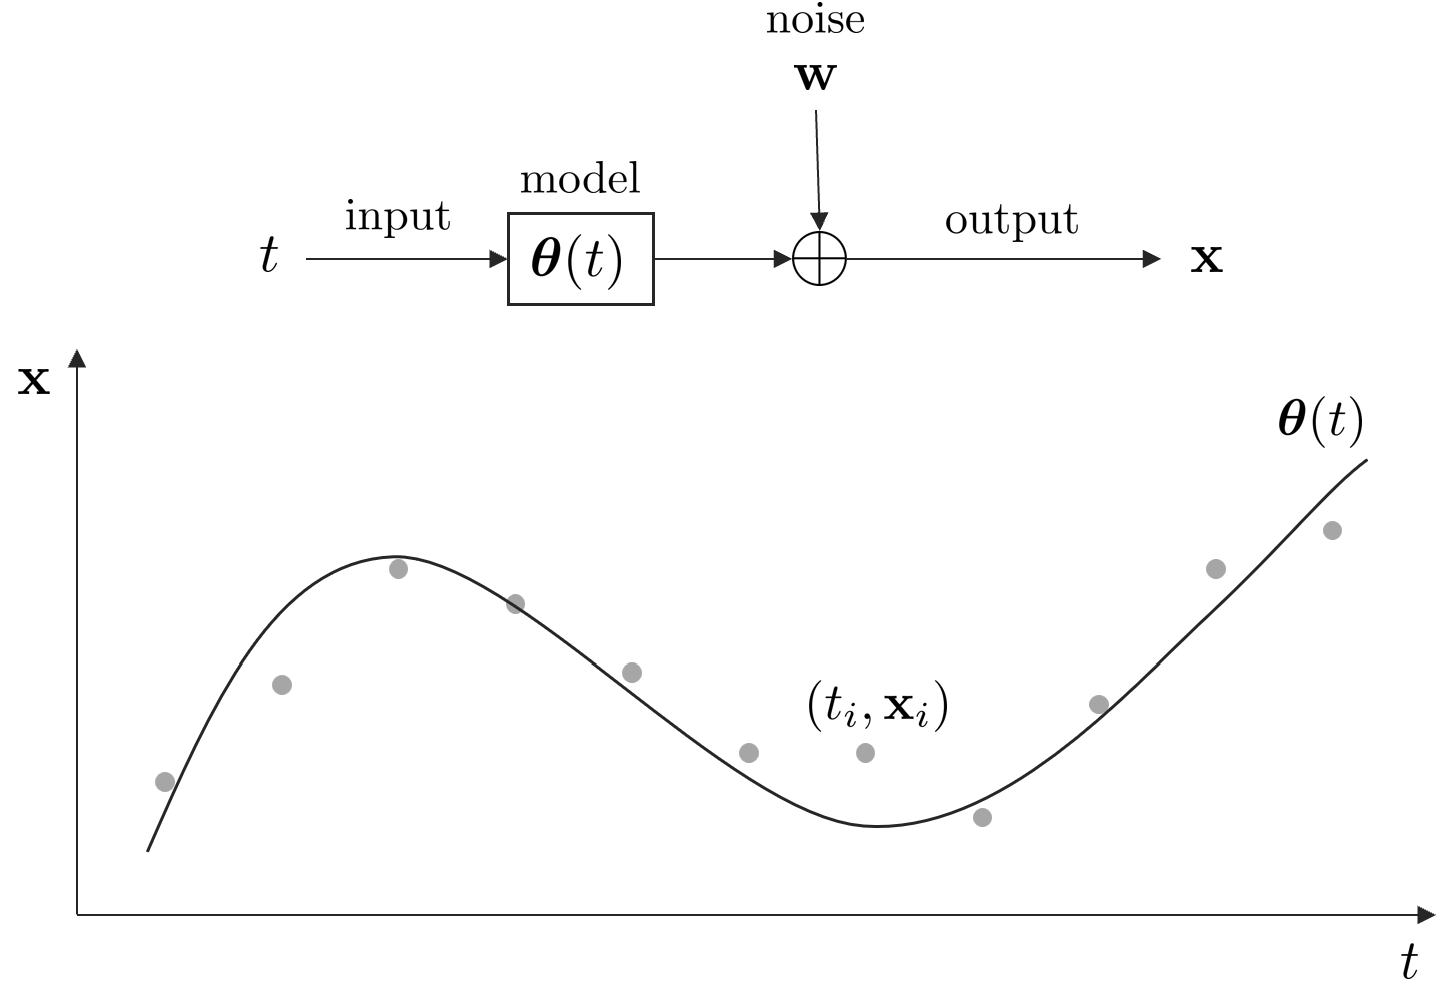

O objetivo é encontrar o modelo ótimo $\boldsymbol\theta(t)$ a partir dos dados $(t_i,\mathbf x_i)$. O **tipo** de problema depende do instante que se quer estimar:

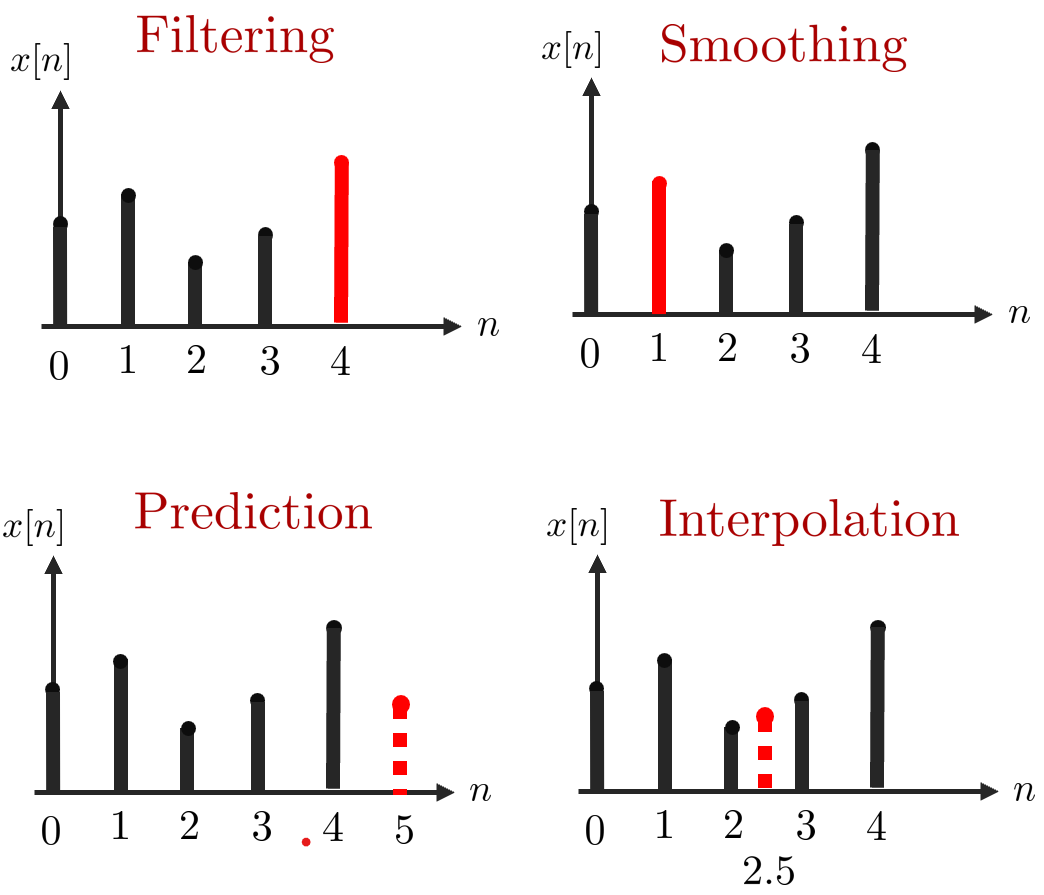

1. **Filtragem:** estimar $\theta=x[N-1]$ dados $\{x[0],x[1],\dots,x[N-1]\}$. O parâmetro depende apenas dos dados atuais e passados; a ideia é "filtrar" o ruído do sinal.
2. **Suavização:** estimar um valor intermediário $\theta=s[n]$ dados **todos** os $\{x[0],\dots,x[N-1]\}$. Para estimar $s[1]$, usam-se também os dados futuros; por isso a suavização só pode ser feita depois que todos os dados chegaram.
3. **Predição:** estimar $\theta=x[N-1+l]$, com $l>0$, dados $\{x[0],\dots,x[N-1]\}$.
4. **Interpolação:** estimar $\theta=x[n]$ dados $\{x[0],\dots,x[n-1],x[n+1],\dots,x[N-1]\}$.

> **Nota do tradutor.** Na série, a **filtragem** é o Kalman propriamente dito; a **suavização** é o suavizador RTS (seção C3 de `mq_hmm_kalman_duas_trilhas`); a **predição** é a coluna "onde estará" do IMM (`pepe_kalman_parte2_imm`).

## 1.4 Sistema dinâmico

Um sistema cujas variáveis de estado mudam com o tempo pode ser modelado assim:

$$\text{Modelo de movimento:}\quad \mathbf x_t=\mathbf f(\mathbf x_{t-1},\mathbf u_t)+\mathbf w_t\qquad\qquad \text{Modelo de observação:}\quad \mathbf z_t=\mathbf h(\mathbf x_t)+\mathbf v_t$$

- $\mathbf x_t$: variáveis de estado no instante $t$;
- $\mathbf u_t$: entradas de controle no instante $t$;
- $\mathbf z_t$: observações no instante $t$;
- $\mathbf f(\mathbf x_{t-1},\mathbf u_t)$: função do modelo de movimento, que prevê o estado atual a partir do anterior e do controle atual;
- $\mathbf h(\mathbf x_t)$: função do modelo de observação, que converte o estado em observação;
- $\mathbf w_t$: ruído do modelo de movimento;
- $\mathbf v_t$: ruído do modelo de observação.

Com essa notação, o problema de estimação fica:

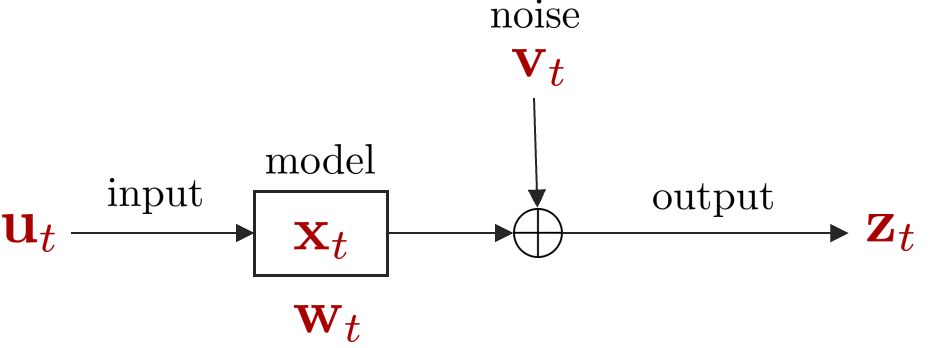

E o sistema dinâmico pode ser desenhado como um grafo:

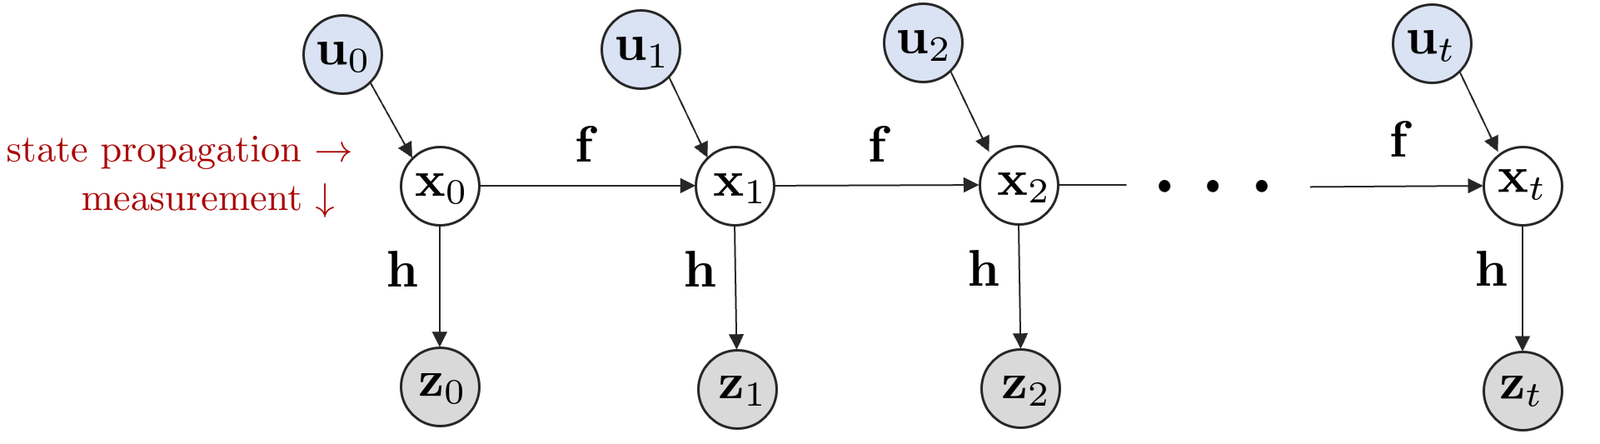

Um sistema dinâmico costuma ter uma fase de **predição** e uma fase de **atualização** (ou **correção**). A predição obtém o próximo estado $\mathbf x_{t+1}$ a partir de todas as observações $\mathbf z_{0:t}$ e do estado atual $\mathbf x_t$:

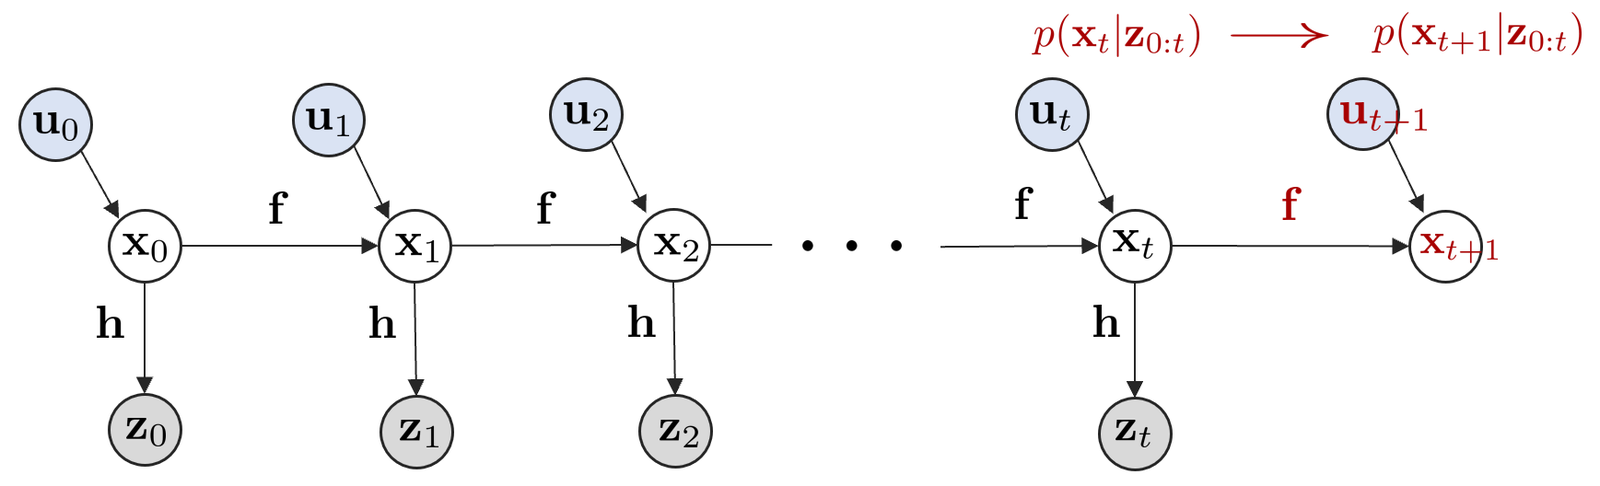

A atualização incorpora a nova observação $\mathbf z_{t+1}$, gerada pelo próximo estado $\mathbf x_{t+1}$:

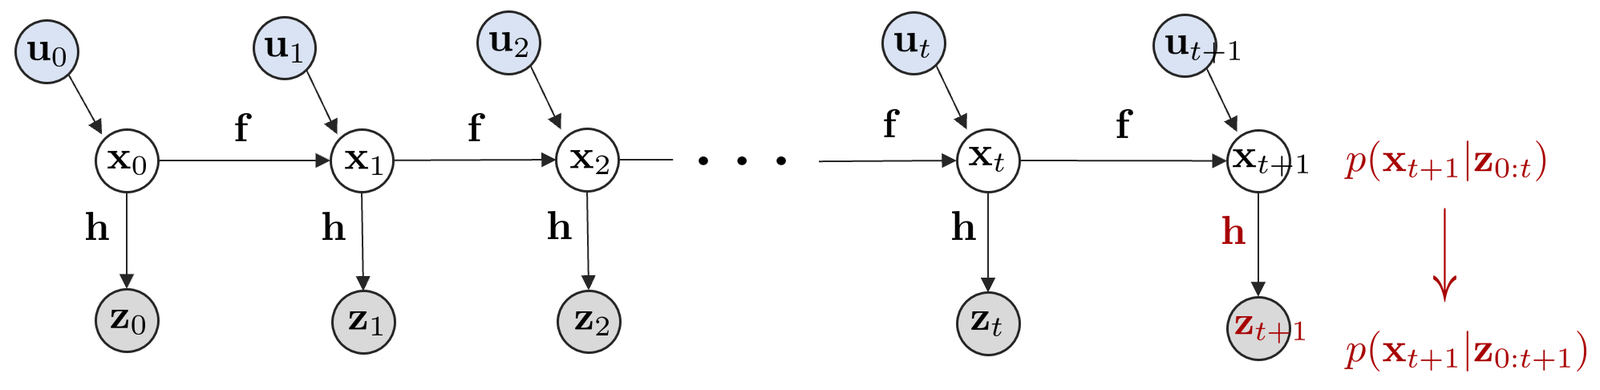

> **Nota do tradutor.** O grafo da figura 20 é o mesmo de um **modelo oculto de Markov** (HMM): estados escondidos em cadeia, cada um emitindo uma observação. A diferença é só o tipo de variável (contínua e gaussiana no Kalman, discreta no HMM). Essa equivalência é o fio condutor de `mq_hmm_kalman_duas_trilhas`.

---
# 2. Filtro de Bayes recursivo

Dados os controles e as observações, o grau de confiança sobre o estado atual $\mathbf x_t$, a **crença** (*belief*) $\mathrm{bel}(\mathbf x_t)$, é definido como

$$\mathrm{bel}(\mathbf x_t)=p(\mathbf x_t\mid \mathbf z_{1:t},\mathbf u_{1:t}),$$

- $\mathbf z_{1:t}=\{\mathbf z_1,\dots,\mathbf z_t\}$: observações do instante 1 até $t$;
- $\mathbf u_{1:t}=\{\mathbf u_1,\dots,\mathbf u_t\}$: controles do instante 1 até $t$;
- $\mathrm{bel}(\mathbf x_t)$: a probabilidade (grau de crença) de o robô estar em $\mathbf x_t$, dadas todas as observações e os controles até $t$.

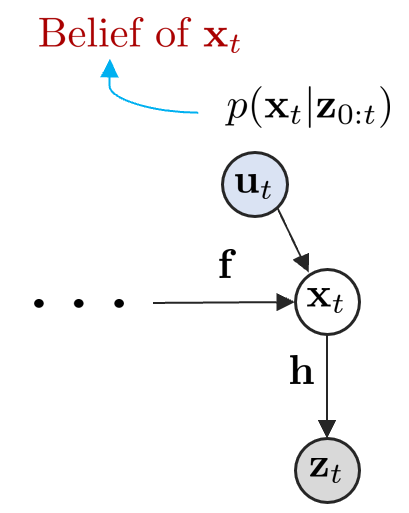

Como $\mathrm{bel}(\cdot)$ é desenvolvida pela regra de Bayes, chama-se **filtro de Bayes**. Usando a hipótese de Markov e a regra de Bayes, obtém-se um filtro **recursivo**:

$$\mathrm{bel}(\mathbf x_t)=\eta\cdot p(\mathbf z_t\mid\mathbf x_t)\,\overline{\mathrm{bel}}(\mathbf x_t),\qquad \overline{\mathrm{bel}}(\mathbf x_t)=\int p(\mathbf x_t\mid\mathbf x_{t-1},\mathbf u_t)\,\mathrm{bel}(\mathbf x_{t-1})\,d\mathbf x_{t-1},$$

- $\eta=1/p(\mathbf z_t\mid\mathbf z_{1:t-1},\mathbf u_{1:t})$: fator de normalização, que faz a área da distribuição valer 1;
- $p(\mathbf z_t\mid\mathbf x_t)$: modelo de observação;
- $p(\mathbf x_t\mid\mathbf x_{t-1},\mathbf u_t)$: modelo de movimento.

O filtro é chamado recursivo porque calcula $\mathrm{bel}(\mathbf x_t)$ a partir de $\mathrm{bel}(\mathbf x_{t-1})$.

## 2.1 Dedução do filtro de Bayes recursivo

O original apresenta a dedução em sete passos, repetindo a cadeia inteira de igualdades a cada passo e destacando a linha que muda. Aqui a cadeia aparece uma vez, com o passo indicado à direita de cada igualdade:

$$
\begin{aligned}
\mathrm{bel}(\mathbf x_t)&=p(\mathbf x_t\mid\mathbf z_{1:t},\mathbf u_{1:t})\\
&=\eta\, p(\mathbf z_t\mid\mathbf x_t,\mathbf z_{1:t-1},\mathbf u_{1:t})\;p(\mathbf x_t\mid\mathbf z_{1:t-1},\mathbf u_{1:t}) && \text{passo 1: regra de Bayes}\\
&=\eta\, p(\mathbf z_t\mid\mathbf x_t)\;p(\mathbf x_t\mid\mathbf z_{1:t-1},\mathbf u_{1:t}) && \text{passo 2: Markov (a medida só depende do estado atual)}\\
&=\eta\, p(\mathbf z_t\mid\mathbf x_t)\int p(\mathbf x_t\mid\mathbf x_{t-1},\mathbf z_{1:t-1},\mathbf u_{1:t})\,p(\mathbf x_{t-1}\mid\mathbf z_{1:t-1},\mathbf u_{1:t})\,d\mathbf x_{t-1} && \text{passo 3: probabilidade total (marginalização)}\\
&=\eta\, p(\mathbf z_t\mid\mathbf x_t)\int p(\mathbf x_t\mid\mathbf x_{t-1},\mathbf u_t)\,p(\mathbf x_{t-1}\mid\mathbf z_{1:t-1},\mathbf u_{1:t})\,d\mathbf x_{t-1} && \text{passo 4: Markov (o estado só depende do anterior e do controle atual)}\\
&=\eta\, p(\mathbf z_t\mid\mathbf x_t)\int p(\mathbf x_t\mid\mathbf x_{t-1},\mathbf u_t)\,p(\mathbf x_{t-1}\mid\mathbf z_{1:t-1},\mathbf u_{1:t-1})\,d\mathbf x_{t-1} && \text{passo 5: o controle futuro } \mathbf u_t \text{ não informa sobre } \mathbf x_{t-1}\\
&=\eta\, p(\mathbf z_t\mid\mathbf x_t)\int p(\mathbf x_t\mid\mathbf x_{t-1},\mathbf u_t)\,\mathrm{bel}(\mathbf x_{t-1})\,d\mathbf x_{t-1} && \text{passo 6: reconhecer } \mathrm{bel}(\mathbf x_{t-1})\\
&=\eta\, p(\mathbf z_t\mid\mathbf x_t)\;\overline{\mathrm{bel}}(\mathbf x_t) && \text{passo 7: reconhecer } \overline{\mathrm{bel}}(\mathbf x_t)
\end{aligned}
$$

São usadas a regra de Bayes, $p(x\mid y)=p(y\mid x)p(x)/p(y)$, a hipótese de Markov e a lei da probabilidade total, $p(x)=\int p(x\mid y)p(y)\,dy$.

> **Nota do tradutor.** (i) Na última linha da cadeia completa, o original escreve $\overline{\mathrm{bel}}(\mathbf x_{t-1})$; o correto é $\overline{\mathrm{bel}}(\mathbf x_t)$, como no próprio passo 7. (ii) O original justifica o passo 5 também como "hipótese de Markov". Mais precisamente, é a hipótese de que o controle aplicado em $t$ não traz informação sobre o estado em $t-1$ (o controle não é escolhido olhando o estado escondido).

## 2.2 O caso de crença gaussiana

Se $\mathrm{bel}(\mathbf x_t)$ é gaussiana, o filtro de Bayes recebe o nome de **filtro de Kalman**:

$$\overline{\mathrm{bel}}(\mathbf x_t)\sim\mathcal N(\hat{\mathbf x}_{t|t-1},\mathbf P_{t|t-1})\ \ \text{(predição)},\qquad \mathrm{bel}(\mathbf x_t)\sim\mathcal N(\hat{\mathbf x}_{t|t},\mathbf P_{t|t})\ \ \text{(correção)}.$$

Média e covariância também são escritas $(\hat{\boldsymbol\mu},\boldsymbol\Sigma)$; é o mesmo conceito com outra notação.

### Acréscimo: o filtro de Bayes numa grade, e por que o caso gaussiano é especial

O filtro de Bayes pode ser implementado **literalmente**: discretizamos o eixo $x$ numa grade fina, guardamos a crença como um vetor de probabilidades, fazemos a integral da predição como uma soma (uma multiplicação matriz–vetor) e a correção como um produto ponto a ponto seguido de normalização.

Para um robô numa linha, $x_t=x_{t-1}+u_t+w_t$ e $z_t=x_t+v_t$, com ruídos gaussianos, tudo continua gaussiano. A média e a variância calculadas na grade devem coincidir com as do filtro de Kalman, que faz a mesma conta com **dois números** em vez de milhares. Essa é a vantagem do caso gaussiano: a crença inteira cabe em $(\hat x,P)$.

grade:  média 59.13191  variância 1.31169   (2401 números por crença)
Kalman: média 59.13191  variância 1.31169   (2 números por crença)
OK   filtro de Bayes na grade = Kalman (média):  diferença máxima = 7.11e-15
OK   filtro de Bayes na grade = Kalman (variância):  diferença máxima = 0.00e+00


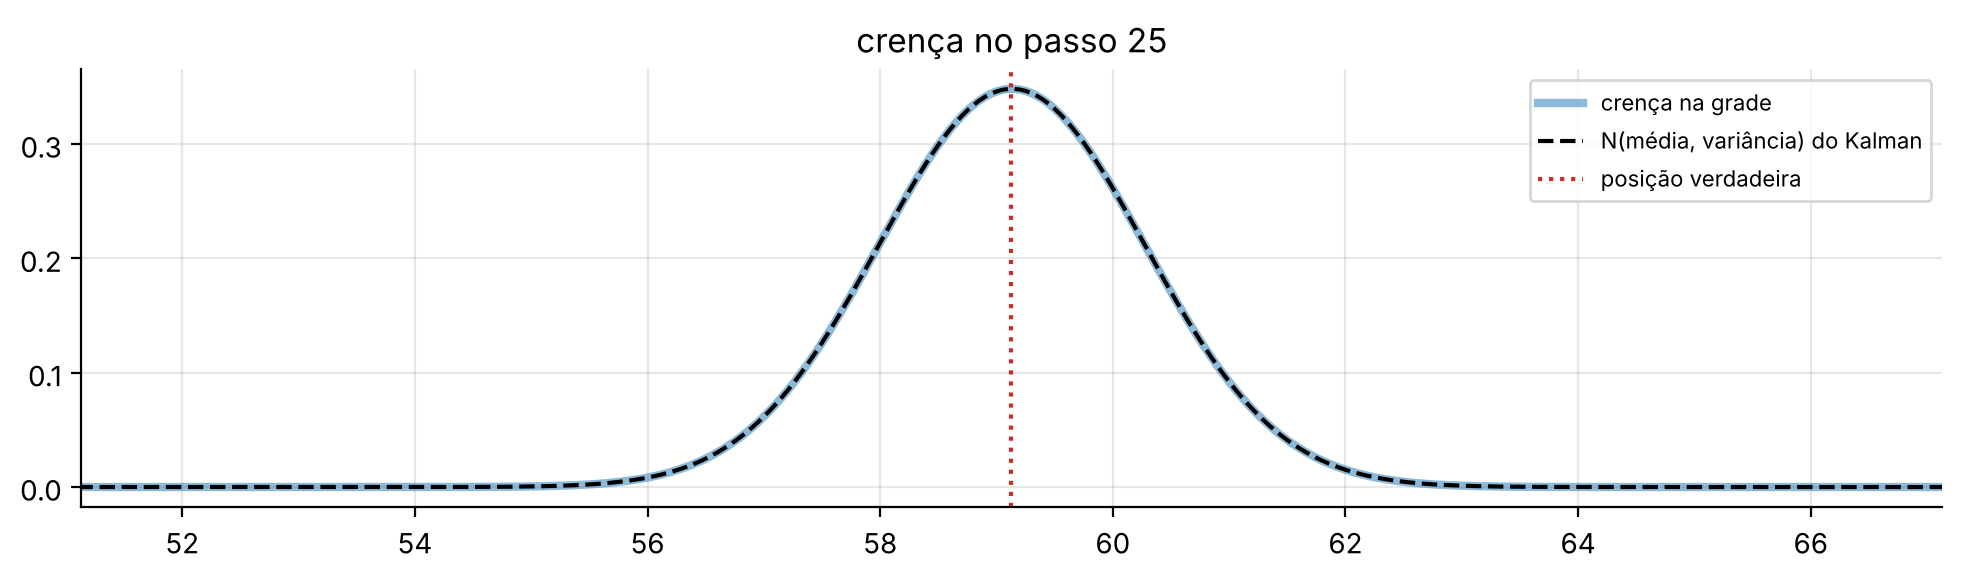

In [3]:
# grade
xs = np.linspace(-30.0, 90.0, 2401); dx = xs[1] - xs[0]
SIG_MOV, SIG_OBS = 0.8, 2.0
T_GRADE = 25
u_g = np.full(T_GRADE, 2.0)                     # o robô tenta andar 2 m por passo
x_v = np.zeros(T_GRADE + 1); z_g = np.zeros(T_GRADE + 1)
for t in range(1, T_GRADE + 1):
    x_v[t] = x_v[t - 1] + u_g[t - 1] + SIG_MOV * rng.standard_normal()
    z_g[t] = x_v[t] + SIG_OBS * rng.standard_normal()

# matriz de transição na grade: coluna j = densidade de x_t dado x_{t-1} = xs[j] (sem o controle)
Kmov = gauss(xs[:, None], xs[None, :], SIG_MOV**2) * dx

bel = gauss(xs, 0.0, 1.0**2); bel /= bel.sum()       # bel(x_0) = N(0, 1)
m_kf, P_kf = 0.0, 1.0**2
for t in range(1, T_GRADE + 1):
    # --- predição: integral = soma; o controle desloca a grade
    bel_bar = Kmov @ np.interp(xs - u_g[t - 1], xs, bel, left=0, right=0)
    bel_bar /= bel_bar.sum()
    # --- correção: produto pela verossimilhança e normalização (η)
    bel = gauss(z_g[t], xs, SIG_OBS**2) * bel_bar
    bel /= bel.sum()
    # --- Kalman escalar: a mesma conta com dois números
    m_kf, P_kf = m_kf + u_g[t - 1], P_kf + SIG_MOV**2
    K = P_kf / (P_kf + SIG_OBS**2)
    m_kf, P_kf = m_kf + K * (z_g[t] - m_kf), (1 - K) * P_kf

m_grade = (xs * bel).sum(); P_grade = ((xs - m_grade)**2 * bel).sum()
print(f"grade:  média {m_grade:.5f}  variância {P_grade:.5f}   ({xs.size} números por crença)")
print(f"Kalman: média {m_kf:.5f}  variância {P_kf:.5f}   (2 números por crença)")
confere("filtro de Bayes na grade = Kalman (média)", m_grade, m_kf, tol=1e-3)
confere("filtro de Bayes na grade = Kalman (variância)", P_grade, P_kf, tol=1e-3)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(xs, bel / dx, lw=3, alpha=.5, label="crença na grade")
ax.plot(xs, gauss(xs, m_kf, P_kf), "k--", label="N(média, variância) do Kalman")
ax.axvline(x_v[-1], color="tab:red", ls=":", label="posição verdadeira")
ax.set_xlim(m_kf - 8, m_kf + 8); ax.legend(fontsize=8); ax.set_title(f"crença no passo {T_GRADE}")
plt.tight_layout(); plt.show()

**Detalhes do código.**
- **`Kmov @ ...`**: cada coluna de `Kmov` é a densidade de chegar a cada ponto da grade partindo de um ponto fixo. Multiplicar pela crença anterior soma todas as origens possíveis: é a integral do passo 3, feita como soma de Riemann.
- **`np.interp(xs - u, xs, bel)`**: desloca a crença pelo controle conhecido antes de espalhá-la pelo ruído.
- **`bel /= bel.sum()`**: é o $\eta$ da fórmula. Na grade, normalizar é dividir pela soma.
- A concordância sai praticamente exata, apesar da discretização ($\Delta x=0{,}05$): somas de gaussianas numa grade fina são aproximações extraordinariamente boas das integrais. Com uma grade grossa (experimente $\Delta x=1$), a diferença aparece.

---
# 3. Filtro de Kalman (KF)

**Nomenclatura**
- escalares em minúsculas, por exemplo $a$; vetores em minúsculas negritas, $\mathbf a$; matrizes em maiúsculas negritas, $\mathbf R$;
- **predição:** $\overline{\mathrm{bel}}(\mathbf x_t)\sim\mathcal N(\hat{\mathbf x}_{t|t-1},\mathbf P_{t|t-1})$
  - $\hat{\mathbf x}_{t|t-1}$: média no passo $t$ dada a correção do passo $t-1$; parte da literatura escreve $\mathbf x_t^-$;
  - $\mathbf P_{t|t-1}$: covariância correspondente; também escrita $\mathbf P_t^-$;
- **correção:** $\mathrm{bel}(\mathbf x_t)\sim\mathcal N(\hat{\mathbf x}_{t|t},\mathbf P_{t|t})$
  - $\hat{\mathbf x}_{t|t}$: média no passo $t$ depois de usar a medida do passo $t$; também $\mathbf x_t^+$;
  - $\mathbf P_{t|t}$: covariância correspondente; também $\mathbf P_t^+$.

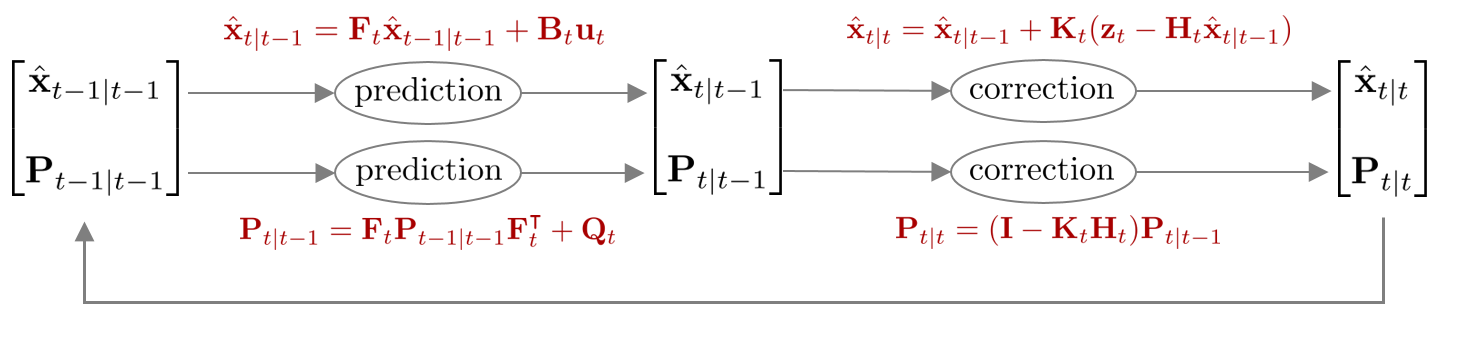

No instante $t$, a posição do robô é $\mathbf x_t$, a medida do sensor é $\mathbf z_t$ e o controle é $\mathbf u_t$. Com eles definimos os modelos de movimento e de observação, com a restrição de que **ambos sejam lineares**:

$$\text{Movimento:}\quad \mathbf x_t=\mathbf F_t\mathbf x_{t-1}+\mathbf B_t\mathbf u_t+\mathbf w_t\qquad\qquad \text{Observação:}\quad \mathbf z_t=\mathbf H_t\mathbf x_t+\mathbf v_t$$

- $\mathbf F_t$: matriz de transição de estado; $\mathbf B_t$: matriz que leva o controle $\mathbf u_t$ ao espaço do estado; $\mathbf H_t$: matriz de observação;
- $\mathbf w_t\sim\mathcal N(0,\mathbf Q_t)$: ruído do modelo de movimento, com covariância $\mathbf Q_t$;
- $\mathbf v_t\sim\mathcal N(0,\mathbf R_t)$: ruído do modelo de observação, com covariância $\mathbf R_t$.

Supondo todas as variáveis gaussianas,

$$p(\mathbf x_t\mid\mathbf x_{t-1},\mathbf u_t)=\mathcal N(\mathbf F_t\mathbf x_{t-1}+\mathbf B_t\mathbf u_t,\ \mathbf Q_t),\qquad p(\mathbf z_t\mid\mathbf x_t)=\mathcal N(\mathbf H_t\mathbf x_t,\ \mathbf R_t),$$

cada uma com a densidade usual $\det(2\pi\boldsymbol\Sigma)^{-1/2}\exp\!\big(-\tfrac12(\cdot)^\top\boldsymbol\Sigma^{-1}(\cdot)\big)$. O filtro precisa calcular

$$\overline{\mathrm{bel}}(\mathbf x_t)=\int p(\mathbf x_t\mid\mathbf x_{t-1},\mathbf u_t)\,\mathrm{bel}(\mathbf x_{t-1})\,d\mathbf x_{t-1}\sim\mathcal N(\hat{\mathbf x}_{t|t-1},\mathbf P_{t|t-1}),\qquad \mathrm{bel}(\mathbf x_t)=\eta\,p(\mathbf z_t\mid\mathbf x_t)\,\overline{\mathrm{bel}}(\mathbf x_t)\sim\mathcal N(\hat{\mathbf x}_{t|t},\mathbf P_{t|t}).$$

Primeiro a predição calcula $\overline{\mathrm{bel}}(\mathbf x_t)$ com o valor anterior e o modelo de movimento; depois a correção calcula $\mathrm{bel}(\mathbf x_t)$ com a medida e o modelo de observação. **Substituindo as duas densidades nessas integrais, obtêm-se as médias e covariâncias** $(\hat{\mathbf x}_{t|t-1},\mathbf P_{t|t-1})$ e $(\hat{\mathbf x}_{t|t},\mathbf P_{t|t})$; a dedução está na seção 8.

O valor inicial é $\mathrm{bel}(\mathbf x_0)\sim\mathcal N(\hat{\mathbf x}_0,\mathbf P_0)$:
- $\hat{\mathbf x}_0$: tipicamente 0;
- $\mathbf P_0$: segundo o original, "tipicamente um valor pequeno ($<10^{-2}$)". **Veja a nota do tradutor logo abaixo.**

### Predição

$$\boxed{\hat{\mathbf x}_{t|t-1}=\mathbf F_t\hat{\mathbf x}_{t-1|t-1}+\mathbf B_t\mathbf u_t,\qquad \mathbf P_{t|t-1}=\mathbf F_t\mathbf P_{t-1|t-1}\mathbf F_t^\top+\mathbf Q_t}$$

### Correção ($\mathbf K_t$ é o ganho de Kalman)

$$\boxed{\mathbf K_t=\mathbf P_{t|t-1}\mathbf H_t^\top(\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top+\mathbf R_t)^{-1},\qquad \hat{\mathbf x}_{t|t}=\hat{\mathbf x}_{t|t-1}+\mathbf K_t(\mathbf z_t-\mathbf H_t\hat{\mathbf x}_{t|t-1}),\qquad \mathbf P_{t|t}=(\mathbf I-\mathbf K_t\mathbf H_t)\mathbf P_{t|t-1}}$$

In [4]:
def kf_predicao(x, P, F, Q, B=None, u=None):
    x = F @ x + (B @ u if B is not None else 0.0)
    P = F @ P @ F.T + Q
    return x, P

def kf_correcao(x, P, z, H, R):
    S = H @ P @ H.T + R                       # covariância da inovação
    K = np.linalg.solve(S, H @ P).T           # K = P Hᵀ S⁻¹, sem inverter S
    x = x + K @ (z - H @ x)
    P = (np.eye(len(x)) - K @ H) @ P
    return x, 0.5 * (P + P.T), K

# exemplo nD: posição e velocidade com aceleração comandada (u) e radar de posição
DT_KF = 0.5
F_cv = np.array([[1, DT_KF], [0, 1.0]]); B_cv = np.array([[DT_KF**2 / 2], [DT_KF]])
Q_cv = 0.3**2 * B_cv @ B_cv.T;           H_cv = np.array([[1.0, 0.0]]); R_cv = np.array([[3.0**2]])

def simula_cv(T, x0, rng):
    X = np.zeros((T, 2)); Z = np.zeros((T, 1)); U = np.zeros((T, 1)); X[0] = x0
    U[20:40] = 1.0; U[70:90] = -1.0
    for t in range(1, T):
        X[t] = F_cv @ X[t - 1] + (B_cv @ (U[t] + 0.3 * rng.standard_normal(1)))
        Z[t] = H_cv @ X[t] + 3.0 * rng.standard_normal(1)
    return X, Z, U

def roda_kf(Z, U, x0, P0):
    x, P = np.array(x0, float), np.array(P0, float)
    xs_, Ps_ = [x], [P]
    for t in range(1, len(Z)):
        x, P = kf_predicao(x, P, F_cv, Q_cv, B_cv, U[t])
        x, P, _ = kf_correcao(x, P, Z[t], H_cv, R_cv)
        xs_.append(x); Ps_.append(P)
    return np.array(xs_), np.array(Ps_)

X_cv, Z_cv, U_cv = simula_cv(120, [50.0, 4.0], rng)

> **Nota do tradutor: "$\mathbf P_0$ tipicamente pequeno ($<10^{-2}$)" é um mau conselho.** $\mathbf P_0$ é a **incerteza** sobre $\hat{\mathbf x}_0$, e deve ser grande quando $\hat{\mathbf x}_0$ é um chute (como $\hat{\mathbf x}_0=0$). Com $\mathbf P_0$ pequeno e $\hat{\mathbf x}_0$ errado, o filtro começa **confiante no valor errado**: o ganho fica pequeno, as medidas são quase ignoradas e a covariância reportada não cobre o erro verdadeiro. A regra correta é o oposto: **$\hat{\mathbf x}_0=0$ pede $\mathbf P_0$ grande**. Um $\mathbf P_0$ pequeno só se justifica quando o estado inicial é realmente conhecido (por exemplo, um robô que parte de uma base com posição medida).
>
> A célula abaixo mostra o efeito. O carro começa em $x=50$ m com velocidade 4 m/s, e o filtro começa em $\hat{\mathbf x}_0=0$.

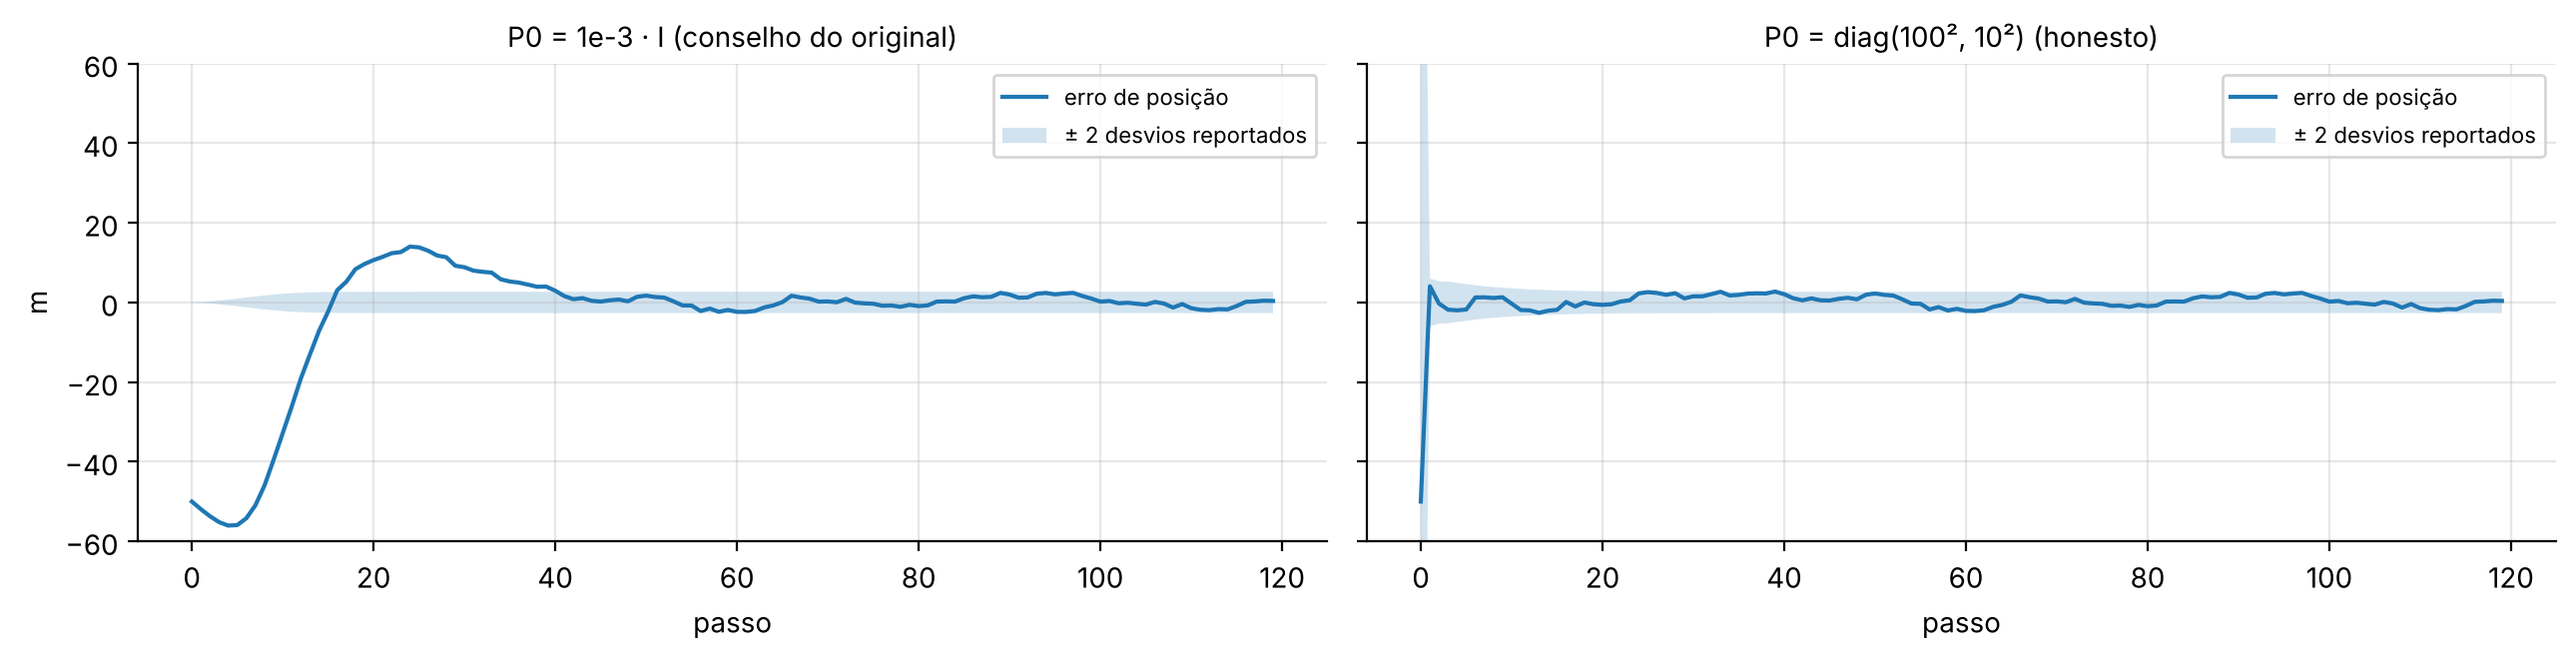

,P0 = 1e-3 · I (conselho do original),"P0 = diag(100², 10²) (honesto)"
"|erro| médio, passos 1–20 (m)",30.03,1.39
"|erro| médio, passos 60–120 (m)",1.02,1.01
"NEES médio, passos 1–20 (ideal ≈ 2)",178233.93,1.24


In [5]:
res = {}
for nome, P0 in {"P0 = 1e-3 · I (conselho do original)": 1e-3 * np.eye(2),
                 "P0 = diag(100², 10²) (honesto)":       np.diag([100.0**2, 10.0**2])}.items():
    Xh, Ph = roda_kf(Z_cv, U_cv, [0.0, 0.0], P0)
    erro = Xh[:, 0] - X_cv[:, 0]
    nees = np.array([(Xh[t] - X_cv[t]) @ np.linalg.solve(Ph[t], Xh[t] - X_cv[t]) for t in range(len(Xh))])
    res[nome] = dict(erro=erro, sd=np.sqrt(Ph[:, 0, 0]),
                     **{"|erro| médio, passos 1–20 (m)": np.abs(erro[1:21]).mean(),
                        "|erro| médio, passos 60–120 (m)": np.abs(erro[60:]).mean(),
                        "NEES médio, passos 1–20 (ideal ≈ 2)": nees[1:21].mean()})

fig, ax = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
for a, (nome, r) in zip(ax, res.items()):
    a.plot(r["erro"], label="erro de posição"); a.fill_between(range(120), -2 * r["sd"], 2 * r["sd"], alpha=.2, label="± 2 desvios reportados")
    a.set_title(nome, fontsize=10); a.set_xlabel("passo"); a.set_ylim(-60, 60); a.legend(fontsize=8)
ax[0].set_ylabel("m"); plt.tight_layout(); plt.show()
pd.DataFrame({k: {c: v for c, v in r.items() if c not in ("erro", "sd")} for k, r in res.items()}).round(2)

**Leitura.** Com $\mathbf P_0$ pequeno, o filtro leva dezenas de passos para "acreditar" nas medidas e, durante esse tempo, a faixa de $\pm2$ desvios que ele reporta é muito mais estreita que o erro real (NEES muito acima de 2, o valor esperado para um estado de dimensão 2). Com $\mathbf P_0$ honesto, o primeiro radar já puxa a estimativa para perto da verdade. No regime permanente, os dois filtros esquecem a condição inicial e ficam iguais: o dano de um $\mathbf P_0$ ruim é **transitório**, mas pode ser grande.

## 3.1 O filtro de Kalman 1D

Até aqui o estado era um vetor ($\mathbf x_t$). No filtro 1D o estado é um escalar ($x_t$); fora isso, tudo é igual. As crenças são

$$\overline{\mathrm{bel}}(x_t)\sim\mathcal N(\bar\mu_t,\bar\sigma_t^2),\qquad \mathrm{bel}(x_t)\sim\mathcal N(\mu_t,\sigma_t^2),$$

e os modelos,

$$\text{Movimento:}\quad x_t=x_{t-1}+u_t+w_t,\ \ w_t\sim\mathcal N(0,\sigma^2_{\text{mov},t})\qquad\qquad \text{Observação:}\quad z_t=x_t+v_t,\ \ v_t\sim\mathcal N(0,\sigma^2_{\text{obs},t}).$$

> **Nota do tradutor.** O original escreve $x_t=x_{t-1}+u_t+\sigma^2_{\text{motion},t}$, como se a **variância** fosse somada ao estado. O que se soma é um **ruído** cuja variância é $\sigma^2$; corrigido acima.

Predição:
$$\boxed{\bar\mu_t=\mu_{t-1}+u_t,\qquad \bar\sigma_t^2=\sigma_{t-1}^2+\sigma^2_{\text{mov},t}}$$

Correção:
$$\boxed{K_t=\frac{\bar\sigma_t^2}{\bar\sigma_t^2+\sigma^2_{\text{obs},t}},\qquad \mu_t=\bar\mu_t+K_t(z_t-\bar\mu_t)=\frac{z_t\,\bar\sigma_t^2+\bar\mu_t\,\sigma^2_{\text{obs},t}}{\bar\sigma_t^2+\sigma^2_{\text{obs},t}},\qquad \sigma_t^2=(1-K_t)\bar\sigma_t^2=\frac{\bar\sigma_t^2\,\sigma^2_{\text{obs},t}}{\bar\sigma_t^2+\sigma^2_{\text{obs},t}}}$$

(o original chama a medida de $\mu_{\text{obs},t}$; aqui ela é $z_t$.) As equações são estruturalmente idênticas às da versão vetorial: $\mathbf F_t,\mathbf B_t,\mathbf H_t$ viram 1 e são omitidas, e $\mathbf Q_t\leftrightarrow\sigma^2_{\text{mov},t}$, $\mathbf R_t\leftrightarrow\sigma^2_{\text{obs},t}$. A comparação lado a lado:

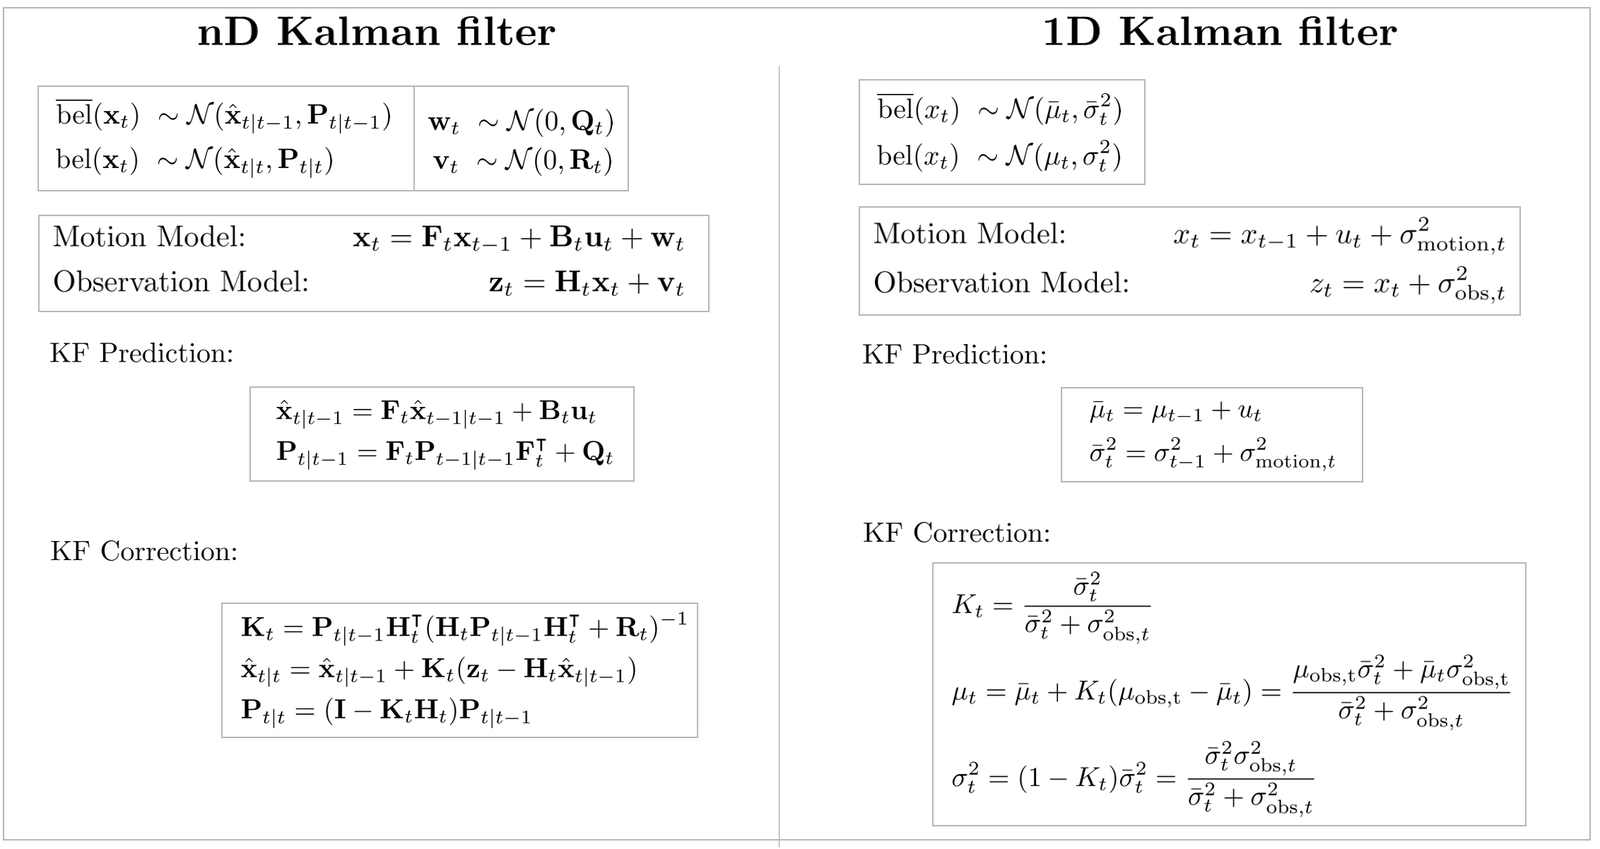

In [6]:
# o mesmo problema da grade (seção 2), resolvido pelas fórmulas 1D e pelas funções matriciais
mu, s2 = 0.0, 1.0
x_m, P_m = np.array([0.0]), np.array([[1.0]])
for t in range(1, T_GRADE + 1):
    # 1D
    mu_b, s2_b = mu + u_g[t - 1], s2 + SIG_MOV**2
    K1 = s2_b / (s2_b + SIG_OBS**2)
    mu, s2 = (z_g[t] * s2_b + mu_b * SIG_OBS**2) / (s2_b + SIG_OBS**2), s2_b * SIG_OBS**2 / (s2_b + SIG_OBS**2)
    # nD com matrizes 1x1
    x_m, P_m = kf_predicao(x_m, P_m, np.eye(1), np.array([[SIG_MOV**2]]), np.eye(1), np.array([u_g[t - 1]]))
    x_m, P_m, _ = kf_correcao(x_m, P_m, np.array([z_g[t]]), np.eye(1), np.array([[SIG_OBS**2]]))
confere("KF 1D (forma de média ponderada) = KF nD com matrizes 1×1 (média)", mu, x_m[0], tol=1e-12)
confere("KF 1D = KF nD (variância)", s2, P_m[0, 0], tol=1e-12)

OK   KF 1D (forma de média ponderada) = KF nD com matrizes 1×1 (média):  diferença máxima = 7.11e-15
OK   KF 1D = KF nD (variância):  diferença máxima = 0.00e+00


## 3.2 Discussão

### O KF e a densidade a posteriori

Considere estimar com um KF a posição $x_t$ de um robô num espaço 1D. O eixo vertical é a densidade de probabilidade; o horizontal, a posição.

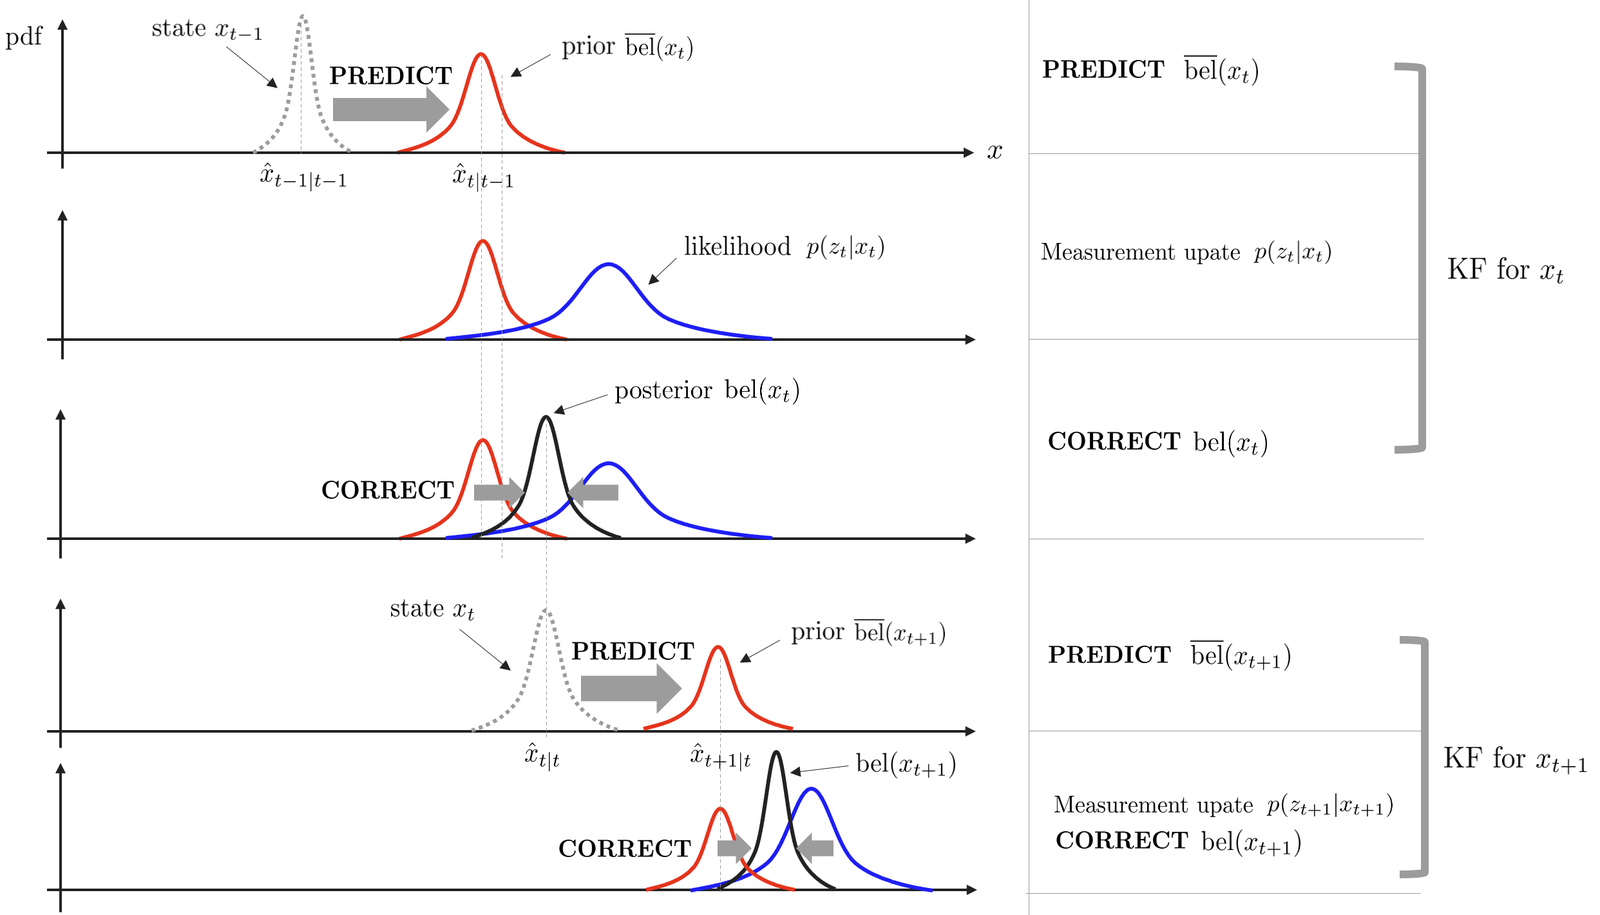

Passo a passo:
1. O robô faz a predição com o modelo de movimento, a partir da posição anterior $x_{t-1}$, e obtém o *a priori* $\overline{\mathrm{bel}}(x_t)$.
2. O robô mede a posição com o sensor e obtém a verossimilhança $p(z_t\mid x_t)$.
3. Com o *a priori* e a verossimilhança, a correção produz o *a posteriori* $\mathrm{bel}(x_t)$.
4. Repetem-se os passos 1 a 3 para obter $\mathrm{bel}(x_{t+1})$.

Portanto, um passo do KF tem a forma típica de um filtro bayesiano: **prevê o *a priori* a partir do estado anterior (predição), calcula a verossimilhança quando chega a observação, e obtém o *a posteriori* pela regra de Bayes (correção)**. Fazer essa filtragem bayesiana **recursivamente** com **crenças gaussianas** é o filtro de Kalman.

A célula seguinte refaz a figura com os números do exemplo da seção 2.

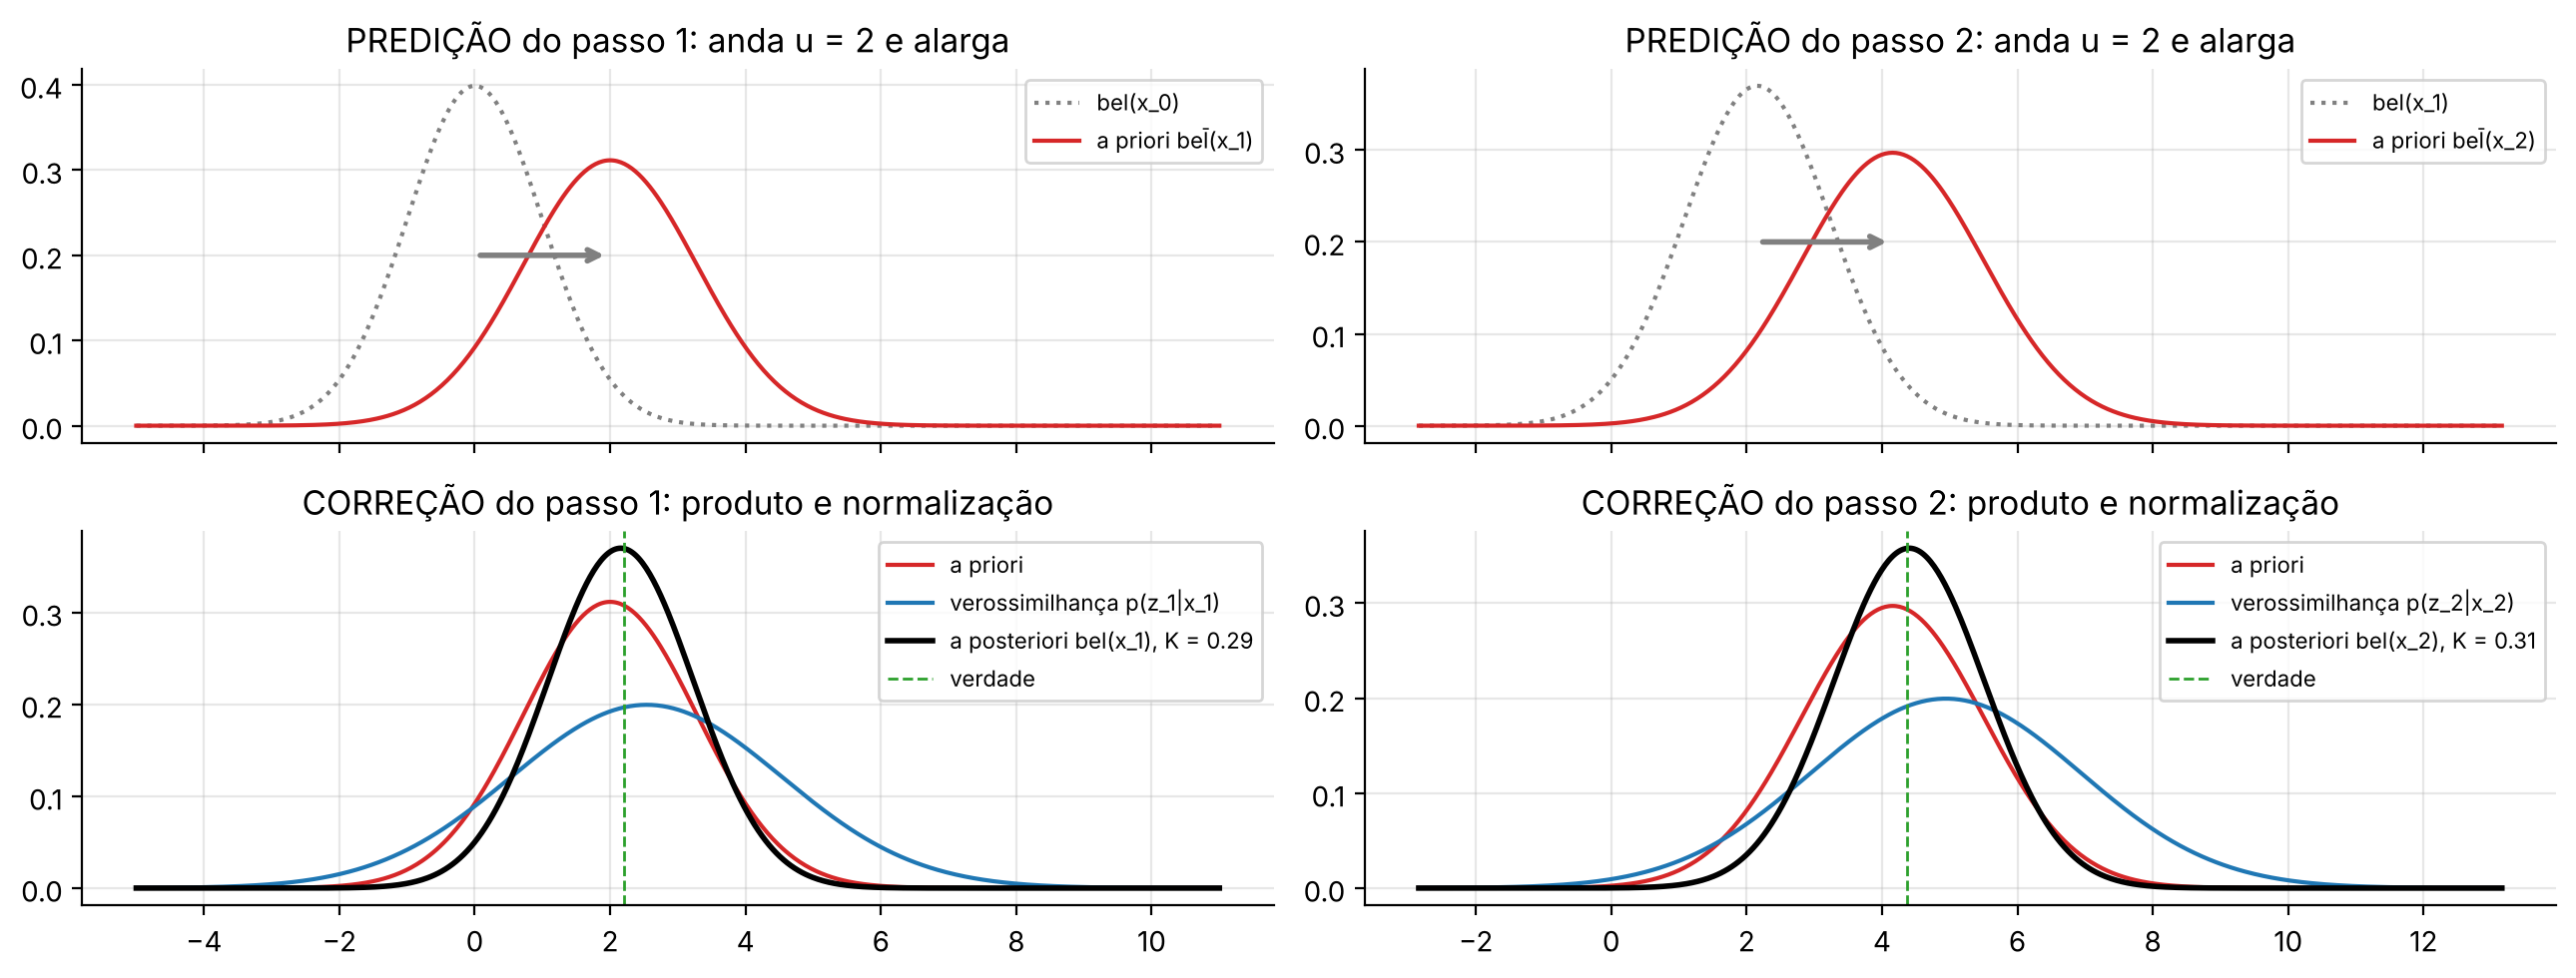

In [7]:
fig, axs = plt.subplots(2, 2, figsize=(13, 5), sharex="col")
mu, s2 = 0.0, 1.0
for t in range(1, 3):
    mu_b, s2_b = mu + u_g[t - 1], s2 + SIG_MOV**2
    K1 = s2_b / (s2_b + SIG_OBS**2)
    mu_n, s2_n = mu_b + K1 * (z_g[t] - mu_b), (1 - K1) * s2_b
    r = np.linspace(mu - 5, mu_b + 9, 600)
    a = axs[0, t - 1]
    a.plot(r, gauss(r, mu, s2), ":", color="gray", label=f"bel(x_{t-1})")
    a.plot(r, gauss(r, mu_b, s2_b), color="tab:red", label=f"a priori bel̄(x_{t})")
    a.annotate("", xy=(mu_b, 0.2), xytext=(mu, 0.2), arrowprops=dict(arrowstyle="->", lw=2, color="gray"))
    a.set_title(f"PREDIÇÃO do passo {t}: anda u = {u_g[t-1]:.0f} e alarga"); a.legend(fontsize=8)
    a = axs[1, t - 1]
    a.plot(r, gauss(r, mu_b, s2_b), color="tab:red", label="a priori")
    a.plot(r, gauss(r, z_g[t], SIG_OBS**2), color="tab:blue", label=f"verossimilhança p(z_{t}|x_{t})")
    a.plot(r, gauss(r, mu_n, s2_n), "k", lw=2, label=f"a posteriori bel(x_{t}), K = {K1:.2f}")
    a.axvline(x_v[t], color="tab:green", ls="--", lw=1, label="verdade")
    a.set_title(f"CORREÇÃO do passo {t}: produto e normalização"); a.legend(fontsize=8)
    mu, s2 = mu_n, s2_n
plt.tight_layout(); plt.show()

### O ganho de Kalman

Na correção, a média $\hat{\mathbf x}_{t|t}$ pondera de forma diferente a predição e a medida, conforme o ganho $\mathbf K_t$:

$$\hat{\mathbf x}_{t|t}=\underbrace{\hat{\mathbf x}_{t|t-1}}_{\text{predição}}+\mathbf K_t\underbrace{(\mathbf z_t-\mathbf H_t\hat{\mathbf x}_{t|t-1})}_{\text{inovação}}$$

- **inovação:** a diferença entre o valor observado $\mathbf z_t$ e o valor previsto $\mathbf H_t\hat{\mathbf x}_{t|t-1}$, isto é, o erro de previsão da medida.

Se $\mathbf K_t\to\mathbf 0$, a medida não é levada em conta e só a predição do sistema importa. Se $\mathbf K_t\to\mathbf 1$, confia-se 100% no sensor e a predição é ignorada.

Além disso, quando o ruído do sensor $\mathbf R$ é grande, $\mathbf K_t$ diminui: a predição pesa mais que a medida. Quando o ruído do sistema $\mathbf Q$ é grande, $\mathbf P_{t|t-1}$ cresce, $\mathbf K_t$ aumenta, e a medida pesa mais:

$$\mathbf P_{t|t-1}=\mathbf F_t\mathbf P_{t-1|t-1}\mathbf F_t^\top+{\color{teal}\mathbf Q_t},\qquad \mathbf K_t=\mathbf P_{t|t-1}\mathbf H_t^\top(\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top+{\color{red}\mathbf R_t})^{-1}$$

- ${\color{red}\mathbf R_t}\uparrow\ \Rightarrow\ (\ast+{\color{red}\mathbf R_t})^{-1}\downarrow\ \Rightarrow\ \mathbf K_t\downarrow$
- ${\color{teal}\mathbf Q_t}\uparrow\ \Rightarrow\ \mathbf P_{t|t-1}\uparrow\ \Rightarrow\ \mathbf K_t\uparrow$

> **Nota do tradutor.** "$\mathbf K_t\to\mathbf 1$" só faz sentido literal no caso escalar com $H=1$. No caso geral, o extremo "confiar só no sensor" é $\mathbf K_t\mathbf H_t\to\mathbf I$ nas direções que o sensor observa; nas direções que o sensor não vê, o ganho é sempre zero, por maior que seja $\mathbf Q$. O gráfico abaixo mostra o ganho **de regime permanente** do exemplo 1D (a solução de Riccati, quando $\sigma^2$ para de mudar) em função de $Q$ e $R$.

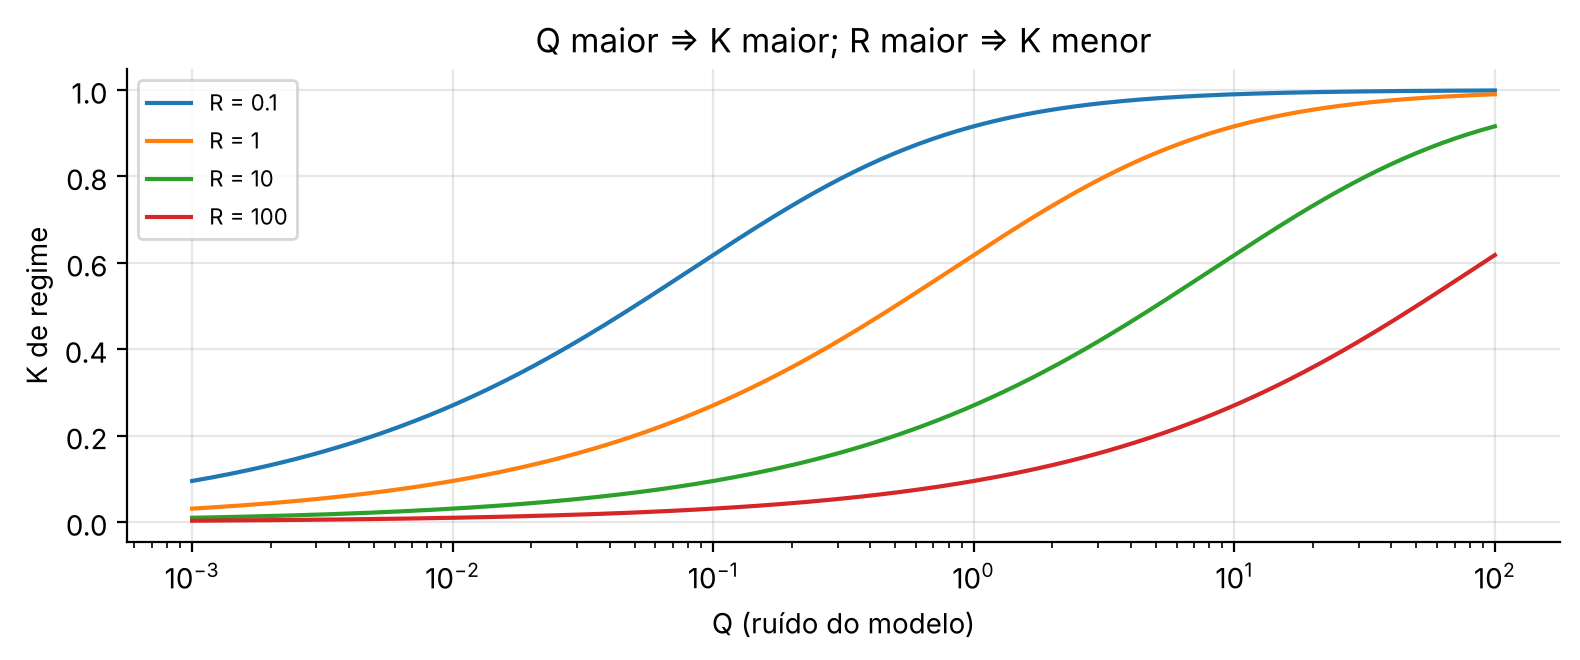

OK   ganho de regime: fórmula fechada = iteração da recursão:  diferença máxima = 5.55e-17


In [8]:
def ganho_permanente_1d(q, r):
    # ponto fixo de s² ← (s² + q) r / (s² + q + r): a predita p = s²+q satisfaz p² - q p - q r = 0
    p = (q + np.sqrt(q**2 + 4 * q * r)) / 2
    return p / (p + r)

qs = np.logspace(-3, 2, 200)
fig, ax = plt.subplots(figsize=(8, 3.4))
for r in [0.1, 1, 10, 100]:
    ax.semilogx(qs, ganho_permanente_1d(qs, r), label=f"R = {r}")
ax.set_xlabel("Q (ruído do modelo)"); ax.set_ylabel("K de regime"); ax.legend(fontsize=8)
ax.set_title("Q maior ⇒ K maior; R maior ⇒ K menor")
plt.tight_layout(); plt.show()

# conferência: iterar a recursão chega ao mesmo ponto fixo
q, r, s2 = 0.5, 4.0, 100.0
for _ in range(500):
    s2_b = s2 + q; K1 = s2_b / (s2_b + r); s2 = (1 - K1) * s2_b
confere("ganho de regime: fórmula fechada = iteração da recursão", K1, ganho_permanente_1d(q, r), tol=1e-12)

## 3.3 Resumo

O filtro de Kalman pode ser escrito como uma função:

$$
\boxed{\begin{aligned}
&\text{FiltroDeKalman}(\hat{\mathbf x}_{t-1|t-1},\mathbf P_{t-1|t-1},\mathbf u_t,\mathbf z_t)\ \{\\
&\qquad\text{(predição)}\quad \hat{\mathbf x}_{t|t-1}=\mathbf F_t\hat{\mathbf x}_{t-1|t-1}+\mathbf B_t\mathbf u_t,\qquad \mathbf P_{t|t-1}=\mathbf F_t\mathbf P_{t-1|t-1}\mathbf F_t^\top+\mathbf Q_t\\
&\qquad\text{(correção)}\quad \mathbf K_t=\mathbf P_{t|t-1}\mathbf H_t^\top(\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top+\mathbf R_t)^{-1},\quad \hat{\mathbf x}_{t|t}=\hat{\mathbf x}_{t|t-1}+\mathbf K_t(\mathbf z_t-\mathbf H_t\hat{\mathbf x}_{t|t-1}),\quad \mathbf P_{t|t}=(\mathbf I-\mathbf K_t\mathbf H_t)\mathbf P_{t|t-1}\\
&\qquad\text{retorna } \hat{\mathbf x}_{t|t},\ \mathbf P_{t|t}\ \}
\end{aligned}}
$$

No código deste notebook, essa função são as duas funções `kf_predicao` e `kf_correcao` definidas acima.

---
# 4. Filtro de Kalman estendido (EKF)

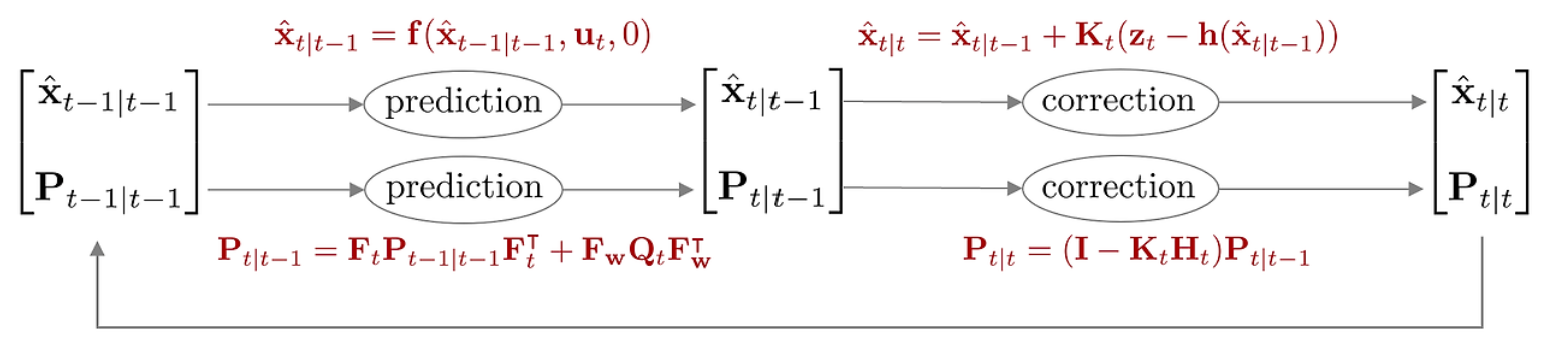

O KF supõe que os modelos de movimento e de observação são lineares. Como a maior parte dos fenômenos do mundo real é não linear, o KF como definido acima não funcionaria. O **filtro de Kalman estendido** (EKF) foi proposto para usar o filtro de Kalman com modelos não lineares. **O EKF usa a aproximação de Taylor de primeira ordem para transformar o modelo não linear em linear antes de aplicar o filtro.** Os modelos do EKF são

$$\text{Movimento:}\quad \mathbf x_t=\mathbf f(\mathbf x_{t-1},\mathbf u_t,\mathbf w_t)\qquad\qquad \text{Observação:}\quad \mathbf z_t=\mathbf h(\mathbf x_t,\mathbf v_t),$$

com $\mathbf f(\cdot)$ e $\mathbf h(\cdot)$ não lineares, $\mathbf w_t\sim\mathcal N(0,\mathbf Q_t)$ e $\mathbf v_t\sim\mathcal N(0,\mathbf R_t)$. Repare que agora os ruídos podem entrar **dentro** das funções. A aproximação de Taylor de primeira ordem dá

$$\mathbf x_t\approx\mathbf f(\hat{\mathbf x}_{t-1|t-1},\mathbf u_t,0)+\mathbf F_t(\mathbf x_{t-1}-\hat{\mathbf x}_{t-1|t-1})+\mathbf F_{\mathbf w}\mathbf w_t,\qquad \mathbf z_t\approx\mathbf h(\hat{\mathbf x}_{t|t-1},0)+\mathbf H_t(\mathbf x_t-\hat{\mathbf x}_{t|t-1})+\mathbf H_{\mathbf v}\mathbf v_t .$$

$\mathbf F_t$ é o jacobiano do modelo de movimento calculado em $\hat{\mathbf x}_{t-1|t-1}$; $\mathbf H_t$, o do modelo de observação calculado em $\hat{\mathbf x}_{t|t-1}$; $\mathbf F_{\mathbf w}$ e $\mathbf H_{\mathbf v}$ são os jacobianos **em relação aos ruídos**, calculados em ruído zero:

$$\mathbf F_t=\frac{\partial\mathbf f}{\partial\mathbf x_{t-1}}\Big|_{\hat{\mathbf x}_{t-1|t-1}},\quad \mathbf F_{\mathbf w}=\frac{\partial\mathbf f}{\partial\mathbf w_t}\Big|_{\hat{\mathbf x}_{t-1|t-1},\,\mathbf w_t=0},\qquad \mathbf H_t=\frac{\partial\mathbf h}{\partial\mathbf x_t}\Big|_{\hat{\mathbf x}_{t|t-1}},\quad \mathbf H_{\mathbf v}=\frac{\partial\mathbf h}{\partial\mathbf v_t}\Big|_{\hat{\mathbf x}_{t|t-1},\,\mathbf v_t=0}.$$

Reorganizando,

$$\boxed{\mathbf x_t=\mathbf F_t\mathbf x_{t-1}+\tilde{\mathbf u}_t+\tilde{\mathbf w}_t,\qquad \mathbf z_t=\mathbf H_t\mathbf x_t+\tilde{\mathbf z}_t+\tilde{\mathbf v}_t}$$

- $\tilde{\mathbf u}_t=\mathbf f(\hat{\mathbf x}_{t-1|t-1},\mathbf u_t,0)-\mathbf F_t\hat{\mathbf x}_{t-1|t-1}$, $\quad\tilde{\mathbf w}_t=\mathbf F_{\mathbf w}\mathbf w_t\sim\mathcal N(0,\mathbf F_{\mathbf w}\mathbf Q_t\mathbf F_{\mathbf w}^\top)$;
- $\tilde{\mathbf z}_t=\mathbf h(\hat{\mathbf x}_{t|t-1},0)-\mathbf H_t\hat{\mathbf x}_{t|t-1}$, $\quad\tilde{\mathbf v}_t=\mathbf H_{\mathbf v}\mathbf v_t\sim\mathcal N(0,\mathbf H_{\mathbf v}\mathbf R_t\mathbf H_{\mathbf v}^\top)$.

O modelo linearizado é um modelo de KF com entrada conhecida $\tilde{\mathbf u}_t$, medida deslocada por $\tilde{\mathbf z}_t$ e covariâncias de ruído $\mathbf F_{\mathbf w}\mathbf Q_t\mathbf F_{\mathbf w}^\top$ e $\mathbf H_{\mathbf v}\mathbf R_t\mathbf H_{\mathbf v}^\top$. Daí, exatamente como no KF:

### Predição
$$\boxed{\hat{\mathbf x}_{t|t-1}=\mathbf f(\hat{\mathbf x}_{t-1|t-1},\mathbf u_t,0),\qquad \mathbf P_{t|t-1}=\mathbf F_t\mathbf P_{t-1|t-1}\mathbf F_t^\top+\mathbf F_{\mathbf w}\mathbf Q_t\mathbf F_{\mathbf w}^\top}$$

### Correção
$$\boxed{\mathbf K_t=\mathbf P_{t|t-1}\mathbf H_t^\top(\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top+\mathbf H_{\mathbf v}\mathbf R_t\mathbf H_{\mathbf v}^\top)^{-1},\qquad \hat{\mathbf x}_{t|t}=\hat{\mathbf x}_{t|t-1}+\mathbf K_t\big(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t-1},0)\big),\qquad \mathbf P_{t|t}=(\mathbf I-\mathbf K_t\mathbf H_t)\mathbf P_{t|t-1}}$$

(Repare: a média é propagada pela função **não linear**; só as covariâncias usam os jacobianos.) O valor inicial é o mesmo do KF, e vale a mesma nota do tradutor sobre $\mathbf P_0$.

### Acréscimo: um robô de duas rodas e um farol

Para ver todos os jacobianos, inclusive os de ruído, usamos um exemplo clássico de robótica.
- **Estado:** $\mathbf x=(p_x,p_y,\theta)$, posição e orientação.
- **Controle:** $\mathbf u=(v,\omega)$, velocidade linear e angular comandadas.
- **Ruído de movimento:** entra **no controle**, $\mathbf w=(w_v,w_\omega)$. O robô executa $v+w_v$ e $\omega+w_\omega$, e por isso $\mathbf F_{\mathbf w}$ é uma matriz $3\times2$, diferente da identidade.
- **Movimento:** $p_x\leftarrow p_x+(v+w_v)\Delta t\cos\theta$, $\ p_y\leftarrow p_y+(v+w_v)\Delta t\sin\theta$, $\ \theta\leftarrow\theta+(\omega+w_\omega)\Delta t$.
- **Observação:** distância e direção (*range* e *bearing*) até um farol de posição conhecida $\mathbf L$. O erro da distância é **proporcional** à distância, $d(1+v_d)$, como num sensor de tempo de voo barato. Por isso $\mathbf H_{\mathbf v}=\mathrm{diag}(d,1)$ depende do estado.

Primeiro conferimos os jacobianos analíticos contra derivadas numéricas; depois rodamos o EKF.

In [9]:
DT_R = 0.1
FAROIS = np.array([[10.0, 0.0], [0.0, 12.0], [-8.0, -6.0]])

def wrap(a):
    return (a + np.pi) % (2 * np.pi) - np.pi

def f_rob(x, u, w):
    v, om = u[0] + w[0], u[1] + w[1]
    return np.array([x[0] + v * DT_R * np.cos(x[2]), x[1] + v * DT_R * np.sin(x[2]), x[2] + om * DT_R])

def F_rob(x, u):                    # ∂f/∂x em w = 0
    return np.array([[1, 0, -u[0] * DT_R * np.sin(x[2])], [0, 1, u[0] * DT_R * np.cos(x[2])], [0, 0, 1.0]])

def Fw_rob(x, u):                   # ∂f/∂w em w = 0  (3 × 2)
    return np.array([[DT_R * np.cos(x[2]), 0], [DT_R * np.sin(x[2]), 0], [0, DT_R]])

def h_rob(x, v, L):
    d = np.hypot(L[0] - x[0], L[1] - x[1])
    return np.array([d * (1 + v[0]), wrap(np.arctan2(L[1] - x[1], L[0] - x[0]) - x[2] + v[1])])

def H_rob(x, L):                    # ∂h/∂x em v = 0  (2 × 3)
    dx_, dy_ = L[0] - x[0], L[1] - x[1]; q = dx_**2 + dy_**2; d = np.sqrt(q)
    return np.array([[-dx_ / d, -dy_ / d, 0], [dy_ / q, -dx_ / q, -1.0]])

def Hv_rob(x, L):                   # ∂h/∂v em v = 0  (2 × 2)
    return np.diag([np.hypot(L[0] - x[0], L[1] - x[1]), 1.0])

x_t, u_t, L_t = np.array([1.0, -2.0, 0.7]), np.array([1.5, 0.3]), FAROIS[0]
confere("F  analítico = numérico", F_rob(x_t, u_t), jacobiano_numerico(lambda x: f_rob(x, u_t, [0, 0]), x_t), tol=1e-7)
confere("Fw analítico = numérico", Fw_rob(x_t, u_t), jacobiano_numerico(lambda w: f_rob(x_t, u_t, w), [0.0, 0.0]), tol=1e-7)
confere("H  analítico = numérico", H_rob(x_t, L_t), jacobiano_numerico(lambda x: h_rob(x, [0, 0], L_t), x_t), tol=1e-7)
confere("Hv analítico = numérico", Hv_rob(x_t, L_t), jacobiano_numerico(lambda v: h_rob(x_t, v, L_t), [0.0, 0.0]), tol=1e-7)

OK   F  analítico = numérico:  diferença máxima = 2.88e-11
OK   Fw analítico = numérico:  diferença máxima = 2.64e-11
OK   H  analítico = numérico:  diferença máxima = 9.97e-10
OK   Hv analítico = numérico:  diferença máxima = 5.31e-10


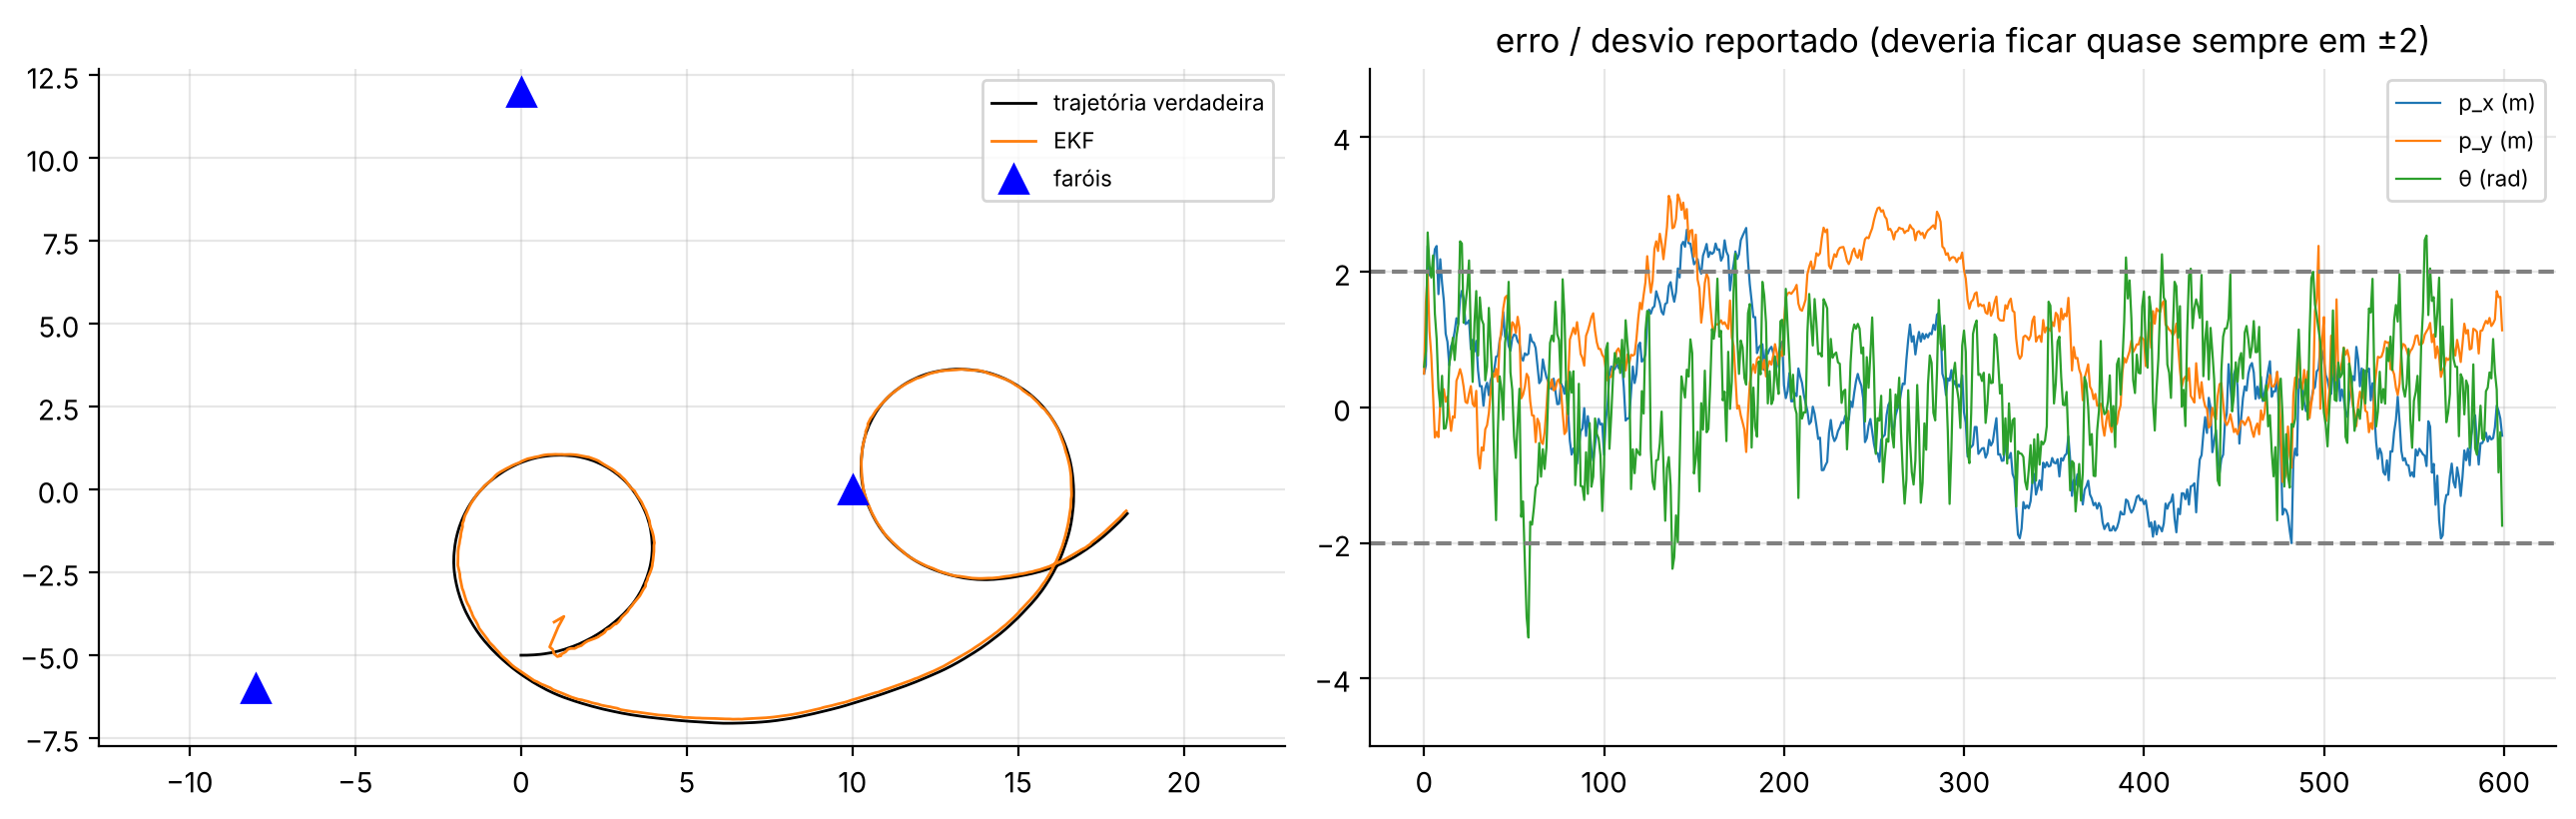

NEES médio (passos 50 em diante): 4.37   (ideal = dimensão do estado = 3)
fração de passos com erro normalizado de posição dentro de ±2: 86.5%  (ideal ≈ 95 %)


In [10]:
Q_rob = np.diag([0.15**2, 0.08**2])        # ruído em (v, ω)
R_rob = np.diag([0.05**2, 0.03**2])        # 5 % na distância; 0,03 rad na direção
T_R = 600

def simula_robo(rng):
    X = np.zeros((T_R, 3)); U = np.zeros((T_R, 2)); Zs = [None]
    X[0] = [0.0, -5.0, 0.0]
    for t in range(1, T_R):
        U[t] = [1.0, 0.2 + 0.15 * np.sin(t / 60)]
        X[t] = f_rob(X[t - 1], U[t], rng.multivariate_normal([0, 0], Q_rob))
        L = FAROIS[t % len(FAROIS)]                     # um farol por passo, em rodízio
        Zs.append((L, h_rob(X[t], rng.multivariate_normal([0, 0], R_rob), L)))
    return X, U, Zs

def ekf_predicao(x, P, u):
    F, Fw = F_rob(x, u), Fw_rob(x, u)
    return f_rob(x, u, [0, 0]), F @ P @ F.T + Fw @ Q_rob @ Fw.T

def ekf_correcao(x, P, z, L):
    H, Hv = H_rob(x, L), Hv_rob(x, L)
    S = H @ P @ H.T + Hv @ R_rob @ Hv.T
    K = np.linalg.solve(S, H @ P).T
    inov = z - h_rob(x, [0, 0], L); inov[1] = wrap(inov[1])     # ângulo: diferença no círculo
    x = x + K @ inov; x[2] = wrap(x[2])
    P = (np.eye(3) - K @ H) @ P
    return x, 0.5 * (P + P.T)

def roda_ekf(U, Zs, x0, P0):
    x, P = np.array(x0, float), np.array(P0, float); out = [(x, P)]
    for t in range(1, len(U)):
        x, P = ekf_predicao(x, P, U[t])
        L, z = Zs[t]
        x, P = ekf_correcao(x, P, z, L)
        out.append((x, P))
    return np.array([o[0] for o in out]), np.array([o[1] for o in out])

X_rob, U_rob, Z_rob = simula_robo(rng)
x0_rob, P0_rob = np.array([1.0, -4.0, 0.3]), np.diag([2.0**2, 2.0**2, 0.5**2])
Xe, Pe = roda_ekf(U_rob, Z_rob, x0_rob, P0_rob)

def erro_estado(Xh, X):
    e = Xh - X; e[:, 2] = wrap(e[:, 2]); return e

e_ekf = erro_estado(Xe, X_rob)
nees_ekf = np.array([e_ekf[t] @ np.linalg.solve(Pe[t], e_ekf[t]) for t in range(T_R)])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].plot(X_rob[:, 0], X_rob[:, 1], "k", lw=1, label="trajetória verdadeira")
ax[0].plot(Xe[:, 0], Xe[:, 1], "tab:orange", lw=1, label="EKF")
ax[0].plot(*FAROIS.T, "b^", ms=10, label="faróis"); ax[0].axis("equal"); ax[0].legend(fontsize=8)
for k, nome in enumerate(["p_x (m)", "p_y (m)", "θ (rad)"]):
    ax[1].plot(e_ekf[:, k] / np.sqrt(Pe[:, k, k]), lw=.8, label=nome)
ax[1].axhline(2, ls="--", color="gray"); ax[1].axhline(-2, ls="--", color="gray")
ax[1].set_ylim(-5, 5); ax[1].set_title("erro / desvio reportado (deveria ficar quase sempre em ±2)")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()
print(f"NEES médio (passos 50 em diante): {nees_ekf[50:].mean():.2f}   (ideal = dimensão do estado = 3)")
print(f"fração de passos com erro normalizado de posição dentro de ±2: "
      f"{np.mean(np.abs(e_ekf[50:, :2] / np.sqrt(Pe[50:, [0, 1], [0, 1]])) < 2):.1%}  (ideal ≈ 95 %)")

**Detalhes do código.**
- **`inov[1] = wrap(inov[1])`**: a inovação de um ângulo precisa ser calculada **no círculo**. Sem isso, um erro de $+179°$ contra $-179°$ vira uma inovação de $358°$ e o filtro explode. Este é o primeiro sinal de que **nem todo estado vive num espaço vetorial**, e é exatamente a motivação do ESKF (seção 5).
- **`Hv @ R_rob @ Hv.T`**: como o erro de distância é proporcional à distância, um farol longe dá uma medida pior. O EKF sabe disso através de $\mathbf H_{\mathbf v}$.
- **Resultado:** o NEES médio sai em torno de 4,4 (ideal 3), e cerca de 87 % dos erros normalizados de posição ficam em $\pm2$ (ideal 95 %). O EKF é **levemente otimista**: a linearização subestima a incerteza, sobretudo quando o farol está perto e a direção muda rápido com a posição. É o comportamento típico do EKF, e o mesmo que se viu em `pepe_kalman_parte1_ekf_iekf`.
- **NEES** (*normalized estimation error squared*): $\mathbf e^\top\mathbf P^{-1}\mathbf e$. Se o filtro é honesto, sua média é a dimensão do estado. É a mesma ferramenta usada em `pepe_kalman_parte1_ekf_iekf`.

## 4.1 Resumo

$$
\boxed{\begin{aligned}
&\text{FiltroDeKalmanEstendido}(\hat{\mathbf x}_{t-1|t-1},\mathbf P_{t-1|t-1},\mathbf u_t,\mathbf z_t)\ \{\\
&\qquad\text{(predição)}\quad \hat{\mathbf x}_{t|t-1}=\mathbf f(\hat{\mathbf x}_{t-1|t-1},\mathbf u_t,0),\qquad \mathbf P_{t|t-1}=\mathbf F_t\mathbf P_{t-1|t-1}\mathbf F_t^\top+\mathbf F_{\mathbf w}\mathbf Q_t\mathbf F_{\mathbf w}^\top\\
&\qquad\text{(correção)}\quad \mathbf K_t=\mathbf P_{t|t-1}\mathbf H_t^\top(\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top+\mathbf H_{\mathbf v}\mathbf R_t\mathbf H_{\mathbf v}^\top)^{-1},\quad \hat{\mathbf x}_{t|t}=\hat{\mathbf x}_{t|t-1}+\mathbf K_t(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t-1},0)),\quad \mathbf P_{t|t}=(\mathbf I-\mathbf K_t\mathbf H_t)\mathbf P_{t|t-1}\\
&\qquad\text{retorna } \hat{\mathbf x}_{t|t},\ \mathbf P_{t|t}\ \}
\end{aligned}}
$$

---
# 5. Filtro de Kalman de estado de erro (ESKF)

**Nomenclatura**
- predição: $\overline{\mathrm{bel}}(\delta\mathbf x_t)\sim\mathcal N(\delta\hat{\mathbf x}_{t|t-1},\mathbf P_{t|t-1})$, com $\delta\hat{\mathbf x}_{t|t-1}$ também escrito $\delta\mathbf x_t^-$;
- correção: $\mathrm{bel}(\delta\mathbf x_t)\sim\mathcal N(\delta\hat{\mathbf x}_{t|t},\mathbf P_{t|t})$, com $\delta\hat{\mathbf x}_{t|t}$ também escrito $\delta\mathbf x_t^+$.

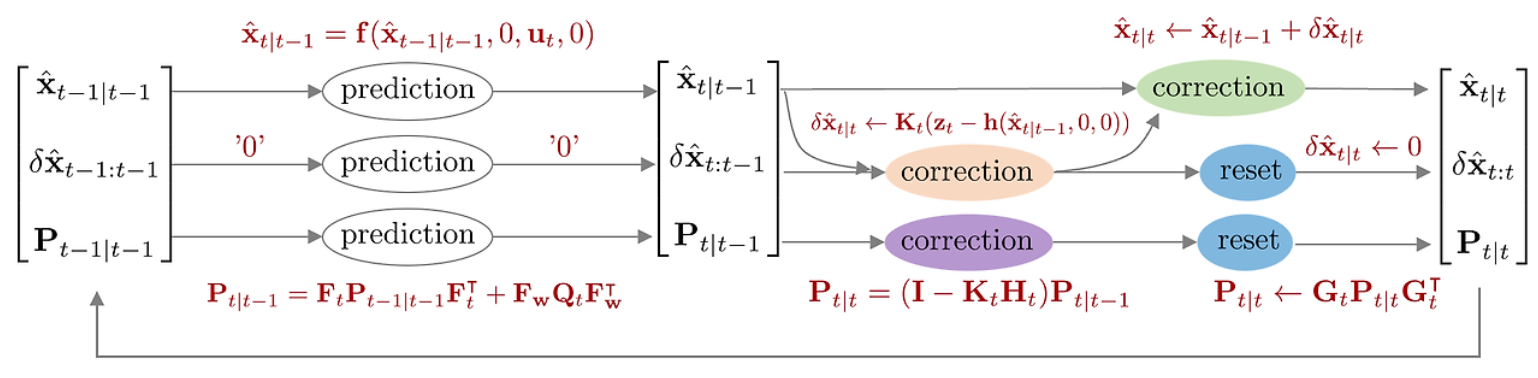

**Ao contrário do EKF, que estima a média e a covariância do estado $\mathbf x_t$, o ESKF estima a média e a covariância do estado de erro $\delta\mathbf x_t$.** Como estima o estado através do erro, e não diretamente, também é chamado de **filtro de Kalman indireto**, ou ES-EKF. No ESKF, o estado "de sempre" é chamado de **estado verdadeiro** e é escrito como a soma de um estado **nominal** e de um estado de **erro**:

$$\mathbf x_{\text{verd},t}=\mathbf x_t+\delta\mathbf x_t$$

- $\mathbf x_{\text{verd},t}$: o estado que o KF e o EKF atualizam;
- $\mathbf x_t$: o estado nominal, isto é, o estado "sem erro";
- $\delta\mathbf x_t$: o estado de erro.

O estado verdadeiro é a soma do nominal com o erro causado pelos ruídos do modelo e do sensor. O nominal tem valores (relativamente) grandes e evolui de forma não linear; o erro tem valores pequenos, perto de zero, e evolui de forma (aproximadamente) linear. Segundo o original, enquanto o EKF lineariza o estado verdadeiro inteiro, "o que o torna lento e acumula erro ao longo do tempo", o ESKF lineariza só o erro, "o que lhe dá velocidade e precisão". As vantagens do ESKF sobre o EKF (Madyastha et al., 2011) são:
- a representação do erro de **orientação** usa o número mínimo de parâmetros (igual aos graus de liberdade), e por isso não há singularidades de sobreparametrização;
- o sistema de erro opera sempre perto da origem, onde é fácil linearizar; singularidades como o *gimbal lock* não aparecem e a linearização é sempre possível;
- como o erro é pequeno, os termos de segunda ordem podem ser desprezados, e os jacobianos ficam simples e rápidos de calcular; alguns podem até ser constantes.

Por outro lado, a predição do ESKF é rápida, mas a correção, onde o estado nominal (não linear e de valores grandes) é processado, é lenta.

> **Nota do tradutor.** As afirmações de velocidade devem ser lidas com cuidado. Para um estado **vetorial** comum, o ESKF faz as **mesmas contas** que o EKF (a seção 5.3 mostra que os números saem idênticos), então não é nem mais rápido nem mais preciso. A vantagem real aparece quando parte do estado é uma **rotação** (ou outro objeto que não é um vetor): o erro $\delta\boldsymbol\theta\in\mathbb R^3$ tem 3 componentes, enquanto um quaternion tem 4 com uma restrição ($\|\mathbf q\|=1$), e ângulos de Euler têm singularidades. "Acumular erros" também não é propriedade do EKF; é consequência de linearizar longe da verdade.

## 5.1 Modelos e linearização

$$\text{Movimento (estado de erro):}\quad \mathbf x_t+\delta\mathbf x_t=\mathbf f(\mathbf x_{t-1},\delta\mathbf x_{t-1},\mathbf u_t,\mathbf w_t)\qquad\qquad \text{Observação:}\quad \mathbf z_t=\mathbf h(\mathbf x_t,\delta\mathbf x_t,\mathbf v_t)$$

com $\mathbf w_t\sim\mathcal N(0,\mathbf Q_t)$ e $\mathbf v_t\sim\mathcal N(0,\mathbf R_t)$. A aproximação de Taylor de primeira ordem (segundo a referência [5] do original) dá

$$\mathbf x_t+\delta\mathbf x_t\approx\mathbf f(\mathbf x_{t-1|t-1},\delta\hat{\mathbf x}_{t-1|t-1},\mathbf u_t,0)+\mathbf F_t(\delta\mathbf x_{t-1}-\delta\hat{\mathbf x}_{t-1|t-1})+\mathbf F_{\mathbf w}\mathbf w_t,$$
$$\mathbf z_t\approx\mathbf h(\mathbf x_{t|t-1},\delta\hat{\mathbf x}_{t|t-1},0)+\mathbf H_t(\delta\mathbf x_t-\delta\hat{\mathbf x}_{t|t-1})+\mathbf H_{\mathbf v}\mathbf v_t .$$

**Atenção: os dois jacobianos, $\mathbf F_t$ e $\mathbf H_t$, são em relação ao estado de erro $\delta\mathbf x_t$, e não ao estado verdadeiro.** Esta é a maior diferença em relação ao EKF:

$$\boxed{\mathbf F_t=\frac{\partial\mathbf f}{\partial\delta\mathbf x_{t-1}}\Big|_{\delta\hat{\mathbf x}_{t-1|t-1}},\quad \mathbf F_{\mathbf w}=\frac{\partial\mathbf f}{\partial\mathbf w_t}\Big|_{\delta\hat{\mathbf x}_{t-1|t-1},\,\mathbf w_t=0},\qquad \mathbf H_t=\frac{\partial\mathbf h}{\partial\delta\mathbf x_t}\Big|_{\delta\hat{\mathbf x}_{t|t-1}},\quad \mathbf H_{\mathbf v}=\frac{\partial\mathbf h}{\partial\mathbf v_t}\Big|_{\delta\hat{\mathbf x}_{t|t-1},\,\mathbf v_t=0}}$$

Pela regra da cadeia,

$$\mathbf H_t=\frac{\partial\mathbf h}{\partial\delta\mathbf x_t}=\frac{\partial\mathbf h}{\partial\mathbf x_{\text{verd},t}}\ \frac{\partial\mathbf x_{\text{verd},t}}{\partial\delta\mathbf x_t}.$$

O primeiro fator é o mesmo jacobiano do EKF; o segundo é novo, e diz como o estado verdadeiro muda quando o erro muda. Para estados vetoriais, com $\mathbf x_{\text{verd}}=\mathbf x+\delta\mathbf x$, ele é a identidade. (Para rotações, veja o resumo do autor sobre *Quaternion kinematics for the error-state Kalman filter*, de Solà, e a seção 5.4.)

Desenvolvendo o modelo de movimento, e usando que $\delta\hat{\mathbf x}_{t-1|t-1}=0$ (ele é zerado na correção anterior):

$$\mathbf x_t+\delta\mathbf x_t=\mathbf F_t\delta\mathbf x_{t-1}+\mathbf f(\mathbf x_{t-1|t-1},0,\mathbf u_t,0)+\mathbf F_{\mathbf w}\mathbf w_t .$$

Por definição, o estado nominal é $\mathbf x_t=\mathbf f(\mathbf x_{t-1},0,\mathbf u_t,0)$; ele se cancela dos dois lados e sobra

$$\boxed{\delta\mathbf x_t=\mathbf F_t\delta\mathbf x_{t-1}+\tilde{\mathbf w}_t,\qquad \tilde{\mathbf w}_t=\mathbf F_{\mathbf w}\mathbf w_t\sim\mathcal N(0,\mathbf F_{\mathbf w}\mathbf Q_t\mathbf F_{\mathbf w}^\top).}$$

Do mesmo modo, na observação,

$$\boxed{\mathbf z_t=\mathbf h(\mathbf x_{t|t-1},0,0)+\mathbf H_t\delta\mathbf x_t+\mathbf H_{\mathbf v}\mathbf v_t .}$$

> **Nota do tradutor.** O original escreve a última linha do modelo de movimento como "$=0+\tilde{\mathbf w}_t$" e a observação como $\mathbf z_t=\tilde{\mathbf z}_t+\tilde{\mathbf v}_t$, isto é, **sem** o termo $\mathbf H_t\delta\mathbf x_t$. Isso confunde a **estimativa** do erro (que é zero antes da correção) com o próprio **erro** (que é aleatório e não é zero). Se o termo $\mathbf H_t\delta\mathbf x_t$ sumisse de fato, a medida não teria nenhuma informação sobre o erro e o ganho seria zero. Por isso, aqui o termo foi mantido.

Daí, $p(\delta\mathbf x_t\mid\delta\mathbf x_{t-1},\mathbf u_t)=\mathcal N(\mathbf F_t\delta\mathbf x_{t-1},\mathbf F_{\mathbf w}\mathbf Q_t\mathbf F_{\mathbf w}^\top)$ e $p(\mathbf z_t\mid\delta\mathbf x_t)=\mathcal N(\mathbf h(\mathbf x_{t|t-1},0,0)+\mathbf H_t\delta\mathbf x_t,\ \mathbf H_{\mathbf v}\mathbf R_t\mathbf H_{\mathbf v}^\top)$. O ESKF funciona como o EKF: a predição calcula $\overline{\mathrm{bel}}(\delta\mathbf x_t)$ e a correção calcula $\mathrm{bel}(\delta\mathbf x_t)$. O valor inicial é $\mathrm{bel}(\delta\mathbf x_0)\sim\mathcal N(0,\mathbf P_0)$: a média do erro é **sempre** zero.

## 5.2 Predição, correção e reset

### Predição
$$\boxed{\delta\hat{\mathbf x}_{t|t-1}=\mathbf F_t\,\delta\hat{\mathbf x}_{t-1|t-1}=0\ \ \leftarrow\text{sempre 0},\qquad \hat{\mathbf x}_{t|t-1}=\mathbf f(\hat{\mathbf x}_{t-1|t-1},0,\mathbf u_t,0),\qquad \mathbf P_{t|t-1}=\mathbf F_t\mathbf P_{t-1|t-1}\mathbf F_t^\top+\mathbf F_{\mathbf w}\mathbf Q_t\mathbf F_{\mathbf w}^\top}$$

$\mathbf F_t$ é o jacobiano do erro. Como o erro estimado é zerado a cada correção, multiplicá-lo por $\mathbf F_t$ continua dando zero: **na predição, $\delta\hat{\mathbf x}$ é sempre 0**. Só o estado nominal $\hat{\mathbf x}_{t|t-1}$ e a covariância do erro $\mathbf P_{t|t-1}$ mudam.

### Correção
$$\boxed{\begin{aligned}
&\mathbf K_t=\mathbf P_{t|t-1}\mathbf H_t^\top(\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top+\mathbf H_{\mathbf v}\mathbf R_t\mathbf H_{\mathbf v}^\top)^{-1}\\
&\delta\hat{\mathbf x}_{t|t}=\mathbf K_t\big(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t-1},0,0)\big)\\
&\hat{\mathbf x}_{t|t}=\hat{\mathbf x}_{t|t-1}\boxplus\delta\hat{\mathbf x}_{t|t}\\
&\mathbf P_{t|t}=(\mathbf I-\mathbf K_t\mathbf H_t)\mathbf P_{t|t-1}\\
&\text{reset:}\quad \delta\hat{\mathbf x}_{t|t}\leftarrow0,\qquad \mathbf P_{t|t}\leftarrow\mathbf G\,\mathbf P_{t|t}\,\mathbf G^\top
\end{aligned}}$$

**No ESKF, $\mathbf H_t$ é o jacobiano da observação em relação ao erro, e não ao estado verdadeiro. Os símbolos $\mathbf P$ e $\mathbf K$ se parecem com os do EKF, mas os valores são diferentes.** As fórmulas são as mesmas do EKF; o que muda é que $\mathbf F,\mathbf H,\mathbf P,\mathbf K$ se referem ao erro $\delta\mathbf x_t$.

> **Nota do tradutor.** (i) O original escreve $\hat{\mathbf x}_{t|t}=\hat{\mathbf x}_{t|t-1}+\delta\hat{\mathbf x}_{t|t}$. Para estados vetoriais é isso mesmo; com rotações, a "soma" é a **composição** $\boxplus$ (seção 5.4). O próprio autor usa $\boxplus$ na seção 7. (ii) No quadro da correção do original falta a transposta em $\mathbf H_{\mathbf v}\mathbf R_t\mathbf H_{\mathbf v}$; corrigido acima.

### Reset
Depois de atualizar o nominal, é preciso zerar o erro estimado, porque agora é preciso representar um **novo** erro em torno do **novo** nominal. O reset também ajusta a covariância do erro. Chamando de $\mathbf g(\cdot)$ a função de reset,

$$\delta\mathbf x\leftarrow\mathbf g(\delta\mathbf x)=\delta\mathbf x\boxminus\delta\hat{\mathbf x}_{t|t},\qquad \delta\hat{\mathbf x}_{t|t}\leftarrow0,\qquad \mathbf P_{t|t}\leftarrow\mathbf G\mathbf P_{t|t}\mathbf G^\top,\qquad \mathbf G=\frac{\partial\mathbf g}{\partial\delta\mathbf x}\Big|_{\delta\hat{\mathbf x}_{t|t}}.$$

> **Nota do tradutor.** O original escreve $\mathbf g(\delta\mathbf x)=\delta\mathbf x-\delta\hat{\mathbf x}_{t|t-1}$. Mas $\delta\hat{\mathbf x}_{t|t-1}=0$ sempre; o que se desconta é o erro **que acabou de ser injetado**, $\delta\hat{\mathbf x}_{t|t}$. Para estados vetoriais, $\mathbf G=\mathbf I$ e o reset da covariância não faz nada; para rotações, $\mathbf G\neq\mathbf I$ (seção 5.4).

## 5.3 Resumo

$$
\boxed{\begin{aligned}
&\text{FiltroDeKalmanDeEstadoDeErro}(\hat{\mathbf x}_{t-1|t-1},\delta\hat{\mathbf x}_{t-1|t-1},\mathbf P_{t-1|t-1},\mathbf u_t,\mathbf z_t)\ \{\\
&\qquad\text{(predição)}\quad \delta\hat{\mathbf x}_{t|t-1}=\mathbf F_t\,\delta\hat{\mathbf x}_{t-1|t-1}=0,\quad \hat{\mathbf x}_{t|t-1}=\mathbf f(\hat{\mathbf x}_{t-1|t-1},0,\mathbf u_t,0),\quad \mathbf P_{t|t-1}=\mathbf F_t\mathbf P_{t-1|t-1}\mathbf F_t^\top+\mathbf F_{\mathbf w}\mathbf Q_t\mathbf F_{\mathbf w}^\top\\
&\qquad\text{(correção)}\quad \mathbf K_t=\mathbf P_{t|t-1}\mathbf H_t^\top(\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top+\mathbf H_{\mathbf v}\mathbf R_t\mathbf H_{\mathbf v}^\top)^{-1},\quad \delta\hat{\mathbf x}_{t|t}=\mathbf K_t(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t-1},0,0))\\
&\qquad\qquad\qquad\qquad \hat{\mathbf x}_{t|t}=\hat{\mathbf x}_{t|t-1}\boxplus\delta\hat{\mathbf x}_{t|t},\quad \mathbf P_{t|t}=(\mathbf I-\mathbf K_t\mathbf H_t)\mathbf P_{t|t-1}\\
&\qquad\text{(reset)}\quad \delta\hat{\mathbf x}_{t|t}\leftarrow0,\quad \mathbf P_{t|t}\leftarrow\mathbf G\mathbf P_{t|t}\mathbf G^\top\\
&\qquad\text{retorna } \hat{\mathbf x}_{t|t},\ \mathbf P_{t|t}\ \}
\end{aligned}}
$$

> **Nota do tradutor.** No quadro-resumo do original há três deslizes: a predição do erro aparece como $\mathbf F_t\hat{\mathbf x}_{t-1|t-1}$ (deveria ser $\mathbf F_t\,\delta\hat{\mathbf x}_{t-1|t-1}$); o reset aparece como $\mathbf G\mathbf P_{t|t}\mathbf P^\top$ (deveria ser $\mathbf G\mathbf P_{t|t}\mathbf G^\top$); e a função "retorna $\delta\hat{\mathbf x}_{t|t},\mathbf P_{t|t}$", quando o que interessa devolver é o **nominal** corrigido $\hat{\mathbf x}_{t|t}$ (o erro acabou de ser zerado). Todos corrigidos acima.

### Conferência: para estados vetoriais, o ESKF é o EKF

Com $\mathbf x_{\text{verd}}=\mathbf x+\delta\mathbf x$, temos $\partial\mathbf x_{\text{verd}}/\partial\delta\mathbf x=\mathbf I$; então os jacobianos do erro são os do EKF e $\mathbf G=\mathbf I$. A célula abaixo implementa o ESKF **literalmente**, com nominal, erro e reset separados, e roda no mesmo robô da seção 4. As estimativas devem sair idênticas às do EKF.

In [11]:
def eskf_robo(U, Zs, x0, P0):
    x_nom, P = np.array(x0, float), np.array(P0, float)
    dx = np.zeros(3)                                   # erro estimado: começa (e fica) em zero
    out = [x_nom.copy()]
    for t in range(1, len(U)):
        # --- predição: o nominal anda pela f não linear; o erro estimado continua zero
        F, Fw = F_rob(x_nom, U[t]), Fw_rob(x_nom, U[t])     # ∂x_verd/∂δx = I ⇒ mesmos jacobianos
        dx = F @ dx                                          # = 0
        x_nom = f_rob(x_nom, U[t], [0, 0])
        P = F @ P @ F.T + Fw @ Q_rob @ Fw.T
        # --- correção: estima o erro
        L, z = Zs[t]
        H, Hv = H_rob(x_nom, L), Hv_rob(x_nom, L)
        K = np.linalg.solve(H @ P @ H.T + Hv @ R_rob @ Hv.T, H @ P).T
        inov = z - h_rob(x_nom, [0, 0], L); inov[1] = wrap(inov[1])
        dx = K @ inov
        x_nom = x_nom + dx; x_nom[2] = wrap(x_nom[2])        # injeção (⊞ = + no espaço vetorial)
        P = (np.eye(3) - K @ H) @ P; P = 0.5 * (P + P.T)
        # --- reset: G = I
        G = np.eye(3); dx = np.zeros(3); P = G @ P @ G.T
        out.append(x_nom.copy())
    return np.array(out)

X_eskf = eskf_robo(U_rob, Z_rob, x0_rob, P0_rob)
confere("ESKF com ⊞ = + e G = I reproduz o EKF passo a passo", X_eskf, Xe, tol=1e-9)

OK   ESKF com ⊞ = + e G = I reproduz o EKF passo a passo:  diferença máxima = 0.00e+00


## 5.4 Acréscimo: onde o ESKF faz diferença, a atitude de um corpo rígido

Este é o exemplo que motiva o ESKF na prática (Solà, referência [2] do original): estimar a **orientação** de um corpo (um drone, um celular, um robô) a partir de um **giroscópio** e de dois sensores de direção, um **acelerômetro** (que, parado, mede a gravidade) e um **magnetômetro** (que mede o norte magnético).

**Por que não um EKF comum?** A orientação é uma matriz de rotação $\mathbf R\in SO(3)$, ou um quaternion unitário $\mathbf q$. Nenhum dos dois é um vetor: somar $\mathbf K\cdot$inovação a um quaternion tira o quaternion da esfera $\|\mathbf q\|=1$, e a covariância $4\times4$ de um quaternion é singular. Ângulos de Euler são vetores, mas têm *gimbal lock*.

**A solução do ESKF.** Escrevemos a rotação verdadeira como a nominal **composta** com uma rotação pequena:

$$\mathbf R_{\text{verd}}=\mathbf R\boxplus\delta\boldsymbol\theta:=\mathbf R\,\mathrm{Exp}(\delta\boldsymbol\theta),\qquad \delta\boldsymbol\theta\in\mathbb R^3,$$

onde $\mathrm{Exp}(\boldsymbol\phi)$ é a rotação de ângulo $\|\boldsymbol\phi\|$ em torno do eixo $\boldsymbol\phi/\|\boldsymbol\phi\|$ (fórmula de Rodrigues), e $\mathrm{Log}$ é a sua inversa. O erro $\delta\boldsymbol\theta$ **é** um vetor de 3 componentes, sem restrição e sem singularidade perto de zero. O filtro guarda $\mathbf R$ (nominal, não linear, grande) e a covariância $3\times3$ de $\delta\boldsymbol\theta$.

Os ingredientes, com $[\mathbf a]_\times$ a matriz antissimétrica do produto vetorial ($[\mathbf a]_\times\mathbf b=\mathbf a\times\mathbf b$):
- **Nominal:** $\mathbf R_t=\mathbf R_{t-1}\,\mathrm{Exp}(\boldsymbol\omega_m\Delta t)$, com $\boldsymbol\omega_m$ a leitura do giroscópio.
- **Erro:** $\delta\boldsymbol\theta_t\approx\mathrm{Exp}(\boldsymbol\omega_m\Delta t)^\top\delta\boldsymbol\theta_{t-1}-\Delta t\,\mathbf n_g$. Logo $\mathbf F_t=\mathrm{Exp}(\boldsymbol\omega_m\Delta t)^\top$ e $\mathbf F_{\mathbf w}=-\Delta t\,\mathbf I$, com $\mathbf n_g$ o ruído do giroscópio.
- **Observação:** $\mathbf z=\big[\mathbf R_{\text{verd}}^\top\mathbf g;\ \mathbf R_{\text{verd}}^\top\mathbf m\big]+\mathbf v$, as direções da gravidade e do campo magnético vistas no referencial do corpo.
- **Jacobiano pela regra da cadeia:** como $\mathrm{Exp}(\delta\boldsymbol\theta)^\top\approx\mathbf I-[\delta\boldsymbol\theta]_\times$, temos $\mathbf R_{\text{verd}}^\top\mathbf g\approx\mathbf R^\top\mathbf g+[\mathbf R^\top\mathbf g]_\times\delta\boldsymbol\theta$, e portanto $\mathbf H=\big[[\mathbf R^\top\mathbf g]_\times;\ [\mathbf R^\top\mathbf m]_\times\big]$.
- **Reset:** depois de injetar $\delta\hat{\boldsymbol\theta}$, o novo erro é $\mathbf g(\delta\boldsymbol\theta)=\mathrm{Log}\big(\mathrm{Exp}(\delta\hat{\boldsymbol\theta})^\top\mathrm{Exp}(\delta\boldsymbol\theta)\big)$, cujo jacobiano é o **jacobiano à direita** $\mathbf G=\mathbf J_r(\delta\hat{\boldsymbol\theta})\approx\mathbf I-\tfrac12[\delta\hat{\boldsymbol\theta}]_\times$. Aqui, finalmente, $\mathbf G\neq\mathbf I$.

As conferências abaixo checam $\mathbf H$ e $\mathbf G$ por derivação numérica **na variedade** (perturbando $\delta\boldsymbol\theta$, e não os elementos da matriz).

In [12]:
def hat(a):
    return np.array([[0, -a[2], a[1]], [a[2], 0, -a[0]], [-a[1], a[0], 0]])

def Exp(phi):
    th = np.linalg.norm(phi)
    if th < 1e-12:
        return np.eye(3) + hat(phi)
    A = hat(phi / th)
    return np.eye(3) + np.sin(th) * A + (1 - np.cos(th)) * A @ A

def Log(R):
    c = np.clip((np.trace(R) - 1) / 2, -1, 1); th = np.arccos(c)
    v = np.array([R[2, 1] - R[1, 2], R[0, 2] - R[2, 0], R[1, 0] - R[0, 1]]) / 2
    return v if th < 1e-10 else th / np.sin(th) * v

def Jr(phi):                       # jacobiano à direita de SO(3)
    th = np.linalg.norm(phi); A = hat(phi)
    if th < 1e-8:
        return np.eye(3) - 0.5 * A
    return np.eye(3) - (1 - np.cos(th)) / th**2 * A + (th - np.sin(th)) / th**3 * A @ A

def Jr_inv(phi):
    th = np.linalg.norm(phi); A = hat(phi)
    if th < 1e-8:
        return np.eye(3) + 0.5 * A
    return np.eye(3) + 0.5 * A + (1 / th**2 - (1 + np.cos(th)) / (2 * th * np.sin(th))) * A @ A

def boxplus(R, d):                 # R ⊞ δθ
    return R @ Exp(d)

def boxminus(R1, R2):              # R1 ⊟ R2 = Log(R2ᵀ R1)
    return Log(R2.T @ R1)

GRAV = np.array([0.0, 0.0, -9.81])
MAG = np.array([0.22, 0.0, -0.40]); MAG = MAG / np.linalg.norm(MAG)

def h_att(R):
    return np.concatenate([R.T @ GRAV, R.T @ MAG])

def H_att(R):
    return np.vstack([hat(R.T @ GRAV), hat(R.T @ MAG)])

R_teste = Exp(rng.normal(size=3))
confere("H do erro: [Rᵀg]×, [Rᵀm]× = derivada numérica de h(R ⊞ δθ)",
        H_att(R_teste), jacobiano_numerico(lambda d: h_att(boxplus(R_teste, d)), np.zeros(3)), tol=1e-6)
dth = np.array([0.10, -0.20, 0.05])
G_num = jacobiano_numerico(lambda d: Log(Exp(dth).T @ Exp(d)), dth)
confere("reset: G = J_r(δθ̂) (numérico)", Jr(dth), G_num, tol=1e-8)
print(f"   aproximação de 1ª ordem I − ½[δθ̂]× erra por {np.abs(np.eye(3) - 0.5 * hat(dth) - G_num).max():.1e} "
      f"para |δθ̂| = {np.degrees(np.linalg.norm(dth)):.0f}°")
confere("Exp e Log são inversas", Log(Exp(dth)), dth, tol=1e-12)

OK   H do erro: [Rᵀg]×, [Rᵀm]× = derivada numérica de h(R ⊞ δθ):  diferença máxima = 2.37e-10
OK   reset: G = J_r(δθ̂) (numérico):  diferença máxima = 2.07e-11
   aproximação de 1ª ordem I − ½[δθ̂]× erra por 8.3e-03 para |δθ̂| = 13°
OK   Exp e Log são inversas:  diferença máxima = 0.00e+00


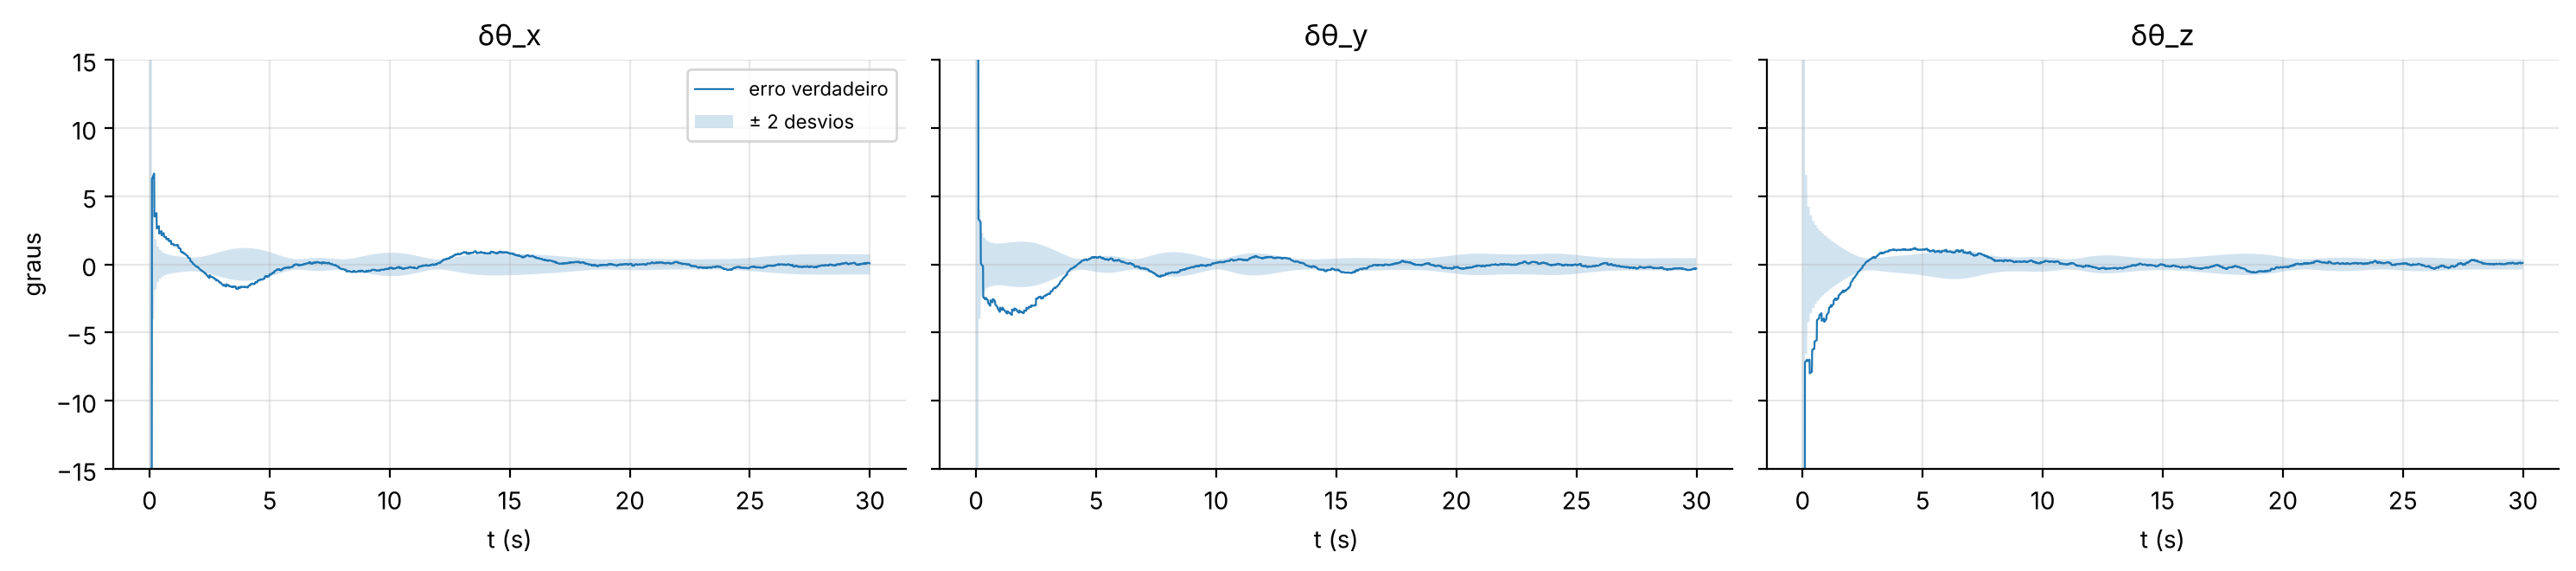

|det R − 1| máximo do nominal: 1.2e-14  (a rotação nunca sai de SO(3))


,erro angular médio (°),NEES médio (ideal 3)
0–1 s,11.28,54.07
1–2 s,4.32,26.35
2–5 s,2.34,12.81
5–10 s,0.84,4.05
10–30 s,0.43,2.69


In [13]:
DT_A, T_A = 0.01, 3000                   # 100 Hz, 30 s
SIG_GIRO = 0.02                          # rad/s
R_att = np.diag([0.3**2] * 3 + [0.02**2] * 3)      # acelerômetro (m/s²) e magnetômetro (unitário)
A_CADA = 10                              # uma medida de direção a cada 10 passos (10 Hz)

def simula_atitude(rng):
    Rv = [Exp(np.array([0.3, -0.2, 1.0]))]; wm = [np.zeros(3)]; zs = [None]
    for t in range(1, T_A):
        tt = t * DT_A
        w = np.array([0.6 * np.sin(0.7 * tt), 0.4 * np.cos(0.5 * tt), 0.3 + 0.5 * np.sin(0.2 * tt)])
        Rv.append(Rv[-1] @ Exp(w * DT_A))
        wm.append(w + SIG_GIRO * rng.standard_normal(3))
        zs.append(h_att(Rv[-1]) + rng.multivariate_normal(np.zeros(6), R_att) if t % A_CADA == 0 else None)
    return Rv, np.array(wm), zs

def eskf_atitude(wm, zs, R0, P0, usa_reset=True):
    R, P = R0.copy(), P0.copy(); est, Ps = [R.copy()], [P.copy()]
    Qd = SIG_GIRO**2 * np.eye(3)
    for t in range(1, len(wm)):
        # predição: nominal pela cinemática exata; covariância pelo jacobiano do erro
        Fx = Exp(wm[t] * DT_A).T; Fw = -DT_A * np.eye(3)
        R = R @ Exp(wm[t] * DT_A)
        P = Fx @ P @ Fx.T + Fw @ Qd @ Fw.T
        if zs[t] is not None:
            H = H_att(R)
            K = np.linalg.solve(H @ P @ H.T + R_att, H @ P).T
            dth = K @ (zs[t] - h_att(R))                  # erro estimado
            R = boxplus(R, dth)                           # injeção na variedade
            P = (np.eye(3) - K @ H) @ P
            G = Jr(dth) if usa_reset else np.eye(3)       # reset
            P = G @ P @ G.T; P = 0.5 * (P + P.T)
        est.append(R.copy()); Ps.append(P.copy())
    return est, np.array(Ps)

Rv_a, wm_a, zs_a = simula_atitude(rng)
R0_a = Rv_a[0] @ Exp(np.radians([25.0, -20.0, 40.0]))      # começa bem errado: ~50°
P0_a = np.radians(35.0)**2 * np.eye(3)
est_a, Ps_a = eskf_atitude(wm_a, zs_a, R0_a, P0_a)
err_a = np.array([boxminus(Rv_a[t], est_a[t]) for t in range(T_A)])   # erro verdadeiro, em δθ

tempo = np.arange(T_A) * DT_A
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4), sharey=True)
for k, nome in enumerate(["δθ_x", "δθ_y", "δθ_z"]):
    ax[k].plot(tempo, np.degrees(err_a[:, k]), lw=.8, label="erro verdadeiro")
    sd = np.degrees(np.sqrt(Ps_a[:, k, k]))
    ax[k].fill_between(tempo, -2 * sd, 2 * sd, alpha=.2, label="± 2 desvios")
    ax[k].set_title(nome); ax[k].set_xlabel("t (s)"); ax[k].set_ylim(-15, 15)
ax[0].set_ylabel("graus"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

nees_a = np.array([err_a[t] @ np.linalg.solve(Ps_a[t], err_a[t]) for t in range(T_A)])
JANELAS = [(0, 1), (1, 2), (2, 5), (5, 10), (10, 30)]
def por_janela(err, nees):
    return pd.DataFrame({"erro angular médio (°)": [np.degrees(np.linalg.norm(err[int(a / DT_A):int(b / DT_A)], axis=1)).mean() for a, b in JANELAS],
                         "NEES médio (ideal 3)": [nees[int(a / DT_A):int(b / DT_A)].mean() for a, b in JANELAS]},
                        index=[f"{a}–{b} s" for a, b in JANELAS])
print(f"|det R − 1| máximo do nominal: {max(abs(np.linalg.det(R) - 1) for R in est_a):.1e}  (a rotação nunca sai de SO(3))")
por_janela(err_a, nees_a).round(2)

**Leitura.**
- O filtro parte de um erro de cerca de 50°. O erro médio cai para cerca de 11° no primeiro segundo, 4° no segundo, e fica abaixo de 1° a partir de uns 5 s. A convergência não é instantânea porque, com 50° de erro, a linearização $\mathrm{Exp}(\delta\boldsymbol\theta)^\top\approx\mathbf I-[\delta\boldsymbol\theta]_\times$ é ruim (o IESKF da seção 7 ataca exatamente esse problema).
- **No transitório, o filtro é otimista demais:** o NEES médio é cerca de 54 no primeiro segundo e 13 entre 2 e 5 s (ideal 3). Enquanto o erro é grande, a linearização faz o filtro se achar mais certo do que está. **Em regime** (10 a 30 s), o NEES fica em torno de 2,7, perto do ideal, e a faixa de $\pm2$ desvios passa a cobrir o erro verdadeiro.
- O estado nominal é sempre uma rotação válida. Nenhuma normalização foi necessária, porque nunca se somou nada a uma matriz de rotação: a correção é sempre uma **composição** $\mathbf R\,\mathrm{Exp}(\delta\hat{\boldsymbol\theta})$.
- A rotação em torno do eixo vertical só é observável por causa do magnetômetro. Sem ele, $\delta\theta_z$ cresceria sem limite (experimente no exercício 4).

E o reset da covariância? A célula abaixo compara o filtro com e sem $\mathbf G$.

In [14]:
est_sr, Ps_sr = eskf_atitude(wm_a, zs_a, R0_a, P0_a, usa_reset=False)
err_sr = np.array([boxminus(Rv_a[t], est_sr[t]) for t in range(T_A)])
nees_sr = np.array([err_sr[t] @ np.linalg.solve(Ps_sr[t], err_sr[t]) for t in range(T_A)])
pd.concat({"com reset G": por_janela(err_a, nees_a), "sem reset (G = I)": por_janela(err_sr, nees_sr)}, axis=1).round(2)

com reset G                           sem reset (G = I)  \
        erro angular médio (°) NEES médio (ideal 3) erro angular médio (°)   
0–1 s                    11.28                54.07                  11.92   
1–2 s                     4.32                26.35                   5.40   
2–5 s                     2.34                12.81                   3.19   
5–10 s                    0.84                 4.05                   1.34   
10–30 s                   0.43                 2.69                   0.55   

                              
        NEES médio (ideal 3)  
0–1 s                  62.20  
1–2 s                  43.15  
2–5 s                  24.64  
5–10 s                  8.35  
10–30 s                 3.63

**Leitura.** O reset da covariância só faz diferença **direta** quando a correção injetada é grande, isto é, no transitório inicial, quando $\delta\hat{\boldsymbol\theta}$ chega a dezenas de graus; em regime, $\mathbf G\approx\mathbf I$. Mas o efeito **persiste** por vários segundos: sem $\mathbf G$, a covariância fica descrita no referencial errado logo no início, os ganhos seguintes ficam errados, e o filtro converge mais devagar e mais otimista (NEES maior). Só no fim da simulação as duas versões se encontram. Muitas implementações omitem $\mathbf G$ porque, partindo perto da verdade, a diferença é desprezível; partindo longe, como aqui, não é. O original descreve o reset corretamente, mas sem dizer quando ele importa.

---
# 6. Filtro de Kalman estendido iterado (IEKF)

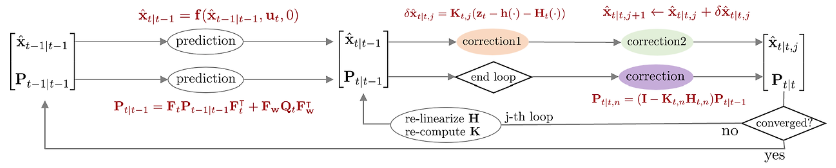

O IEKF é o EKF com a etapa de correção **repetida**. Como o EKF lineariza funções não lineares, a linearização sempre introduz erro. O IEKF reduz esse erro **linearizando de novo** em torno da estimativa corrigida, enquanto a mudança $\delta\hat{\mathbf x}_{t|t,j}$ produzida pela correção for grande.

Aqui, $\delta\hat{\mathbf x}$ é interpretado como **incremento de atualização**, e não como estado de erro: serve apenas para passar da $j$-ésima estimativa *a posteriori* para a $(j+1)$-ésima, e não é ele mesmo objeto de estimação.

## 6.1 Comparação com o EKF

**Semelhança 1.** Os modelos de movimento e de observação são exatamente os do EKF: $\mathbf x_t=\mathbf f(\mathbf x_{t-1},\mathbf u_t,\mathbf w_t)$ e $\mathbf z_t=\mathbf h(\mathbf x_t,\mathbf v_t)$.

**Semelhança 2.** A linearização também é a do EKF: $\mathbf x_t=\mathbf F_t\mathbf x_{t-1}+\tilde{\mathbf u}_t+\tilde{\mathbf w}_t$ e $\mathbf z_t=\mathbf H_t\mathbf x_t+\tilde{\mathbf z}_t+\tilde{\mathbf v}_t$, com $\tilde{\mathbf z}_t=\mathbf h(\hat{\mathbf x}_{t|t-1},0)-\mathbf H_t\hat{\mathbf x}_{t|t-1}$.

**Semelhança 3.** Como no EKF, as matrizes $\mathbf F,\mathbf H,\mathbf K$ se referem ao estado verdadeiro (e não a um estado de erro).

**Diferença 1.** No EKF, a correção vai da predição ao valor corrigido em **um** passo, $\hat{\mathbf x}_{t|t-1}\to\hat{\mathbf x}_{t|t}$. No IEKF, o valor corrigido volta a ser usado como ponto de linearização, e a correção se repete, $\hat{\mathbf x}_{t|t,j}\rightleftarrows\hat{\mathbf x}_{t|t,j+1}$ ($j$ é o número da iteração).

**Diferença 2.** Escrevendo a inovação **linearizada em torno de um ponto qualquer** $\hat{\mathbf x}_{t|t,j}$,

$$\mathbf r_{t,j}=\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j},0)-\mathbf H_{t,j}(\hat{\mathbf x}_{t|t-1}-\hat{\mathbf x}_{t|t,j}).$$

- **EKF:** o ponto de linearização é a própria predição, $\hat{\mathbf x}_{t|t,0}=\hat{\mathbf x}_{t|t-1}$; o último termo some, e sobra a inovação usual $\mathbf r_t=\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t-1},0)$.
- **IEKF:** a cada iteração lineariza-se num ponto novo, e o termo **não** some a partir de $j=1$.

O último termo "traduz" a medida prevista pela linearização em $\hat{\mathbf x}_{t|t,j}$ de volta para a predição $\hat{\mathbf x}_{t|t-1}$: **é a predição que está sendo corrigida**, e não o iterado anterior.

## 6.2 Predição (igual à do EKF)

$$\boxed{\hat{\mathbf x}_{t|t-1}=\mathbf f(\hat{\mathbf x}_{t-1|t-1},\mathbf u_t,0),\qquad \mathbf P_{t|t-1}=\mathbf F_t\mathbf P_{t-1|t-1}\mathbf F_t^\top+\mathbf F_{\mathbf w}\mathbf Q_t\mathbf F_{\mathbf w}^\top}$$

## 6.3 Correção (forma corrigida)

$$\boxed{\begin{aligned}
&\hat{\mathbf x}_{t|t,0}=\hat{\mathbf x}_{t|t-1};\ \text{escolha } \epsilon\\
&\text{para } j=0,1,2,\dots\\
&\qquad \mathbf K_{t,j}=\mathbf P_{t|t-1}\mathbf H_{t,j}^\top(\mathbf H_{t,j}\mathbf P_{t|t-1}\mathbf H_{t,j}^\top+\mathbf H_{\mathbf v,j}\mathbf R_t\mathbf H_{\mathbf v,j}^\top)^{-1}\\
&\qquad \hat{\mathbf x}_{t|t,j+1}={\color{red}\hat{\mathbf x}_{t|t-1}}+\mathbf K_{t,j}\big(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j},0)-\mathbf H_{t,j}(\hat{\mathbf x}_{t|t-1}-\hat{\mathbf x}_{t|t,j})\big)\\
&\qquad \text{pare quando } \|\hat{\mathbf x}_{t|t,j+1}-\hat{\mathbf x}_{t|t,j}\|<\epsilon\\
&\mathbf P_{t|t}=(\mathbf I-\mathbf K_{t,n}\mathbf H_{t,n})\mathbf P_{t|t-1}\quad(\text{com o último } j=n)
\end{aligned}}$$

> **Nota do tradutor (a mais importante deste notebook).** No original, a correção do IEKF é escrita como
> $$\delta\hat{\mathbf x}_{t|t,j}=\mathbf K_{t,j}\big(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j},0)-\mathbf H_t(\hat{\mathbf x}_{t|t-1}-\hat{\mathbf x}_{t|t,j})\big),\qquad \hat{\mathbf x}_{t|t,j+1}={\color{red}\hat{\mathbf x}_{t|t,j}}+\delta\hat{\mathbf x}_{t|t,j},$$
> isto é, o incremento é somado ao **iterado anterior**, e não à **predição**. A mesma forma aparece no quadro-resumo e nas figuras 07 e 12. **Assim escrito, o algoritmo não converge**: o termo $-\mathbf H(\hat{\mathbf x}_{t|t-1}-\hat{\mathbf x}_{t|t,j})$ já "traz a correção de volta" para a predição, e somá-lo ao iterado conta a correção duas vezes, três vezes, e assim por diante. No caso **linear**, $\mathbf r_{t,j}=\mathbf z_t-\mathbf H\hat{\mathbf x}_{t|t-1}$ não depende de $j$, e a forma impressa anda a mesma distância a cada iteração, para sempre.
>
> A forma correta é a de Bell e Cathey (1993), em que a soma é feita à predição $\hat{\mathbf x}_{t|t-1}$. É também a forma que **o próprio autor deduz** na seção 9 (última linha da dedução por Gauss–Newton) e a que se obtém da fórmula do IESKF da seção 7 com $\mathbf J=\mathbf I$. Também está correta, nos dois sentidos, a escrita "incremental": $\hat{\mathbf x}_{t|t,j+1}=\hat{\mathbf x}_{t|t,j}+\big[\mathbf K_{t,j}\mathbf r_{t,j}-(\hat{\mathbf x}_{t|t,j}-\hat{\mathbf x}_{t|t-1})\big]$: o termo entre colchetes é o incremento verdadeiro, e é exatamente o que falta no original. (Na equação da seção 9 o original ainda usa $\mathbf H_t$ fixo, sem o índice $j$; ele deve ser recalculado a cada iteração, como acima.)

A célula abaixo implementa as duas formas e as aplica primeiro a um caso **linear** e depois a um caso não linear, uma medida de distância e direção muito precisa feita de perto, com uma predição muito incerta. Nesse cenário, o EKF erra feio.

In [15]:
def iekf_correcao(x_pred, P, z, h, Hfun, R, forma="correta", n_iter=30, eps=1e-10):
    # IEKF. forma="correta": soma à predição (Bell–Cathey); "impressa": soma ao iterado anterior.
    xj = x_pred.copy(); iterados = [xj.copy()]
    for j in range(n_iter):
        H = Hfun(xj)
        K = np.linalg.solve(H @ P @ H.T + R, H @ P).T
        r = z - h(xj) - H @ (x_pred - xj)
        x_novo = (x_pred if forma == "correta" else xj) + K @ r
        iterados.append(x_novo.copy())
        parou = np.linalg.norm(x_novo - xj) < eps
        xj = x_novo
        if parou:
            break
    H = Hfun(xj); K = np.linalg.solve(H @ P @ H.T + R, H @ P).T
    return xj, (np.eye(len(xj)) - K @ H) @ P, np.array(iterados)

# --- caso linear: o IEKF correto pára na 1ª iteração; o impresso anda sem parar
H_lin = np.array([[1.0, 0.0]]); P_lin = np.eye(2); R_lin = np.array([[0.1]])
xp_lin, z_lin = np.zeros(2), np.array([1.0])
xc, _, it_c = iekf_correcao(xp_lin, P_lin, z_lin, lambda x: H_lin @ x, lambda x: H_lin, R_lin, "correta", n_iter=6)
xi, _, it_i = iekf_correcao(xp_lin, P_lin, z_lin, lambda x: H_lin @ x, lambda x: H_lin, R_lin, "impressa", n_iter=6, eps=0)
x_kf_lin, _, _ = kf_correcao(xp_lin, P_lin, z_lin, H_lin, R_lin)
print("caso linear, primeira componente dos iterados")
print("  forma correta :", np.round(it_c[:, 0], 4))
print("  forma impressa:", np.round(it_i[:, 0], 4))
confere("caso linear: IEKF correto = KF (uma correção basta)", xc, x_kf_lin, tol=1e-12)

caso linear, primeira componente dos iterados
  forma correta : [0.     0.9091 0.9091]
  forma impressa: [0.     0.9091 1.8182 2.7273 3.6364 4.5455 5.4545]
OK   caso linear: IEKF correto = KF (uma correção basta):  diferença máxima = 0.00e+00


OK   IEKF (forma correta) converge para o MAP:  diferença máxima = 1.54e-11


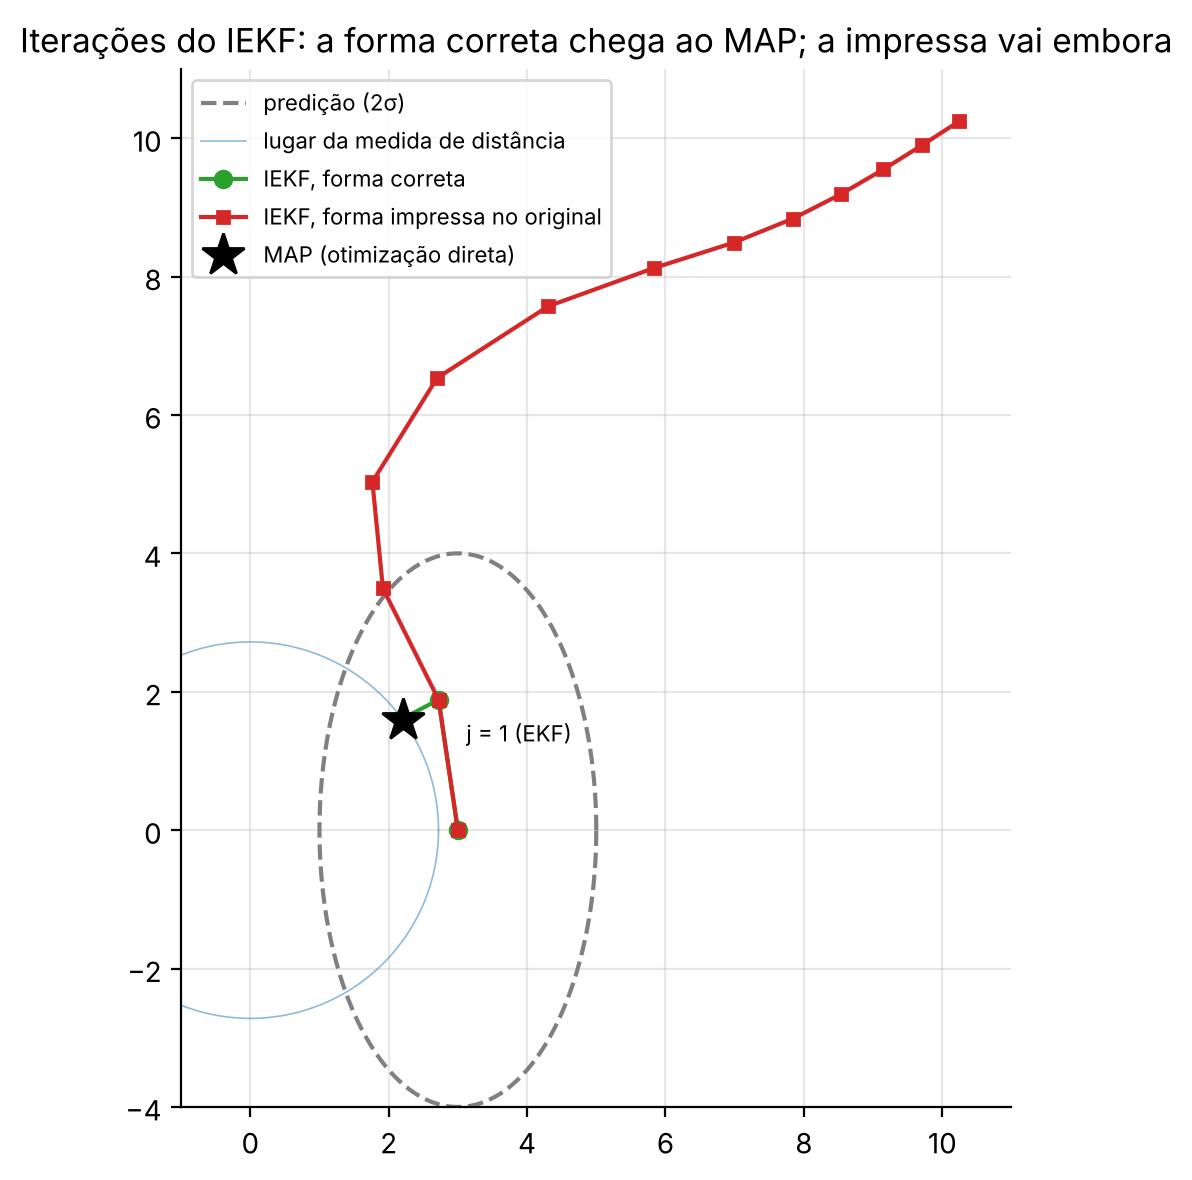

,forma correta: |x_j − MAP|,forma impressa: |x_j − MAP|
iteração j,,
0,1.7867,1.7867
1,0.5924,0.5924
2,0.0125,1.9167
3,0.0000,3.4627
4,0.0000,4.9611
5,0.0000,6.3334
6,0.0000,7.4679
7,NaN,8.3881
8,NaN,9.1761


In [16]:
def h_rb(p):                     # distância e direção, sensor na origem
    return np.array([np.hypot(p[0], p[1]), np.arctan2(p[1], p[0])])

def H_rb(p):
    r2 = p[0]**2 + p[1]**2; r = np.sqrt(r2)
    return np.array([[p[0] / r, p[1] / r], [-p[1] / r2, p[0] / r2]])

xp_rb = np.array([3.0, 0.0]); P_rb = np.diag([1.0, 4.0])          # predição incerta, sobretudo em y
R_rb = np.diag([0.05**2, 0.02**2])                                 # sensor muito bom
x_verd_rb = np.array([2.2, 1.6]); z_rb = h_rb(x_verd_rb)           # medida sem ruído, para isolar a linearização

x_c, P_c, it_c = iekf_correcao(xp_rb, P_rb, z_rb, h_rb, H_rb, R_rb, "correta")
x_i, _, it_i = iekf_correcao(xp_rb, P_rb, z_rb, h_rb, H_rb, R_rb, "impressa", n_iter=12, eps=0)

# MAP por otimização direta (a resposta que o IEKF deveria encontrar)
Lr, Lp = np.linalg.cholesky(np.linalg.inv(R_rb)).T, np.linalg.cholesky(np.linalg.inv(P_rb)).T
x_map = least_squares(lambda p: np.concatenate([Lr @ (z_rb - h_rb(p)), Lp @ (p - xp_rb)]), xp_rb,
                      xtol=1e-15, ftol=1e-15, gtol=1e-15).x
confere("IEKF (forma correta) converge para o MAP", x_c, x_map, tol=1e-9)

tab = pd.DataFrame({"forma correta: |x_j − MAP|": np.linalg.norm(it_c[:13] - x_map, axis=1) if len(it_c) >= 13 else
                    np.r_[np.linalg.norm(it_c - x_map, axis=1), [np.nan] * (13 - len(it_c))],
                    "forma impressa: |x_j − MAP|": np.linalg.norm(it_i[:13] - x_map, axis=1)})
tab.index.name = "iteração j"

th = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(7, 6))
for nome, Pm, xm, cor in [("predição", P_rb, xp_rb, "gray")]:
    L = np.linalg.cholesky(Pm); ax.plot(*(xm[:, None] + 2 * L @ np.vstack([np.cos(th), np.sin(th)])), color=cor, ls="--", label="predição (2σ)")
ax.plot(*np.vstack([z_rb[0] * np.cos(th), z_rb[0] * np.sin(th)]), color="tab:blue", lw=.6, alpha=.5, label="lugar da medida de distância")
ax.plot(it_c[:, 0], it_c[:, 1], "o-", color="tab:green", label="IEKF, forma correta")
ax.plot(it_i[:, 0], it_i[:, 1], "s-", color="tab:red", ms=4, label="IEKF, forma impressa no original")
ax.plot(*x_map, "k*", ms=16, label="MAP (otimização direta)")
ax.annotate("j = 1 (EKF)", it_c[1], xytext=(10, -15), textcoords="offset points", fontsize=8)
ax.set_xlim(-1, 11); ax.set_ylim(-4, 11); ax.set_aspect("equal"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("Iterações do IEKF: a forma correta chega ao MAP; a impressa vai embora")
plt.tight_layout(); plt.show()
tab.round(4)

**Leitura.**
- A **primeira** iteração das duas formas é a mesma, e é o **EKF**: um ponto bem longe do MAP, porque a linearização em $\hat{\mathbf x}_{t|t-1}=(3,0)$ é ruim para uma predição tão incerta.
- A forma correta chega ao MAP em poucas iterações, com a convergência rápida típica de Gauss–Newton.
- A forma impressa se afasta a cada iteração. No caso linear, ela anda a mesma distância, $\mathbf K(\mathbf z-\mathbf H\hat{\mathbf x}_{t|t-1})$, em toda iteração.

Esta é a mesma "caça ao erro" da seção C5b de `mq_hmm_kalman_duas_trilhas`, agora feita no texto original completo, com as figuras.

## 6.4 Resumo (forma corrigida)

$$
\boxed{\begin{aligned}
&\text{FiltroDeKalmanEstendidoIterado}(\hat{\mathbf x}_{t-1|t-1},\mathbf P_{t-1|t-1},\mathbf u_t,\mathbf z_t)\ \{\\
&\qquad\text{(predição)}\quad \text{igual à do EKF}\\
&\qquad\text{(correção)}\quad \hat{\mathbf x}_{t|t,0}=\hat{\mathbf x}_{t|t-1};\ \text{repita: } \mathbf K_{t,j}=\mathbf P_{t|t-1}\mathbf H_{t,j}^\top(\mathbf H_{t,j}\mathbf P_{t|t-1}\mathbf H_{t,j}^\top+\mathbf H_{\mathbf v,j}\mathbf R_t\mathbf H_{\mathbf v,j}^\top)^{-1},\\
&\qquad\qquad\qquad\qquad \hat{\mathbf x}_{t|t,j+1}=\hat{\mathbf x}_{t|t-1}+\mathbf K_{t,j}\big(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j},0)-\mathbf H_{t,j}(\hat{\mathbf x}_{t|t-1}-\hat{\mathbf x}_{t|t,j})\big)\ \text{ até convergir}\\
&\qquad\qquad\qquad\qquad \mathbf P_{t|t}=(\mathbf I-\mathbf K_{t,n}\mathbf H_{t,n})\mathbf P_{t|t-1}\\
&\qquad\text{retorna } \hat{\mathbf x}_{t|t},\ \mathbf P_{t|t}\ \}
\end{aligned}}
$$

---
# 7. Filtro de Kalman de estado de erro iterado (IESKF)

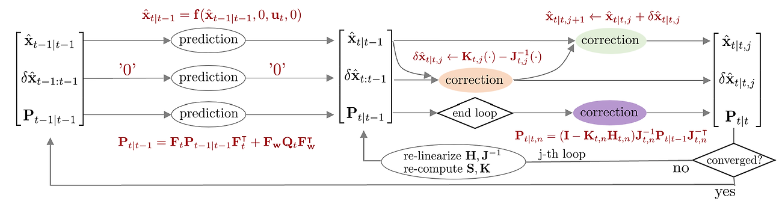

Enquanto o IEKF estima iterativamente o estado verdadeiro na correção, o **IESKF** estima iterativamente o **estado de erro** $\delta\mathbf x_t$. Vale a mesma relação $\mathbf x_{\text{verd},t}=\mathbf x_t\boxplus\delta\mathbf x_t$. Na atualização iterativa, pode-se entender $\mathbf x_{\text{verd},t}$ como o estado **depois** da atualização, o nominal $\mathbf x_t$ como o estado **antes**, e o erro $\delta\mathbf x_t$ como o **tamanho** da atualização.

## 7.1 Comparação com o ESKF

**Semelhança 1.** Os modelos são os do ESKF.

**Semelhança 2.** Os jacobianos $\mathbf F_t$ e $\mathbf H_t$ são em relação ao erro $\delta\mathbf x_t$, como no ESKF, e $\mathbf H_t=\frac{\partial\mathbf h}{\partial\mathbf x_{\text{verd},t}}\frac{\partial\mathbf x_{\text{verd},t}}{\partial\delta\mathbf x_t}$.

**Semelhança 3.** O modelo linearizado do erro é o mesmo do ESKF: $\delta\mathbf x_t=\mathbf F_t\delta\mathbf x_{t-1}+\tilde{\mathbf w}_t$.

**Diferença: a correção é deduzida como um problema MAP.** A correção do ESKF desenvolve $\mathrm{bel}(\delta\mathbf x_t)=\eta\,p(\mathbf z_t\mid\delta\mathbf x_t)\,\overline{\mathrm{bel}}(\delta\mathbf x_t)$ e chega a $\delta\hat{\mathbf x}_{t|t}=\mathbf K_t(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t-1},0,0))$ e $\mathbf P_{t|t}=(\mathbf I-\mathbf K_t\mathbf H_t)\mathbf P_{t|t-1}$. O IESKF, em vez disso, usa a **estimação de máximo *a posteriori*** (MAP), resolvida por **Gauss–Newton** (seção 9). A dedução segue as referências [6]–[11] do original, das quais [6] (He, Xu e Zhang, *Kalman filters on differentiable manifolds*) é a mais detalhada.

Se o EKF é deduzido pela via MAP, o problema a otimizar é

$$\arg\min_{\mathbf x_t}\ \big\|\mathbf z_t-\mathbf h(\mathbf x_{\text{verd},t},0)\big\|^2_{(\mathbf H_{\mathbf v}\mathbf R\mathbf H_{\mathbf v}^\top)^{-1}}+\big\|\mathbf x_{\text{verd},t}\boxminus\hat{\mathbf x}_{t|t-1}\big\|^2_{\mathbf P_{t|t-1}^{-1}},$$

com $\|\mathbf a\|^2_{\mathbf W}=\mathbf a^\top\mathbf W\mathbf a$.

> **Nota do tradutor.** O original escreve o peso do primeiro termo como $\mathbf H_{\mathbf v}\mathbf R^{-1}\mathbf H_{\mathbf v}^\top$ (aqui e nas seções 7 e 10). O peso correto é o **inverso da covariância** do ruído linearizado, $(\mathbf H_{\mathbf v}\mathbf R\mathbf H_{\mathbf v}^\top)^{-1}$; as duas expressões só coincidem quando $\mathbf H_{\mathbf v}$ é ortogonal (por exemplo, $\mathbf H_{\mathbf v}=\mathbf I$).

> **Dica (do original).** O erro **de predição** é $\delta\hat{\mathbf x}_{t|t-1}=\mathbf x_{\text{verd},t}\boxminus\hat{\mathbf x}_{t|t-1}\sim\mathcal N(0,\mathbf P_{t|t-1})$. O erro **corrigido** é $\delta\hat{\mathbf x}_{t|t}=\mathbf x_{\text{verd},t}\boxminus\hat{\mathbf x}_{t|t}$, ou seja, $\mathbf x_{\text{verd},t}=\hat{\mathbf x}_{t|t}\boxplus\delta\hat{\mathbf x}_{t|t}$.

O primeiro termo é linearizado como no ESKF, **mas agora em torno do iterado atual** $\hat{\mathbf x}_{t|t,j}$:

$$\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j}\boxplus\delta\mathbf x,0)\approx\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j},0)-\mathbf H_{t,j}\,\delta\mathbf x .$$

No ESKF, o erro estimado é sempre zero e esse termo desaparecia; no IESKF ele não é zero e fica. O segundo termo é desenvolvido usando a dica:

$$\delta\hat{\mathbf x}_{t|t-1}=(\hat{\mathbf x}_{t|t,j}\boxplus\delta\mathbf x)\boxminus\hat{\mathbf x}_{t|t-1}\approx(\hat{\mathbf x}_{t|t,j}\boxminus\hat{\mathbf x}_{t|t-1})+\mathbf J_{t,j}\,\delta\mathbf x,\qquad \mathbf J_{t,j}=\frac{\partial}{\partial\delta\mathbf x}\Big((\hat{\mathbf x}_{t|t,j}\boxplus\delta\mathbf x)\boxminus\hat{\mathbf x}_{t|t-1}\Big)\Big|_{\delta\mathbf x=0}.$$

Daí, como $\delta\hat{\mathbf x}_{t|t-1}\sim\mathcal N(0,\mathbf P_{t|t-1})$, o erro corrigido tem distribuição *a priori*

$$\delta\mathbf x\sim\mathcal N\big(-\mathbf J_{t,j}^{-1}(\hat{\mathbf x}_{t|t,j}\boxminus\hat{\mathbf x}_{t|t-1}),\ \mathbf J_{t,j}^{-1}\mathbf P_{t|t-1}\mathbf J_{t,j}^{-\top}\big),$$

e o problema MAP da $j$-ésima iteração fica

$$\boxed{\arg\min_{\delta\mathbf x}\ \big\|\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j},0)-\mathbf H_{t,j}\delta\mathbf x\big\|^2_{(\mathbf H_{\mathbf v}\mathbf R\mathbf H_{\mathbf v}^\top)^{-1}}+\big\|(\hat{\mathbf x}_{t|t,j}\boxminus\hat{\mathbf x}_{t|t-1})+\mathbf J_{t,j}\delta\mathbf x\big\|^2_{\mathbf P_{t|t-1}^{-1}}}$$

> **Nota do tradutor.** No original, o primeiro termo desse problema aparece com $\mathbf h(\hat{\mathbf x}_{t|t-1},0,0)$; mas a fórmula final (e a implementação correta) usa $\mathbf h(\hat{\mathbf x}_{t|t,j},0,0)$, isto é, relineariza no iterado. Também a "soma" $\hat{\mathbf x}_{t|t,j}-\hat{\mathbf x}_{t|t-1}$ deve ser lida como $\boxminus$ quando há rotações.

## 7.2 Predição (igual à do ESKF)

$$\boxed{\delta\hat{\mathbf x}_{t|t-1}=0,\qquad \hat{\mathbf x}_{t|t-1}=\mathbf f(\hat{\mathbf x}_{t-1|t-1},0,\mathbf u_t,0),\qquad \mathbf P_{t|t-1}=\mathbf F_t\mathbf P_{t-1|t-1}\mathbf F_t^\top+\mathbf F_{\mathbf w}\mathbf Q_t\mathbf F_{\mathbf w}^\top}$$

## 7.3 Correção

Derivando o problema acima e igualando a zero (seção 10), com $\mathbf c_j=\hat{\mathbf x}_{t|t,j}\boxminus\hat{\mathbf x}_{t|t-1}$:

$$\boxed{\begin{aligned}
&\hat{\mathbf x}_{t|t,0}=\hat{\mathbf x}_{t|t-1};\ \text{para } j=0,1,\dots\\
&\qquad \mathbf S_{t,j}=\mathbf H_{t,j}\mathbf J_{t,j}^{-1}\mathbf P_{t|t-1}\mathbf J_{t,j}^{-\top}\mathbf H_{t,j}^\top+\mathbf H_{\mathbf v,j}\mathbf R_t\mathbf H_{\mathbf v,j}^\top\\
&\qquad \mathbf K_{t,j}=\mathbf J_{t,j}^{-1}\mathbf P_{t|t-1}\mathbf J_{t,j}^{-\top}\mathbf H_{t,j}^\top\mathbf S_{t,j}^{-1}\\
&\qquad \delta\hat{\mathbf x}_{t|t,j}=\mathbf K_{t,j}\big(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j},0,0)+\mathbf H_{t,j}\mathbf J_{t,j}^{-1}\mathbf c_j\big)-\mathbf J_{t,j}^{-1}\mathbf c_j\\
&\qquad \hat{\mathbf x}_{t|t,j+1}=\hat{\mathbf x}_{t|t,j}\boxplus\delta\hat{\mathbf x}_{t|t,j}\qquad\text{até } \|\delta\hat{\mathbf x}_{t|t,j}\|<\epsilon\\
&\mathbf P_{t|t}=(\mathbf I-\mathbf K_{t,n}\mathbf H_{t,n})\mathbf J_{t,n}^{-1}\mathbf P_{t|t-1}\mathbf J_{t,n}^{-\top}
\end{aligned}}$$

**Repare no último termo, $-\mathbf J^{-1}\mathbf c_j$.** É justamente o termo que falta na correção do IEKF impressa no original (seção 6). Com estados vetoriais, $\boxplus=+$, $\boxminus=-$ e $\mathbf J=\mathbf I$, a fórmula do IESKF fica

$$\hat{\mathbf x}_{t|t,j+1}=\hat{\mathbf x}_{t|t,j}+\mathbf K(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j})+\mathbf H\mathbf c_j)-\mathbf c_j=\hat{\mathbf x}_{t|t-1}+\mathbf K\big(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j})-\mathbf H(\hat{\mathbf x}_{t|t-1}-\hat{\mathbf x}_{t|t,j})\big),$$

que é o IEKF **correto**. Ou seja: o mesmo texto traz, na seção 7, a fórmula que corrige a seção 6.

In [17]:
def ieskf_correcao(x_pred, P, z, h, Hfun, R, boxplus, boxminus, Jfun, n_iter=50, eps=1e-12):
    # IESKF genérico: o estado pode viver numa variedade (⊞, ⊟); J é o jacobiano de (x_j ⊞ δ) ⊟ x_pred
    xj = x_pred.copy() if hasattr(x_pred, "copy") else x_pred
    hist = [xj]
    for j in range(n_iter):
        c = boxminus(xj, x_pred)
        Ji = np.linalg.inv(Jfun(c))
        H = Hfun(xj)
        Pb = Ji @ P @ Ji.T
        S = H @ Pb @ H.T + R
        K = Pb @ H.T @ np.linalg.inv(S)
        dx = K @ (z - h(xj) + H @ Ji @ c) - Ji @ c
        xj = boxplus(xj, dx); hist.append(xj)
        if np.linalg.norm(dx) < eps:
            break
    c = boxminus(xj, x_pred); Ji = np.linalg.inv(Jfun(c)); H = Hfun(xj)
    Pb = Ji @ P @ Ji.T; K = Pb @ H.T @ np.linalg.inv(H @ Pb @ H.T + R)
    return xj, (np.eye(P.shape[0]) - K @ H) @ Pb, hist

# espaço vetorial: ⊞ = +, ⊟ = −, J = I  ⇒  deve reproduzir o IEKF correto, iterado a iterado
x_ie, P_ie, hist_ie = ieskf_correcao(xp_rb, P_rb, z_rb, h_rb, H_rb, R_rb,
                                     lambda x, d: x + d, lambda a, b: a - b, lambda c: np.eye(2))
n = min(len(hist_ie), len(it_c))
confere("IESKF com ⊞ = + e J = I reproduz os iterados do IEKF correto", np.array(hist_ie[:n]), it_c[:n], tol=1e-9)
confere("e a mesma covariância final", P_ie, P_c, tol=1e-12)

OK   IESKF com ⊞ = + e J = I reproduz os iterados do IEKF correto:  diferença máxima = 4.44e-16
OK   e a mesma covariância final:  diferença máxima = 4.44e-16


### Acréscimo: o IESKF na atitude, onde $\mathbf J\neq\mathbf I$

Voltamos à atitude da seção 5.4, agora com **uma única** correção difícil: a predição está errada por cerca de 40° e é muito incerta ($\mathbf P=(35°)^2\mathbf I$), e o par acelerômetro–magnetômetro é preciso. Para rotações, com $\mathbf R\boxminus\mathbf R'=\mathrm{Log}(\mathbf R'^\top\mathbf R)$,

$$\mathbf J_{t,j}=\frac{\partial}{\partial\delta\boldsymbol\theta}\mathrm{Log}\big(\hat{\mathbf R}_{t|t-1}^\top\hat{\mathbf R}_{t|t,j}\mathrm{Exp}(\delta\boldsymbol\theta)\big)\Big|_0=\mathbf J_r^{-1}(\mathbf c_j),\qquad \mathbf c_j=\hat{\mathbf R}_{t|t,j}\boxminus\hat{\mathbf R}_{t|t-1}.$$

Comparamos três respostas:
1. o **ESKF**, que faz uma só correção (é a iteração $j=0$ do IESKF);
2. o **IESKF**, iterado até convergir;
3. o **MAP exato na variedade**, obtido por otimização direta em $\delta\boldsymbol\theta$ com $\mathbf R=\hat{\mathbf R}_{t|t-1}\mathrm{Exp}(\delta\boldsymbol\theta)$.

In [18]:
J_teste = Jr_inv(np.array([0.3, -0.5, 0.2]))
R_j, R_p = Exp(np.array([0.3, -0.5, 0.2])), np.eye(3)
confere("J = J_r⁻¹(c) (numérico)", J_teste,
        jacobiano_numerico(lambda d: boxminus(boxplus(R_j, d), R_p), np.zeros(3)), tol=1e-7)

R_verd1 = Exp(np.array([0.4, 1.1, -0.7]))
R_pred1 = R_verd1 @ Exp(np.radians([30.0, -20.0, 20.0]))     # predição errada por ~40°
P_pred1 = np.radians(35.0)**2 * np.eye(3)
R_med1 = np.diag([0.05**2] * 3 + [0.005**2] * 3)
z1 = h_att(R_verd1) + rng.multivariate_normal(np.zeros(6), R_med1)

R_ie, P_ie1, hist_att = ieskf_correcao(R_pred1, P_pred1, z1, h_att, H_att, R_med1, boxplus, boxminus, Jr_inv)

# MAP exato na variedade
Lr1, Lp1 = np.linalg.cholesky(np.linalg.inv(R_med1)).T, np.linalg.cholesky(np.linalg.inv(P_pred1)).T
sol = least_squares(lambda d: np.concatenate([Lr1 @ (z1 - h_att(boxplus(R_pred1, d))), Lp1 @ d]),
                    np.zeros(3), xtol=1e-15, ftol=1e-15, gtol=1e-15)
R_map1 = boxplus(R_pred1, sol.x)
confere("IESKF na atitude converge para o MAP na variedade", boxminus(R_ie, R_map1), np.zeros(3), tol=1e-7)

graus = lambda R: np.degrees(np.linalg.norm(boxminus(R, R_verd1)))
tab = pd.DataFrame({"erro angular até a verdade (°)": [graus(R_pred1), graus(hist_att[1]), graus(R_ie), graus(R_map1)],
                    "distância até o MAP (°)": [np.degrees(np.linalg.norm(boxminus(R, R_map1))) for R in [R_pred1, hist_att[1], R_ie, R_map1]]},
                   index=["predição", "ESKF (uma correção, j = 1)", f"IESKF ({len(hist_att) - 1} iterações)", "MAP na variedade"])
print("distância ao MAP ao longo das iterações (graus):",
      np.round([np.degrees(np.linalg.norm(boxminus(R, R_map1))) for R in hist_att[:8]], 5))
tab.round(4)

OK   J = J_r⁻¹(c) (numérico):  diferença máxima = 5.82e-11
OK   IESKF na atitude converge para o MAP na variedade:  diferença máxima = 2.13e-10
distância ao MAP ao longo das iterações (graus): [40.812   6.268   0.251   0.0022  0.      0.      0.      0.    ]


,erro angular até a verdade (°),distância até o MAP (°)
predição,41.2311,40.812
"ESKF (uma correção, j = 1)",6.5696,6.268
IESKF (8 iterações),1.2232,0.000
MAP na variedade,1.2232,0.000


**Leitura.**
- Uma correção só (ESKF) melhora muito a predição, mas deixa um erro grande de linearização. O IESKF elimina esse erro e chega ao MAP exato **na variedade**.
- A convergência é rápida: a distância ao MAP cai de cerca de 41° para 6°, 0,25°, 0,002°, ou seja, o número de casas decimais corretas praticamente dobra a cada iteração, como em Gauss–Newton com resíduo pequeno. Na prática, 3 a 5 iterações bastam.
- É exatamente esta correção iterada na variedade que faz funcionar odometrias como a FAST-LIO (referência [8] do original), com o estado de um robô inteiro (posição, velocidade, rotação e vieses dos sensores) no lugar da nossa rotação.

## 7.4 Resumo

$$
\boxed{\begin{aligned}
&\text{FiltroDeKalmanDeEstadoDeErroIterado}(\hat{\mathbf x}_{t-1|t-1},\mathbf P_{t-1|t-1},\mathbf u_t,\mathbf z_t)\ \{\\
&\qquad\text{(predição)}\quad \text{igual à do ESKF}\\
&\qquad\text{(correção)}\quad \text{repita: } \mathbf S_{t,j},\ \mathbf K_{t,j},\ \delta\hat{\mathbf x}_{t|t,j}\ \text{como na seção 7.3},\ \ \hat{\mathbf x}_{t|t,j+1}=\hat{\mathbf x}_{t|t,j}\boxplus\delta\hat{\mathbf x}_{t|t,j}\ \text{ até convergir}\\
&\qquad\qquad\qquad\qquad \mathbf P_{t|t}=(\mathbf I-\mathbf K_{t,n}\mathbf H_{t,n})\mathbf J_{t,n}^{-1}\mathbf P_{t|t-1}\mathbf J_{t,n}^{-\top}\\
&\qquad\text{retorna } \hat{\mathbf x}_{t|t},\ \mathbf P_{t|t}\ \}
\end{aligned}}
$$

> **Nota do tradutor.** Como no ESKF, o quadro-resumo do original escreve a predição do erro como $\mathbf F_t\hat{\mathbf x}_{t-1|t-1}$ em vez de $\mathbf F_t\,\delta\hat{\mathbf x}_{t-1|t-1}$.

---
# 8. Dedução do filtro de Kalman

Esta seção deduz as equações de predição e de atualização do filtro de Kalman, seguindo a seção 3.2.4, "Mathematical Derivation of the KF", de *Probabilistic Robotics* (Thrun, Burgard e Fox, referência [13] do original). O KF supõe que $\mathrm{bel}(\mathbf x_t)$ e $\overline{\mathrm{bel}}(\mathbf x_t)$ são gaussianas, e calcula a média e a covariância de cada uma a partir de

$$\overline{\mathrm{bel}}(\mathbf x_t)=\int{\color{red}p(\mathbf x_t\mid\mathbf x_{t-1},\mathbf u_t)}\,\mathrm{bel}(\mathbf x_{t-1})\,d\mathbf x_{t-1},\qquad \mathrm{bel}(\mathbf x_t)=\eta\,{\color{teal}p(\mathbf z_t\mid\mathbf x_t)}\,\overline{\mathrm{bel}}(\mathbf x_t),$$

com ${\color{red}p(\mathbf x_t\mid\mathbf x_{t-1},\mathbf u_t)}=\mathcal N(\mathbf F_t\mathbf x_{t-1}+\mathbf B_t\mathbf u_t,\mathbf Q_t)$ e ${\color{teal}p(\mathbf z_t\mid\mathbf x_t)}=\mathcal N(\mathbf H_t\mathbf x_t,\mathbf R_t)$.

> **Nota do tradutor: troca de nomes.** Em toda esta seção (e nas figuras 02, 04 e 25), o original usa a convenção de *Probabilistic Robotics*: **$\mathbf R_t$ para o ruído de movimento e $\mathbf Q_t$ para o ruído de medida**, o contrário do resto do texto. A tradução abaixo usa a convenção do resto do notebook ($\mathbf Q$ movimento, $\mathbf R$ medida). Quem ler o original lado a lado deve trocar as letras.

## 8.1 Dedução da predição

Queremos a média e a covariância de $\overline{\mathrm{bel}}(\mathbf x_t)$. Escrevendo as gaussianas,

$$\overline{\mathrm{bel}}(\mathbf x_t)=\eta\int\exp(-\mathbf L_t)\,d\mathbf x_{t-1},\qquad \boxed{\mathbf L_t=\tfrac12(\mathbf x_t-\mathbf F_t\mathbf x_{t-1}-\mathbf B_t\mathbf u_t)^\top\mathbf Q_t^{-1}(\mathbf x_t-\mathbf F_t\mathbf x_{t-1}-\mathbf B_t\mathbf u_t)+\tfrac12(\mathbf x_{t-1}-\hat{\mathbf x}_{t-1})^\top\mathbf P_{t-1}^{-1}(\mathbf x_{t-1}-\hat{\mathbf x}_{t-1})}$$

$\mathbf L_t$ é quadrática em $\mathbf x_t$ e $\mathbf x_{t-1}$. Para tirar a integral, separamos $\mathbf L_t=\mathbf L_t(\mathbf x_{t-1},\mathbf x_t)+\mathbf L_t(\mathbf x_t)$: a primeira parte contém todos os termos com $\mathbf x_{t-1}$; a segunda, só termos em $\mathbf x_t$, e por isso sai da integral:

$$\overline{\mathrm{bel}}(\mathbf x_t)=\eta\,\exp(-\mathbf L_t(\mathbf x_t))\int\exp(-\mathbf L_t(\mathbf x_{t-1},\mathbf x_t))\,d\mathbf x_{t-1}.$$

Para construir $\mathbf L_t(\mathbf x_{t-1},\mathbf x_t)$, derivamos $\mathbf L_t$ em relação a $\mathbf x_{t-1}$:

$$\frac{\partial\mathbf L_t}{\partial\mathbf x_{t-1}}=-\mathbf F_t^\top\mathbf Q_t^{-1}(\mathbf x_t-\mathbf F_t\mathbf x_{t-1}-\mathbf B_t\mathbf u_t)+\mathbf P_{t-1}^{-1}(\mathbf x_{t-1}-\hat{\mathbf x}_{t-1}),\qquad \frac{\partial^2\mathbf L_t}{\partial\mathbf x_{t-1}^2}=\mathbf F_t^\top\mathbf Q_t^{-1}\mathbf F_t+\mathbf P_{t-1}^{-1}=:\boldsymbol\Psi_t^{-1}.$$

$\boldsymbol\Psi_t^{-1}$ é a curvatura de $\mathbf L_t$ e faz o papel de inverso de uma covariância. Como $\mathbf L_t$ é quadrática e positiva semidefinida, o ponto onde a primeira derivada se anula é a média em $\mathbf x_{t-1}$, e a segunda derivada é a inversa da covariância:

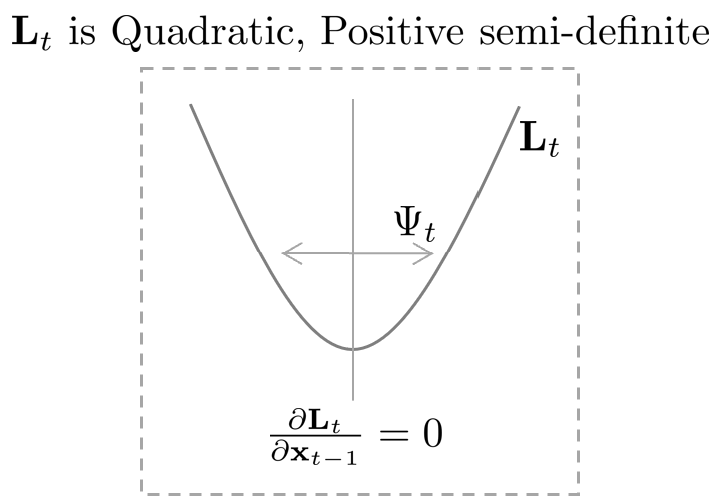

Igualando a derivada a zero,

$$\mathbf x_{t-1}^\star=\boldsymbol\Psi_t\big[\mathbf F_t^\top\mathbf Q_t^{-1}(\mathbf x_t-\mathbf B_t\mathbf u_t)+\mathbf P_{t-1}^{-1}\hat{\mathbf x}_{t-1}\big],$$

e então

$$\boxed{\mathbf L_t(\mathbf x_{t-1},\mathbf x_t)=\tfrac12(\mathbf x_{t-1}-\mathbf x_{t-1}^\star)^\top\boldsymbol\Psi_t^{-1}(\mathbf x_{t-1}-\mathbf x_{t-1}^\star).}$$

(Esta é só uma das maneiras de fazer a separação.) Posto dentro da exponencial, é uma gaussiana não normalizada em $\mathbf x_{t-1}$; como a área de uma gaussiana é 1,

$$\int\exp(-\mathbf L_t(\mathbf x_{t-1},\mathbf x_t))\,d\mathbf x_{t-1}=\det(2\pi\boldsymbol\Psi_t)^{1/2},$$

que **não depende de $\mathbf x_t$**. Logo $\overline{\mathrm{bel}}(\mathbf x_t)=\eta'\exp(-\mathbf L_t(\mathbf x_t))$, e falta só calcular $\mathbf L_t(\mathbf x_t)=\mathbf L_t-\mathbf L_t(\mathbf x_{t-1},\mathbf x_t)$. Expandindo, todos os termos quadráticos e lineares em $\mathbf x_{t-1}$ se cancelam (era esse o objetivo da separação), e sobra

$$\boxed{\begin{aligned}\mathbf L_t(\mathbf x_t)=\ &\tfrac12(\mathbf x_t-\mathbf B_t\mathbf u_t)^\top\mathbf Q_t^{-1}(\mathbf x_t-\mathbf B_t\mathbf u_t)+\tfrac12\hat{\mathbf x}_{t-1}^\top\mathbf P_{t-1}^{-1}\hat{\mathbf x}_{t-1}\\&-\tfrac12\big[\mathbf F_t^\top\mathbf Q_t^{-1}(\mathbf x_t-\mathbf B_t\mathbf u_t)+\mathbf P_{t-1}^{-1}\hat{\mathbf x}_{t-1}\big]^\top\boldsymbol\Psi_t\big[\mathbf F_t^\top\mathbf Q_t^{-1}(\mathbf x_t-\mathbf B_t\mathbf u_t)+\mathbf P_{t-1}^{-1}\hat{\mathbf x}_{t-1}\big]\end{aligned}}$$

Como $\overline{\mathrm{bel}}(\mathbf x_t)$ é gaussiana, $\mathbf L_t(\mathbf x_t)$ é quadrática, e de novo a primeira derivada dá a média e a segunda a covariância. Usando o **lema de inversão de matrizes** (Woodbury), $\mathbf Q^{-1}-\mathbf Q^{-1}\mathbf F(\mathbf F^\top\mathbf Q^{-1}\mathbf F+\mathbf P^{-1})^{-1}\mathbf F^\top\mathbf Q^{-1}=(\mathbf Q+\mathbf F\mathbf P\mathbf F^\top)^{-1}$, a derivada nula dá, depois de algumas simplificações,

$$\mathbf x_t=\mathbf B_t\mathbf u_t+\mathbf F_t\hat{\mathbf x}_{t-1},\qquad \frac{\partial^2\mathbf L_t(\mathbf x_t)}{\partial\mathbf x_t^2}=(\mathbf Q_t+\mathbf F_t\mathbf P_{t-1}\mathbf F_t^\top)^{-1},$$

isto é,

$$\boxed{\hat{\mathbf x}_{t|t-1}=\mathbf F_t\hat{\mathbf x}_{t-1|t-1}+\mathbf B_t\mathbf u_t,\qquad \mathbf P_{t|t-1}=\mathbf F_t\mathbf P_{t-1|t-1}\mathbf F_t^\top+\mathbf Q_t .}$$

**Conferência numérica.** Como $\int e^{-\mathbf L_t}d\mathbf x_{t-1}=\text{const}\cdot e^{-\min_{\mathbf x_{t-1}}\mathbf L_t}$ para $\mathbf L_t$ quadrática em $\mathbf x_{t-1}$, $\mathbf L_t(\mathbf x_t)$ é, a menos de constante, o **mínimo** de $\mathbf L_t$ em $\mathbf x_{t-1}$. Conferimos os quatro ingredientes da dedução com matrizes sorteadas.

In [19]:
n, m = 3, 2
A_ = rng.normal(size=(n, n)); P_prev = A_ @ A_.T + 0.5 * np.eye(n)
A_ = rng.normal(size=(n, n)); Q_d = A_ @ A_.T + 0.3 * np.eye(n)
F_d = rng.normal(size=(n, n)); B_d = rng.normal(size=(n, 1)); u_d = rng.normal(size=1)
x_prev = rng.normal(size=n)
Qi, Pi = np.linalg.inv(Q_d), np.linalg.inv(P_prev)

def L_tot(xt, xa):
    a = xt - F_d @ xa - B_d @ u_d; b = xa - x_prev
    return 0.5 * a @ Qi @ a + 0.5 * b @ Pi @ b

Psi = np.linalg.inv(F_d.T @ Qi @ F_d + Pi)
xt0 = rng.normal(size=n)
hess_num = jacobiano_numerico(lambda xa: jacobiano_numerico(lambda y: np.array([L_tot(xt0, y)]), xa).ravel(), x_prev, eps=1e-4)
confere("∂²L/∂x²_{t-1} = Ψ⁻¹ = FᵀQ⁻¹F + P⁻¹", hess_num, np.linalg.inv(Psi), tol=1e-5, relativo=True)

def x_estrela(xt):
    return Psi @ (F_d.T @ Qi @ (xt - B_d @ u_d) + Pi @ x_prev)
grad = jacobiano_numerico(lambda xa: np.array([L_tot(xt0, xa)]), x_estrela(xt0)).ravel()
confere("x*_{t-1} anula a derivada de L_t", grad, np.zeros(n), tol=1e-6)

# L_t(x_t) = min L_t ; deve ser ½(x−m)ᵀ(Q+FPFᵀ)⁻¹(x−m) + const
m_pred = F_d @ x_prev + B_d @ u_d; P_pred = F_d @ P_prev @ F_d.T + Q_d
Lmin = lambda xt: L_tot(xt, x_estrela(xt))
pts = rng.normal(size=(6, n)) * 2
lhs = np.array([Lmin(p) - Lmin(m_pred) for p in pts])
rhs = np.array([0.5 * (p - m_pred) @ np.linalg.solve(P_pred, p - m_pred) for p in pts])
confere("L_t(x_t) − L_t(m) = ½(x−m)ᵀ(FPFᵀ+Q)⁻¹(x−m): média F x̂ + B u e covariância FPFᵀ + Q", lhs, rhs, tol=1e-9)

lhs_w = Qi - Qi @ F_d @ Psi @ F_d.T @ Qi
confere("lema de inversão: Q⁻¹ − Q⁻¹F Ψ FᵀQ⁻¹ = (Q + FPFᵀ)⁻¹", lhs_w, np.linalg.inv(Q_d + F_d @ P_prev @ F_d.T), tol=1e-9, relativo=True)

OK   ∂²L/∂x²_{t-1} = Ψ⁻¹ = FᵀQ⁻¹F + P⁻¹:  diferença relativa máxima = 2.26e-06
OK   x*_{t-1} anula a derivada de L_t:  diferença máxima = 0.00e+00
OK   L_t(x_t) − L_t(m) = ½(x−m)ᵀ(FPFᵀ+Q)⁻¹(x−m): média F x̂ + B u e covariância FPFᵀ + Q:  diferença máxima = 4.44e-16
OK   lema de inversão: Q⁻¹ − Q⁻¹F Ψ FᵀQ⁻¹ = (Q + FPFᵀ)⁻¹:  diferença relativa máxima = 2.27e-16


## 8.2 Dedução da atualização (versão 1)

Queremos a média e a covariância de $\mathrm{bel}(\mathbf x_t)=\eta\,p(\mathbf z_t\mid\mathbf x_t)\,\overline{\mathrm{bel}}(\mathbf x_t)$, com $p(\mathbf z_t\mid\mathbf x_t)=\mathcal N(\mathbf H_t\mathbf x_t,\mathbf R_t)$ e $\overline{\mathrm{bel}}(\mathbf x_t)=\mathcal N(\hat{\mathbf x}_{t|t-1},\mathbf P_{t|t-1})$. Escrevendo $\mathrm{bel}(\mathbf x_t)=\eta\exp(-\mathbf J_t)$,

$$\boxed{\mathbf J_t=\tfrac12(\mathbf z_t-\mathbf H_t\mathbf x_t)^\top\mathbf R_t^{-1}(\mathbf z_t-\mathbf H_t\mathbf x_t)+\tfrac12(\mathbf x_t-\hat{\mathbf x}_{t|t-1})^\top\mathbf P_{t|t-1}^{-1}(\mathbf x_t-\hat{\mathbf x}_{t|t-1})}$$

(este $\mathbf J_t$ é uma função custo, e nada tem a ver com o jacobiano $\mathbf J$ do IESKF). Derivando,

$$\frac{\partial\mathbf J_t}{\partial\mathbf x_t}=-\mathbf H_t^\top\mathbf R_t^{-1}(\mathbf z_t-\mathbf H_t\mathbf x_t)+\mathbf P_{t|t-1}^{-1}(\mathbf x_t-\hat{\mathbf x}_{t|t-1}),\qquad \frac{\partial^2\mathbf J_t}{\partial\mathbf x_t^2}=\mathbf H_t^\top\mathbf R_t^{-1}\mathbf H_t+\mathbf P_{t|t-1}^{-1}=:\mathbf P_{t|t}^{-1}.$$

Igualando a primeira a zero e somando e subtraindo $\mathbf H_t\hat{\mathbf x}_{t|t-1}$,

$$\mathbf H_t^\top\mathbf R_t^{-1}(\mathbf z_t-\mathbf H_t\hat{\mathbf x}_{t|t-1})=(\mathbf H_t^\top\mathbf R_t^{-1}\mathbf H_t+\mathbf P_{t|t-1}^{-1})(\mathbf x_t-\hat{\mathbf x}_{t|t-1})=\mathbf P_{t|t}^{-1}(\mathbf x_t-\hat{\mathbf x}_{t|t-1}),$$

$$\therefore\quad \hat{\mathbf x}_{t|t}=\hat{\mathbf x}_{t|t-1}+\underbrace{\mathbf P_{t|t}\mathbf H_t^\top\mathbf R_t^{-1}}_{\mathbf K_t}(\mathbf z_t-\mathbf H_t\hat{\mathbf x}_{t|t-1}).$$

Isso dá a **forma de informação**: $\mathbf K_t=\mathbf P_{t|t}\mathbf H_t^\top\mathbf R_t^{-1}$, $\ \mathbf P_{t|t}=(\mathbf H_t^\top\mathbf R_t^{-1}\mathbf H_t+\mathbf P_{t|t-1}^{-1})^{-1}$. Inverter uma matriz do tamanho do estado a cada passo pode ser caro; pelo lema de inversão,

$$\mathbf P_{t|t}=\mathbf P_{t|t-1}-\mathbf P_{t|t-1}\mathbf H_t^\top(\mathbf R_t+\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top)^{-1}\mathbf H_t\mathbf P_{t|t-1}=(\mathbf I-\mathbf K_t\mathbf H_t)\mathbf P_{t|t-1},$$

e, multiplicando $\mathbf K_t=\mathbf P_{t|t}\mathbf H_t^\top\mathbf R_t^{-1}$ por $(\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top+\mathbf R_t)(\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top+\mathbf R_t)^{-1}=\mathbf I$ e simplificando, chega-se à forma usual

$$\boxed{\mathbf K_t=\mathbf P_{t|t-1}\mathbf H_t^\top(\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top+\mathbf R_t)^{-1},\qquad \hat{\mathbf x}_{t|t}=\hat{\mathbf x}_{t|t-1}+\mathbf K_t(\mathbf z_t-\mathbf H_t\hat{\mathbf x}_{t|t-1}),\qquad \mathbf P_{t|t}=(\mathbf I-\mathbf K_t\mathbf H_t)\mathbf P_{t|t-1}.}$$

> **Nota do tradutor.** No quadro final desta dedução, o original escreve "ganho de Kalman: $\mathbf K_t=\hat{\mathbf x}_{t|t-1}+\mathbf K_t(\mathbf z_t-\mathbf H_t\hat{\mathbf x}_{t|t-1})$", que é a linha da média copiada no lugar do ganho. Corrigido acima.

## 8.3 Dedução da atualização (versão 2): a gaussiana condicional

Como $\mathrm{bel}(\mathbf x_t)$ é o produto da verossimilhança pelo *a priori* (*a posteriori* = verossimilhança × *a priori*), sua média e covariância podem ser obtidas mais diretamente pela **densidade condicional**.

> **Dica (do original): a gaussiana condicional.** Se $\mathbf x$ e $\mathbf z$ são conjuntamente gaussianos, $p(\mathbf x\mid\mathbf z)=p(\mathbf x,\mathbf z)/p(\mathbf z)=\eta\,p(\mathbf z\mid\mathbf x)p(\mathbf x)\sim\mathcal N(\mathbb E(\mathbf x\mid\mathbf z),\mathbf C_{x|z})$, com
> $$\boxed{\mathbb E(\mathbf x\mid\mathbf z)=\mathbb E(\mathbf x)+\mathbf C_{xz}\mathbf C_{zz}^{-1}(\mathbf z-\mathbb E(\mathbf z)),\qquad \mathbf C_{x|z}=\mathbf C_{xx}-\mathbf C_{xz}\mathbf C_{zz}^{-1}\mathbf C_{xz}^\top.}$$

Com $\mathbf x\sim\mathcal N(\hat{\mathbf x}_{t|t-1},\mathbf P_{t|t-1})$ e $\mathbf z=\mathbf H_t\mathbf x+\mathbf v$: $\ \mathbf C_{xx}=\mathbf P_{t|t-1}$, $\ \mathbf C_{xz}=\mathbf P_{t|t-1}\mathbf H_t^\top$, $\ \mathbf C_{zz}=\mathbf H_t\mathbf P_{t|t-1}\mathbf H_t^\top+\mathbf R_t$, e $\mathbf K_t=\mathbf C_{xz}\mathbf C_{zz}^{-1}$. A figura do original resume a correspondência (lembre a troca $\mathbf Q\leftrightarrow\mathbf R$ da nota acima):

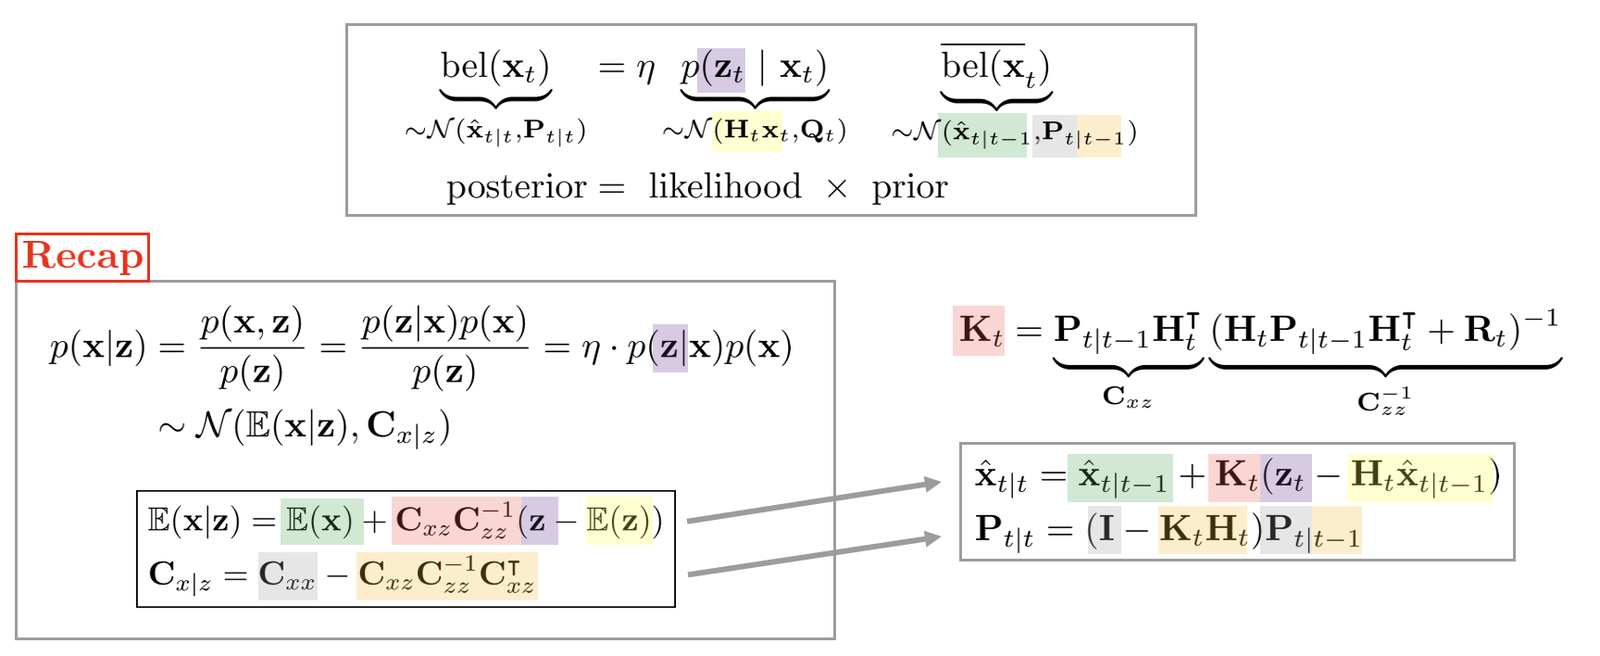

**Conferência.** Abaixo, as três formas da correção (informação, usual e condicional) devem coincidir. E, como ilustração, sorteamos muitos pares $(\mathbf x,\mathbf z)$ da distribuição conjunta e fazemos a **regressão linear de $\mathbf x$ em $\mathbf z$** por mínimos quadrados: o coeficiente da regressão é o ganho de Kalman. Esta é a ponte entre o Kalman e os mínimos quadrados, que é a tese de `mq_hmm_kalman_duas_trilhas`.

In [20]:
n, m = 3, 2
A_ = rng.normal(size=(n, n)); Pp = A_ @ A_.T + 0.5 * np.eye(n)
A_ = rng.normal(size=(m, m)); Rr = A_ @ A_.T + 0.5 * np.eye(m)
Hh = rng.normal(size=(m, n)); xh = rng.normal(size=n); zz = rng.normal(size=m)

# versão 1, forma de informação
P_inf = np.linalg.inv(Hh.T @ np.linalg.inv(Rr) @ Hh + np.linalg.inv(Pp))
K_inf = P_inf @ Hh.T @ np.linalg.inv(Rr)
# versão 1, forma usual
x_us, P_us, K_us = kf_correcao(xh, Pp, zz, Hh, Rr)
# versão 2, condicional
Cxz, Czz = Pp @ Hh.T, Hh @ Pp @ Hh.T + Rr
x_cond = xh + Cxz @ np.linalg.solve(Czz, zz - Hh @ xh)
P_cond = Pp - Cxz @ np.linalg.solve(Czz, Cxz.T)
confere("ganho: P_{t|t} Hᵀ R⁻¹ = P Hᵀ (H P Hᵀ + R)⁻¹", K_inf, K_us, tol=1e-10)
confere("covariância: (HᵀR⁻¹H + P⁻¹)⁻¹ = (I − KH)P", P_inf, P_us, tol=1e-10)
confere("versão 2 (condicional) = versão 1 (média)", x_cond, x_us, tol=1e-10)
confere("versão 2 (condicional) = versão 1 (covariância)", P_cond, P_us, tol=1e-10)

# regressão de x em z, por mínimos quadrados, sobre amostras da conjunta
N_mc = 400_000
xs_mc = rng.multivariate_normal(xh, Pp, N_mc)
zs_mc = xs_mc @ Hh.T + rng.multivariate_normal(np.zeros(m), Rr, N_mc)
Zc, Xc = zs_mc - zs_mc.mean(0), xs_mc - xs_mc.mean(0)
coef = np.linalg.lstsq(Zc, Xc, rcond=None)[0].T          # x − x̄ ≈ coef (z − z̄)
confere("coeficiente da regressão de x em z = ganho de Kalman (Monte Carlo)", coef, K_us, tol=2e-2, relativo=True)

OK   ganho: P_{t|t} Hᵀ R⁻¹ = P Hᵀ (H P Hᵀ + R)⁻¹:  diferença máxima = 4.44e-16
OK   covariância: (HᵀR⁻¹H + P⁻¹)⁻¹ = (I − KH)P:  diferença máxima = 8.88e-16
OK   versão 2 (condicional) = versão 1 (média):  diferença máxima = 5.55e-17
OK   versão 2 (condicional) = versão 1 (covariância):  diferença máxima = 2.22e-16


OK   coeficiente da regressão de x em z = ganho de Kalman (Monte Carlo):  diferença relativa máxima = 1.37e-03


---
# 9. MAP, Gauss–Newton e EKF

## 9.1 A dedução tradicional do EKF

Considere a observação do EKF com o ruído do lado de fora, por conveniência: $\mathbf z_t=\mathbf h(\mathbf x_t)+\mathbf v_t$. A correção do EKF desenvolve $\mathrm{bel}(\mathbf x_t)=\eta\,p(\mathbf z_t\mid\mathbf x_t)\,\overline{\mathrm{bel}}(\mathbf x_t)$, com $p(\mathbf z_t\mid\mathbf x_t)=\mathcal N(\mathbf h(\mathbf x_t),\mathbf R_t)$ e $\overline{\mathrm{bel}}(\mathbf x_t)=\mathcal N(\hat{\mathbf x}_{t|t-1},\mathbf P_{t|t-1})$, e chega a

$$\boxed{\hat{\mathbf x}_{t|t}=\hat{\mathbf x}_{t|t-1}+\mathbf K_t(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t-1})),\qquad \mathbf P_{t|t}=(\mathbf I-\mathbf K_t\mathbf H_t)\mathbf P_{t|t-1}.}$$

> **Nota do tradutor.** No original, o quadro desta subseção omite o termo $\hat{\mathbf x}_{t|t-1}+$ na média.

## 9.2 A dedução do EKF pelo MAP

**Partindo do estimador MAP** (seguindo a referência [12] do original). A correção pode ser obtida pela estimação de **máximo *a posteriori***:

$$\hat{\mathbf x}_{t|t}=\arg\max_{\mathbf x_t}\mathrm{bel}(\mathbf x_t)=\arg\max_{\mathbf x_t}p(\mathbf z_t\mid\mathbf x_t)\,\overline{\mathrm{bel}}(\mathbf x_t)=\arg\max_{\mathbf x_t}\exp\Big(-\tfrac12\big[(\mathbf z_t-\mathbf h(\mathbf x_t))^\top\mathbf R_t^{-1}(\mathbf z_t-\mathbf h(\mathbf x_t))+(\mathbf x_t-\hat{\mathbf x}_{t|t-1})^\top\mathbf P_{t|t-1}^{-1}(\mathbf x_t-\hat{\mathbf x}_{t|t-1})\big]\Big).$$

Tirando o logaritmo e o sinal negativo, o máximo vira um mínimo:

$$\boxed{\hat{\mathbf x}_{t|t}=\arg\min_{\mathbf x_t}\ \|\mathbf z_t-\mathbf h(\mathbf x_t)\|^2_{\mathbf R_t^{-1}}+\|\mathbf x_t-\hat{\mathbf x}_{t|t-1}\|^2_{\mathbf P_{t|t-1}^{-1}}}$$

com $\|\mathbf a\|^2_{\mathbf B}=\mathbf a^\top\mathbf B\mathbf a$, a norma de Mahalanobis (ao quadrado).

> **Nota do tradutor.** No original, a forma de minimização ainda aparece dentro de um $\exp(\cdot)$, e com o índice deslocado ($\mathbf P^{-1_{t|t-1}}$). Como $\exp$ é crescente, o argumento do mínimo não muda, mas o que se minimiza é o expoente, e não a exponencial; corrigido.

Em forma matricial, o custo é

$$\mathbf C_t=\begin{bmatrix}\hat{\mathbf x}_{t|t-1}-\mathbf x_t\\\mathbf z_t-\mathbf h(\mathbf x_t)\end{bmatrix}^\top\begin{bmatrix}\mathbf P_{t|t-1}^{-1}&\mathbf 0\\\mathbf 0&\mathbf R_t^{-1}\end{bmatrix}\begin{bmatrix}\hat{\mathbf x}_{t|t-1}-\mathbf x_t\\\mathbf z_t-\mathbf h(\mathbf x_t)\end{bmatrix}.$$

**Uma nova função de observação, e o MLE.** Esse custo é o de uma observação aumentada:

$$\boxed{\mathbf y_t=\mathbf g(\mathbf x_t)+\mathbf e_t,\quad \mathbf y_t=\begin{bmatrix}\hat{\mathbf x}_{t|t-1}\\\mathbf z_t\end{bmatrix},\quad \mathbf g(\mathbf x_t)=\begin{bmatrix}\mathbf x_t\\\mathbf h(\mathbf x_t)\end{bmatrix},\quad \mathbf e_t\sim\mathcal N(0,\mathbf P_{\mathbf e}),\quad \mathbf P_{\mathbf e}=\begin{bmatrix}\mathbf P_{t|t-1}&\mathbf 0\\\mathbf 0&\mathbf R_t\end{bmatrix}}$$

A predição entra como uma **medida a mais** do estado. Linearizando, $\mathbf g(\mathbf x_t)\approx\mathbf g(\hat{\mathbf x}_{t|t-1})+\mathbf J_t(\mathbf x_t-\hat{\mathbf x}_{t|t-1})$, com $\mathbf J_t=\begin{bmatrix}\mathbf I\\\mathbf H_t\end{bmatrix}$. O problema MAP de $\mathrm{bel}(\mathbf x_t)$ vira o problema de **máxima verossimilhança** (MLE) de $p(\mathbf y_t\mid\mathbf x_t)$:

$$\hat{\mathbf x}_{t|t}=\arg\min_{\mathbf x_t}\ \|\mathbf y_t-\mathbf g(\mathbf x_t)\|^2_{\mathbf P_{\mathbf e}^{-1}},$$

um problema de **mínimos quadrados ponderados** (WLS).

## 9.3 Gauss–Newton

Linearizando em $\hat{\mathbf x}_{t|t-1}$ e chamando $\delta\mathbf x=\mathbf x_t-\hat{\mathbf x}_{t|t-1}$ e $\mathbf r_t=\mathbf y_t-\mathbf g(\hat{\mathbf x}_{t|t-1})$, o problema vira $\arg\min\|\mathbf J_t\delta\mathbf x-\mathbf r_t\|^2_{\mathbf P_{\mathbf e}^{-1}}$, cuja solução são as **equações normais** de Gauss–Newton:

$$(\mathbf J_t^\top\mathbf P_{\mathbf e}^{-1}\mathbf J_t)\,\delta\mathbf x=\mathbf J_t^\top\mathbf P_{\mathbf e}^{-1}\mathbf r_t\quad\Longrightarrow\quad \boxed{\delta\mathbf x=(\mathbf J_t^\top\mathbf P_{\mathbf e}^{-1}\mathbf J_t)^{-1}\mathbf J_t^\top\mathbf P_{\mathbf e}^{-1}\mathbf r_t}$$

A matriz $\tilde{\mathbf H}=\mathbf J_t^\top\mathbf P_{\mathbf e}^{-1}\mathbf J_t$ é a **hessiana aproximada**.

**Covariância *a posteriori*.** Como $\mathbb E(\mathbf r_t\mathbf r_t^\top)=\mathbf P_{\mathbf e}$, a covariância do estimador é

$$\mathbf P_{t|t}=(\mathbf J_t^\top\mathbf P_{\mathbf e}^{-1}\mathbf J_t)^{-1}=\Big(\begin{bmatrix}\mathbf I&\mathbf H_t^\top\end{bmatrix}\begin{bmatrix}\mathbf P_{t|t-1}&\mathbf 0\\\mathbf 0&\mathbf R_t\end{bmatrix}^{-1}\begin{bmatrix}\mathbf I\\\mathbf H_t\end{bmatrix}\Big)^{-1}=(\mathbf P_{t|t-1}^{-1}+\mathbf H_t^\top\mathbf R_t^{-1}\mathbf H_t)^{-1}=(\mathbf I-\mathbf K_t\mathbf H_t)\mathbf P_{t|t-1}.$$

Ou seja, **a inversa da hessiana aproximada de Gauss–Newton é a covariância *a posteriori* do EKF**: $\tilde{\mathbf H}^{-1}=\mathbf P_{t|t}$.

> **Nota do tradutor.** O original abre essa conta com $\mathbf P_{t|t}=\mathbb E[(\mathbf x_t-\hat{\mathbf x}_{t|t-1})(\cdot)^\top]$, que é a covariância **da predição**. O que se calcula é a covariância do **estimador** $\delta\mathbf x$ em torno do valor verdadeiro, isto é, do erro *a posteriori*; o resultado final está certo.

**Média *a posteriori*.** Repetindo Gauss–Newton, a $j$-ésima iteração é

$$\begin{aligned}
\hat{\mathbf x}_{t|t,j+1}&=\hat{\mathbf x}_{t|t,j}+(\mathbf J_{t,j}^\top\mathbf P_{\mathbf e}^{-1}\mathbf J_{t,j})^{-1}\mathbf J_{t,j}^\top\mathbf P_{\mathbf e}^{-1}\big(\mathbf y_t-\mathbf g(\hat{\mathbf x}_{t|t,j})\big)\\
&=(\mathbf P_{t|t-1}^{-1}+\mathbf H_{t,j}^\top\mathbf R_t^{-1}\mathbf H_{t,j})^{-1}\big(\mathbf H_{t,j}^\top\mathbf R_t^{-1}(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j})+\mathbf H_{t,j}\hat{\mathbf x}_{t|t,j})+\mathbf P_{t|t-1}^{-1}\hat{\mathbf x}_{t|t-1}\big)\\
&=\hat{\mathbf x}_{t|t-1}+\mathbf K_{t,j}\big(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j})-\mathbf H_{t,j}(\hat{\mathbf x}_{t|t-1}-\hat{\mathbf x}_{t|t,j})\big).
\end{aligned}$$

A última linha é o **IEKF** (na forma correta, com a soma feita à predição). Estimar a correção do EKF por Gauss–Newton e estimá-la pelo IEKF são a mesma coisa. Na primeira iteração, $\hat{\mathbf x}_{t|t,0}=\hat{\mathbf x}_{t|t-1}$, e a fórmula se reduz a $\hat{\mathbf x}_{t|t}=\hat{\mathbf x}_{t|t-1}+\mathbf K_t(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t-1}))$, a solução do EKF. Isto é: **o EKF é Gauss–Newton com uma iteração, e o IEKF é Gauss–Newton até convergir.**

> **Nota do tradutor.** Na segunda linha dessa dedução, o original escreve o peso como $\mathbf P_{t|t-1}^{-1}$ em vez de $\mathbf P_{\mathbf e}^{-1}$. Não é só notação: $\mathbf J_t$ tem $n+m$ linhas e $\mathbf P_{t|t-1}^{-1}$ é $n\times n$, então o produto $\mathbf J_t^\top\mathbf P_{t|t-1}^{-1}\mathbf J_t$ **nem está definido**. A célula abaixo mostra isso e confere o resto com $\mathbf P_{\mathbf e}^{-1}$.

In [21]:
def gauss_newton_aumentado(x_pred, P, z, h, Hfun, R, n_iter=30):
    # Gauss–Newton sobre y = [x̂_{t|t-1}; z], g(x) = [x; h(x)], peso P_e⁻¹
    n = len(x_pred)
    Pe_inv = np.linalg.inv(np.block([[P, np.zeros((n, len(z)))], [np.zeros((len(z), n)), R]]))
    y = np.concatenate([x_pred, z])
    xj = x_pred.copy(); hist = [xj.copy()]; Htil = []
    for j in range(n_iter):
        J = np.vstack([np.eye(n), Hfun(xj)])
        r = y - np.concatenate([xj, h(xj)])
        Ht = J.T @ Pe_inv @ J
        xj = xj + np.linalg.solve(Ht, J.T @ Pe_inv @ r)
        hist.append(xj.copy()); Htil.append(Ht)
    return np.array(hist), Htil

hist_gn, Htil = gauss_newton_aumentado(xp_rb, P_rb, z_rb, h_rb, H_rb, R_rb)
n_cmp = min(len(it_c), 8)
confere("iterados de Gauss–Newton no problema aumentado = iterados do IEKF correto", hist_gn[:n_cmp], it_c[:n_cmp], tol=1e-9)
x_ekf1, P_ekf1, _ = kf_correcao(xp_rb, P_rb, z_rb - h_rb(xp_rb) + H_rb(xp_rb) @ xp_rb, H_rb(xp_rb), R_rb)
confere("primeira iteração de Gauss–Newton = EKF", hist_gn[1], x_ekf1, tol=1e-12)
confere("inversa da hessiana aproximada (1ª iteração) = P_{t|t} do EKF", np.linalg.inv(Htil[0]), P_ekf1, tol=1e-12)

J0 = np.vstack([np.eye(2), H_rb(xp_rb)])
try:
    J0.T @ np.linalg.inv(P_rb) @ J0
except ValueError as e:
    print("equação impressa no original, Jᵀ P_{t|t-1}⁻¹ J  →  ValueError:", e)

OK   iterados de Gauss–Newton no problema aumentado = iterados do IEKF correto:  diferença máxima = 6.66e-16
OK   primeira iteração de Gauss–Newton = EKF:  diferença máxima = 6.66e-16
OK   inversa da hessiana aproximada (1ª iteração) = P_{t|t} do EKF:  diferença máxima = 6.65e-16
equação impressa no original, Jᵀ P_{t|t-1}⁻¹ J  →  ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 2 is different from 4)


---
# 10. Dedução da correção do IESKF

Esta seção mostra as contas intermediárias que levam do problema MAP do IESKF (seção 7) à fórmula de $\delta\hat{\mathbf x}$. Simplificando os símbolos,

$$\mathbf x=\arg\min_{\mathbf x}\ \|\mathbf z-\mathbf H\mathbf x\|^2_{\mathbf R^{-1}}+\|\mathbf c+\mathbf J\mathbf x\|^2_{\mathbf P^{-1}},$$

com $\mathbf z=\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j},0,0)$, $\ \mathbf c=\hat{\mathbf x}_{t|t,j}\boxminus\hat{\mathbf x}_{t|t-1}$, $\ \mathbf R=\mathbf H_{\mathbf v}\mathbf R_t\mathbf H_{\mathbf v}^\top$ (a **covariância** do ruído linearizado), $\ \mathbf P=\mathbf P_{t|t-1}$ e $\mathbf x=\delta\hat{\mathbf x}$.

**Expandindo as normas** (o termo entre colchetes, chamado $\mathbf r$ no original),

$$\mathbf r=\mathbf z^\top\mathbf R^{-1}\mathbf z-2\mathbf x^\top\mathbf H^\top\mathbf R^{-1}\mathbf z+\mathbf x^\top\mathbf H^\top\mathbf R^{-1}\mathbf H\mathbf x+\mathbf c^\top\mathbf P^{-1}\mathbf c+2\mathbf x^\top\mathbf J^\top\mathbf P^{-1}\mathbf c+\mathbf x^\top\mathbf J^\top\mathbf P^{-1}\mathbf J\mathbf x,$$

usando $\mathbf a^\top\mathbf b=\mathbf b^\top\mathbf a$. **Derivando e igualando a zero**,

$$(\mathbf H^\top\mathbf R^{-1}\mathbf H+\mathbf J^\top\mathbf P^{-1}\mathbf J)\,\mathbf x=\mathbf H^\top\mathbf R^{-1}\mathbf z-\mathbf J^\top\mathbf P^{-1}\mathbf c\quad\Longrightarrow\quad \mathbf x=(\mathbf H^\top\mathbf R^{-1}\mathbf H+\mathbf J^\top\mathbf P^{-1}\mathbf J)^{-1}(\mathbf H^\top\mathbf R^{-1}\mathbf z-\mathbf J^\top\mathbf P^{-1}\mathbf c).$$

**Lema de inversão.** Com $\bar{\mathbf P}=\mathbf J^{-1}\mathbf P\mathbf J^{-\top}$ (logo $\mathbf J^\top\mathbf P^{-1}\mathbf J=\bar{\mathbf P}^{-1}$),

$$(\bar{\mathbf P}^{-1}+\mathbf H^\top\mathbf R^{-1}\mathbf H)^{-1}=\bar{\mathbf P}-\bar{\mathbf P}\mathbf H^\top(\mathbf R+\mathbf H\bar{\mathbf P}\mathbf H^\top)^{-1}\mathbf H\bar{\mathbf P}.$$

> **Dica (do original): lema de inversão de matrizes.** $(\mathbf A+\mathbf U\mathbf C\mathbf V)^{-1}=\mathbf A^{-1}-\mathbf A^{-1}\mathbf U(\mathbf C^{-1}+\mathbf V\mathbf A^{-1}\mathbf U)^{-1}\mathbf V\mathbf A^{-1}$.

**Expandindo e eliminando termos**, usando $\mathbf H\bar{\mathbf P}\mathbf H^\top\mathbf R^{-1}=(\mathbf H\bar{\mathbf P}\mathbf H^\top+\mathbf R)\mathbf R^{-1}-\mathbf I$, os dois termos $\bar{\mathbf P}\mathbf H^\top\mathbf R^{-1}\mathbf z$ se cancelam, e sobra

$$\mathbf x=-\bar{\mathbf P}\mathbf J^\top\mathbf P^{-1}\mathbf c+\bar{\mathbf P}\mathbf H^\top\mathbf S^{-1}\mathbf z+\bar{\mathbf P}\mathbf H^\top\mathbf S^{-1}\mathbf H\bar{\mathbf P}\mathbf J^\top\mathbf P^{-1}\mathbf c,\qquad \mathbf S=\mathbf R+\mathbf H\bar{\mathbf P}\mathbf H^\top .$$

**Recuperando $\bar{\mathbf P}=\mathbf J^{-1}\mathbf P\mathbf J^{-\top}$** (então $\bar{\mathbf P}\mathbf J^\top\mathbf P^{-1}=\mathbf J^{-1}$) e **definindo $\mathbf K=\mathbf J^{-1}\mathbf P\mathbf J^{-\top}\mathbf H^\top\mathbf S^{-1}$**,

$$\mathbf x=\mathbf K\mathbf z+\mathbf K\mathbf H\mathbf J^{-1}\mathbf c-\mathbf J^{-1}\mathbf c,$$

e, **restaurando os símbolos**,

$$\boxed{\delta\hat{\mathbf x}_{t|t,j}=\mathbf K_{t,j}\big(\mathbf z_t-\mathbf h(\hat{\mathbf x}_{t|t,j},0,0)+\mathbf H_{t,j}\mathbf J_{t,j}^{-1}(\hat{\mathbf x}_{t|t,j}\boxminus\hat{\mathbf x}_{t|t-1})\big)-\mathbf J_{t,j}^{-1}(\hat{\mathbf x}_{t|t,j}\boxminus\hat{\mathbf x}_{t|t-1}).}$$

> **Nota do tradutor.** O original define o símbolo simplificado como "$\mathbf R=\mathbf H_{\mathbf v}\mathbf R^{-1}\mathbf H_{\mathbf v}^\top$" e depois usa $\mathbf R$ como **covariância** (em $\mathbf S=\mathbf R+\mathbf H\bar{\mathbf P}\mathbf H^\top$). Só a segunda leitura é consistente; a definição foi corrigida acima (é a mesma nota da seção 7).

As duas figuras a seguir são o resumo visual do autor para esta dedução (passos [1] a [14]):

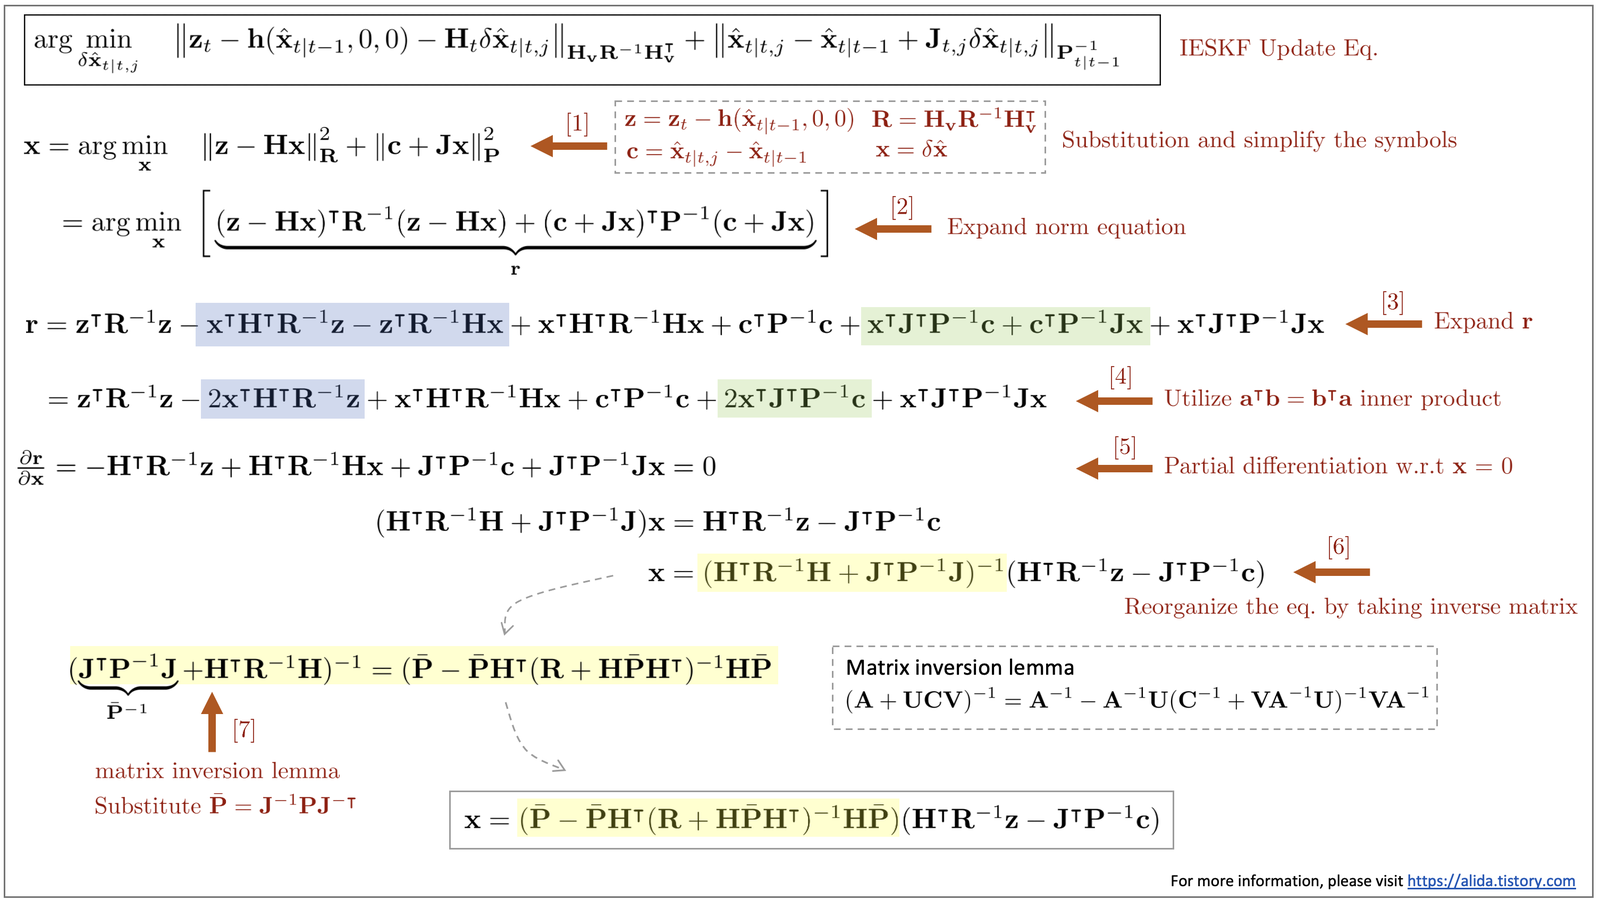

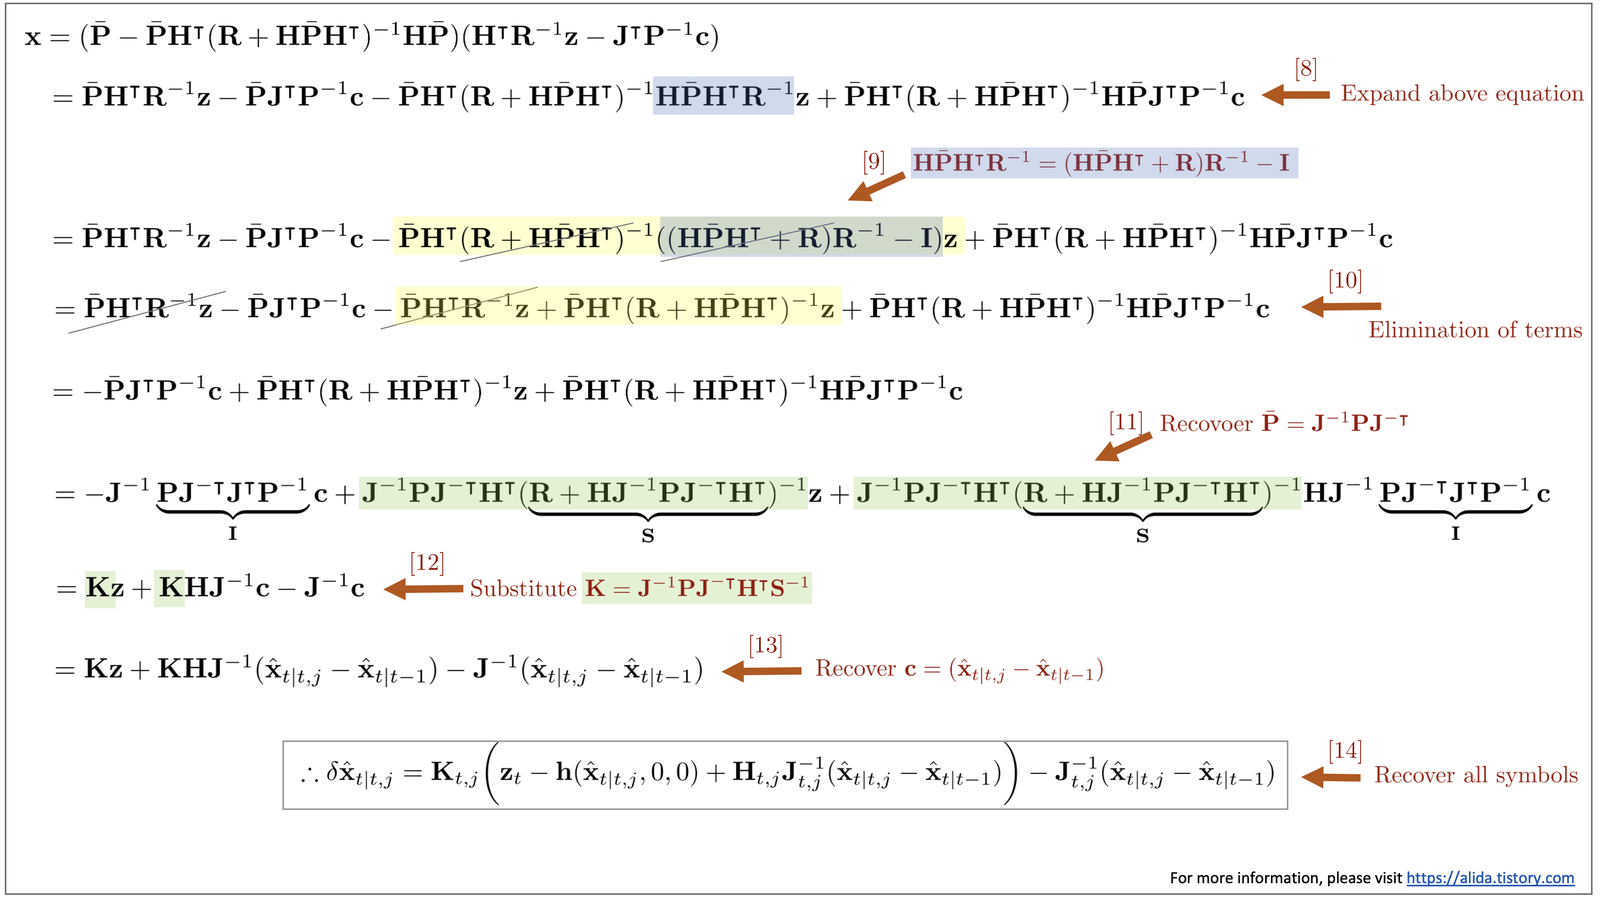

**Conferência.** Com matrizes sorteadas (inclusive um $\mathbf J$ qualquer, invertível), cada forma intermediária deve dar o mesmo $\mathbf x$.

In [22]:
n, m = 4, 3
A_ = rng.normal(size=(n, n)); Pq = A_ @ A_.T + 0.5 * np.eye(n)
A_ = rng.normal(size=(m, m)); Rq = A_ @ A_.T + 0.5 * np.eye(m)
Hq = rng.normal(size=(m, n)); Jq = np.eye(n) + 0.3 * rng.normal(size=(n, n))
zq, cq = rng.normal(size=m), rng.normal(size=n)
Ri, Pinv, Ji = np.linalg.inv(Rq), np.linalg.inv(Pq), np.linalg.inv(Jq)

x_normais = np.linalg.solve(Hq.T @ Ri @ Hq + Jq.T @ Pinv @ Jq, Hq.T @ Ri @ zq - Jq.T @ Pinv @ cq)
x_otim = least_squares(lambda x: np.concatenate([np.linalg.cholesky(Ri).T @ (zq - Hq @ x),
                                                 np.linalg.cholesky(Pinv).T @ (cq + Jq @ x)]), np.zeros(n),
                       xtol=1e-15, ftol=1e-15, gtol=1e-15).x
Pbar = Ji @ Pq @ Ji.T
lema = Pbar - Pbar @ Hq.T @ np.linalg.solve(Rq + Hq @ Pbar @ Hq.T, Hq @ Pbar)
S_q = Rq + Hq @ Pbar @ Hq.T
K_q = Pbar @ Hq.T @ np.linalg.inv(S_q)
x_final = K_q @ zq + K_q @ Hq @ Ji @ cq - Ji @ cq

confere("equações normais = mínimo do problema (otimização direta)", x_normais, x_otim, tol=1e-6)
confere("lema de inversão com P̄ = J⁻¹PJ⁻ᵀ", lema, np.linalg.inv(Jq.T @ Pinv @ Jq + Hq.T @ Ri @ Hq), tol=1e-9, relativo=True)
confere("forma final: Kz + KHJ⁻¹c − J⁻¹c = solução das equações normais", x_final, x_normais, tol=1e-9)
confere("covariância: (I − KH) J⁻¹PJ⁻ᵀ = (HᵀR⁻¹H + JᵀP⁻¹J)⁻¹", (np.eye(n) - K_q @ Hq) @ Pbar,
        np.linalg.inv(Hq.T @ Ri @ Hq + Jq.T @ Pinv @ Jq), tol=1e-9, relativo=True)

OK   equações normais = mínimo do problema (otimização direta):  diferença máxima = 1.42e-08
OK   lema de inversão com P̄ = J⁻¹PJ⁻ᵀ:  diferença relativa máxima = 1.17e-15
OK   forma final: Kz + KHJ⁻¹c − J⁻¹c = solução das equações normais:  diferença máxima = 6.66e-16
OK   covariância: (I − KH) J⁻¹PJ⁻ᵀ = (HᵀR⁻¹H + JᵀP⁻¹J)⁻¹:  diferença relativa máxima = 1.17e-15


---
# 11. Resumo em slides

As explicações de KF, EKF, ESKF, IEKF e IESKF podem ser resumidas, cada uma, num único slide.

### Filtro de Kalman (KF)
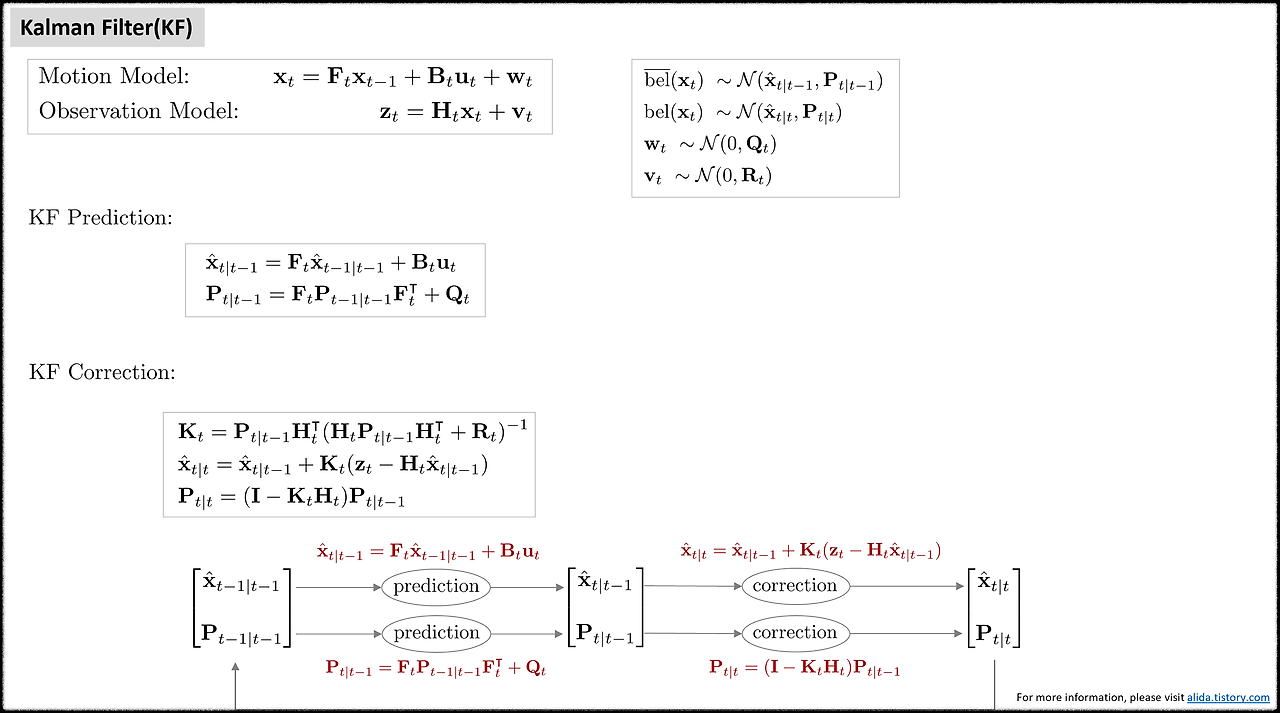

### Filtro de Kalman estendido (EKF)
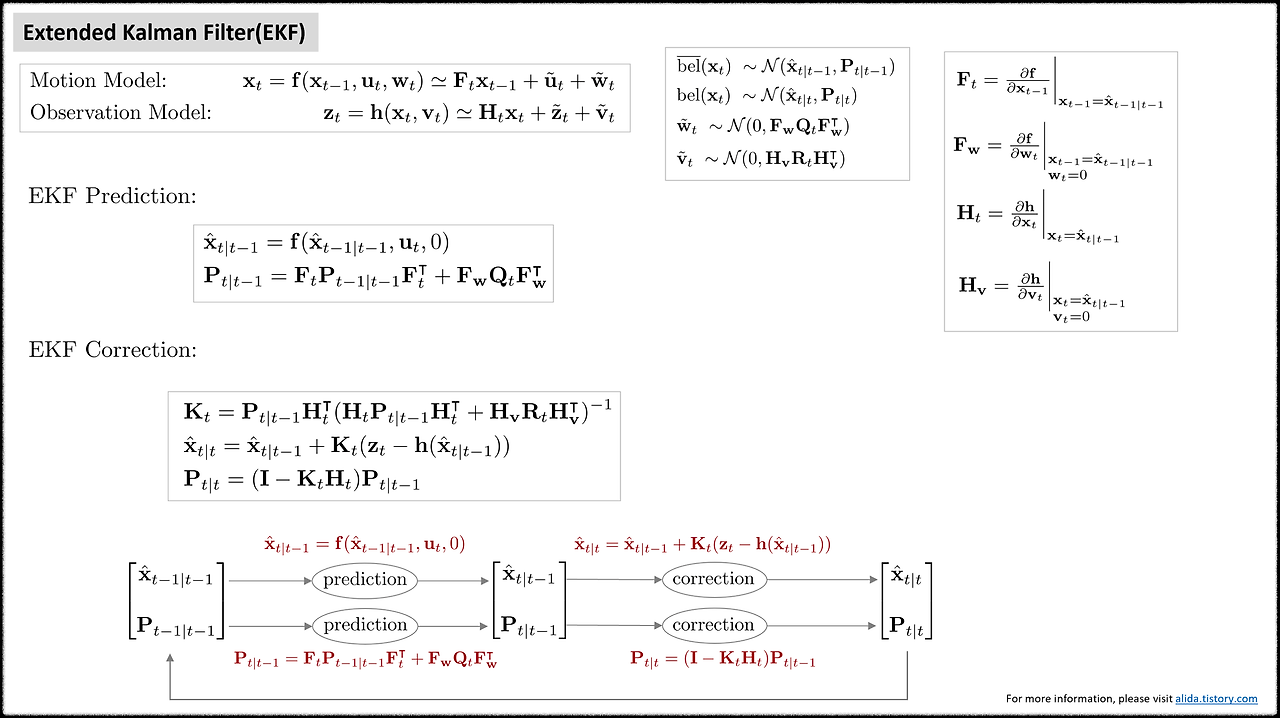

### Filtro de Kalman de estado de erro (ESKF)
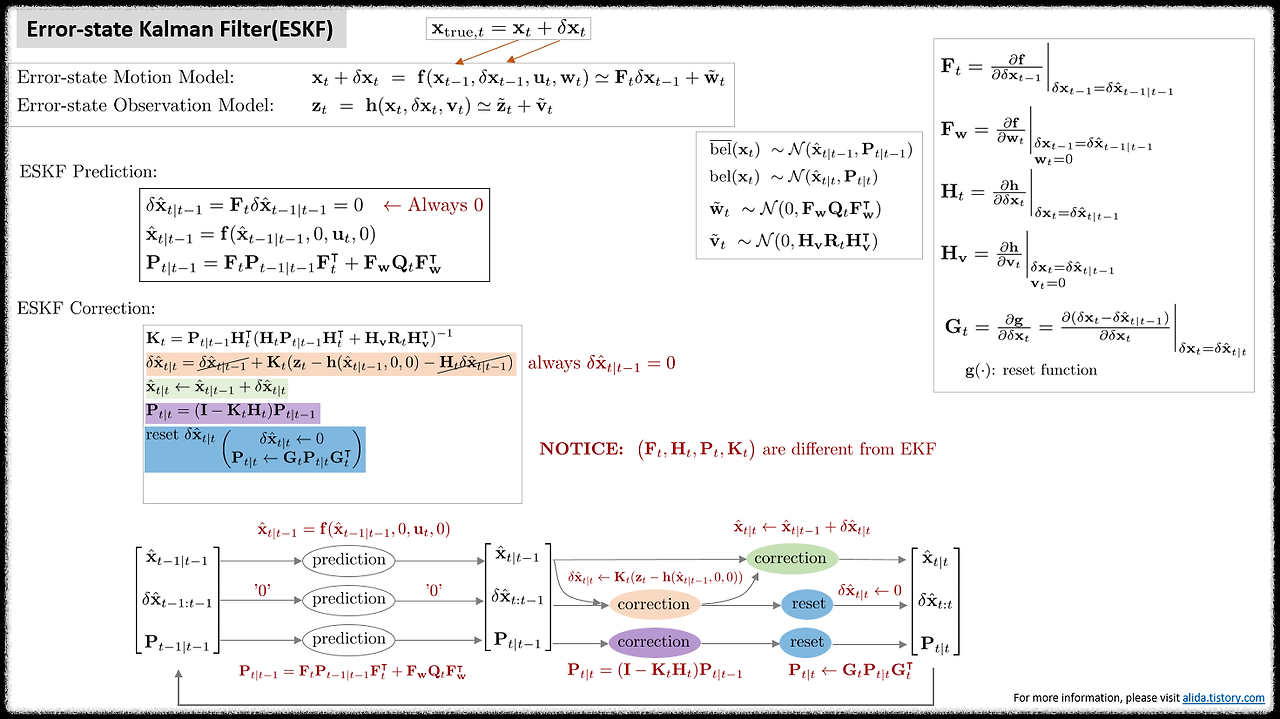

### Filtro de Kalman estendido iterado (IEKF)
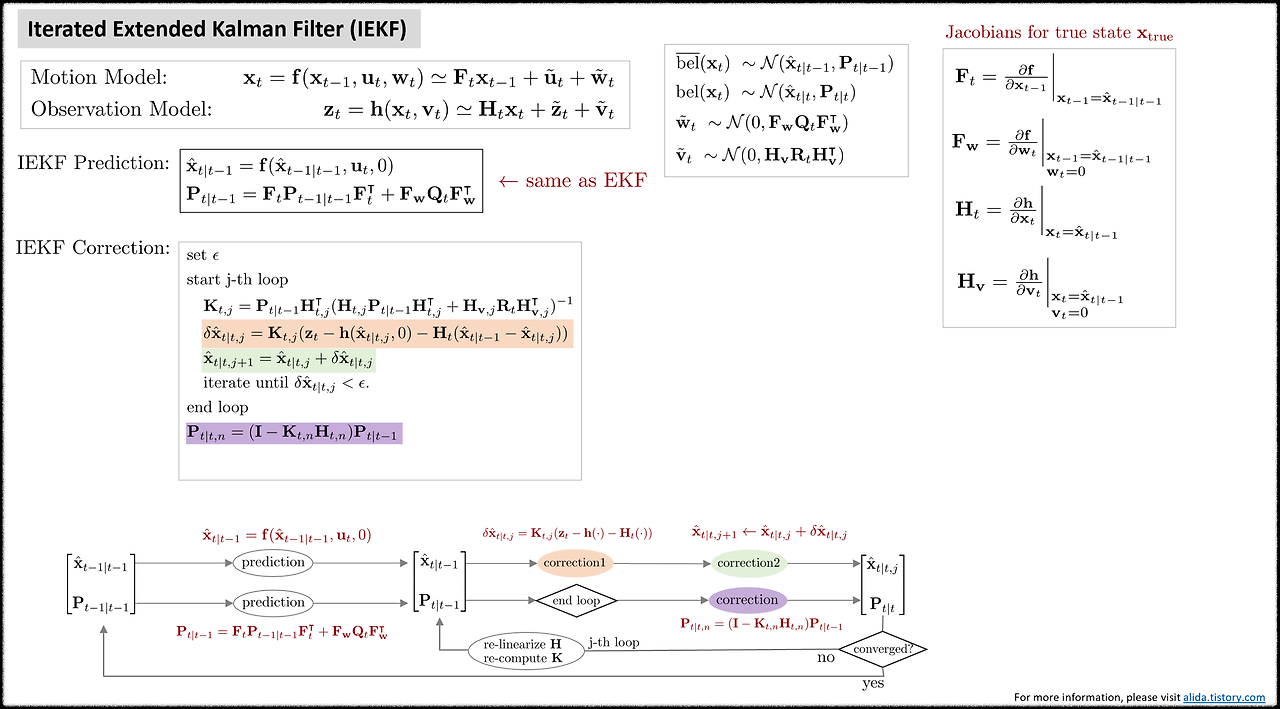

> **Nota do tradutor.** No slide do IEKF, a linha $\hat{\mathbf x}_{t|t,j+1}=\hat{\mathbf x}_{t|t,j}+\delta\hat{\mathbf x}_{t|t,j}$, com $\delta\hat{\mathbf x}_{t|t,j}=\mathbf K_{t,j}(\mathbf z_t-\mathbf h(\cdot)-\mathbf H_t(\hat{\mathbf x}_{t|t-1}-\hat{\mathbf x}_{t|t,j}))$, tem o erro discutido na seção 6: a soma deve ser feita à predição $\hat{\mathbf x}_{t|t-1}$.

### Filtro de Kalman de estado de erro iterado (IESKF)
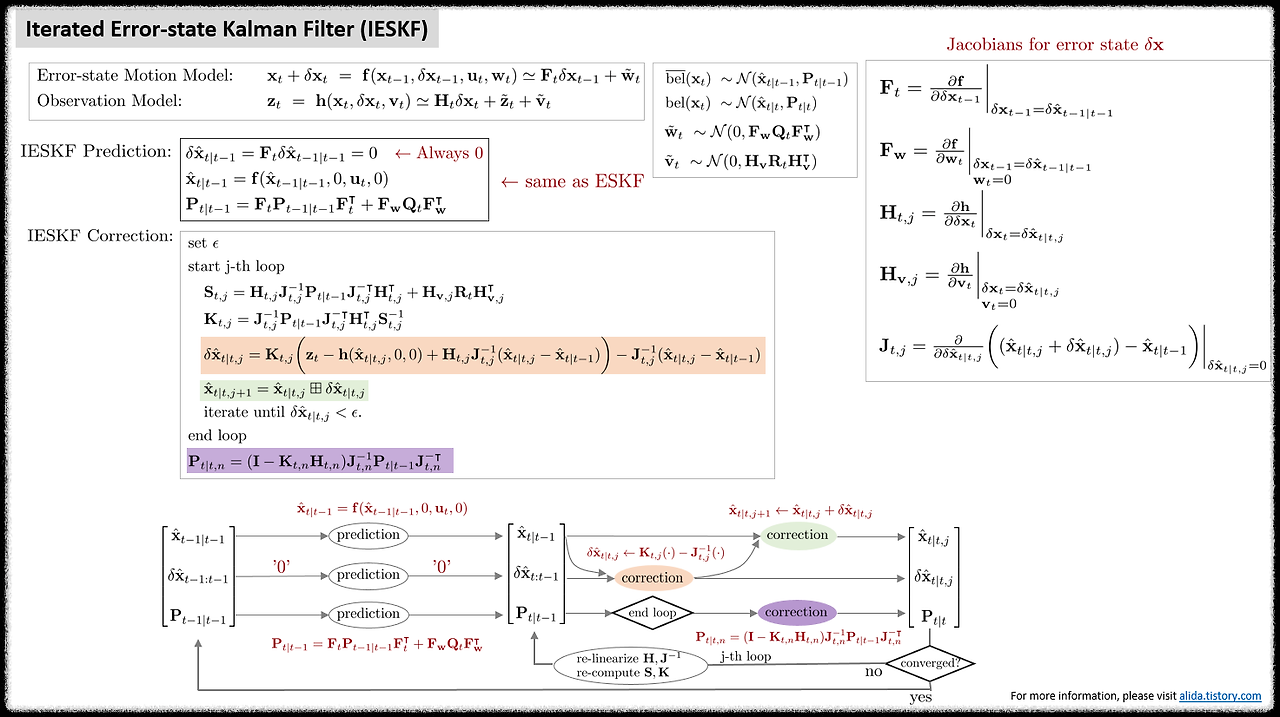

### Figuras do código-fonte que o texto não usa

O arquivo do arXiv traz mais quatro figuras, que não aparecem no PDF. Duas são versões antigas dos slides de KF e EKF, com a convenção de *Probabilistic Robotics* ($\mathbf R$ para o movimento, $\mathbf Q$ para a medida, e o ruído $\mathbf F_{\mathbf w}\mathbf Q\mathbf F_{\mathbf w}^\top$ ainda ausente); a outra põe EKF e ESKF lado a lado, e é uma boa síntese da seção 5.

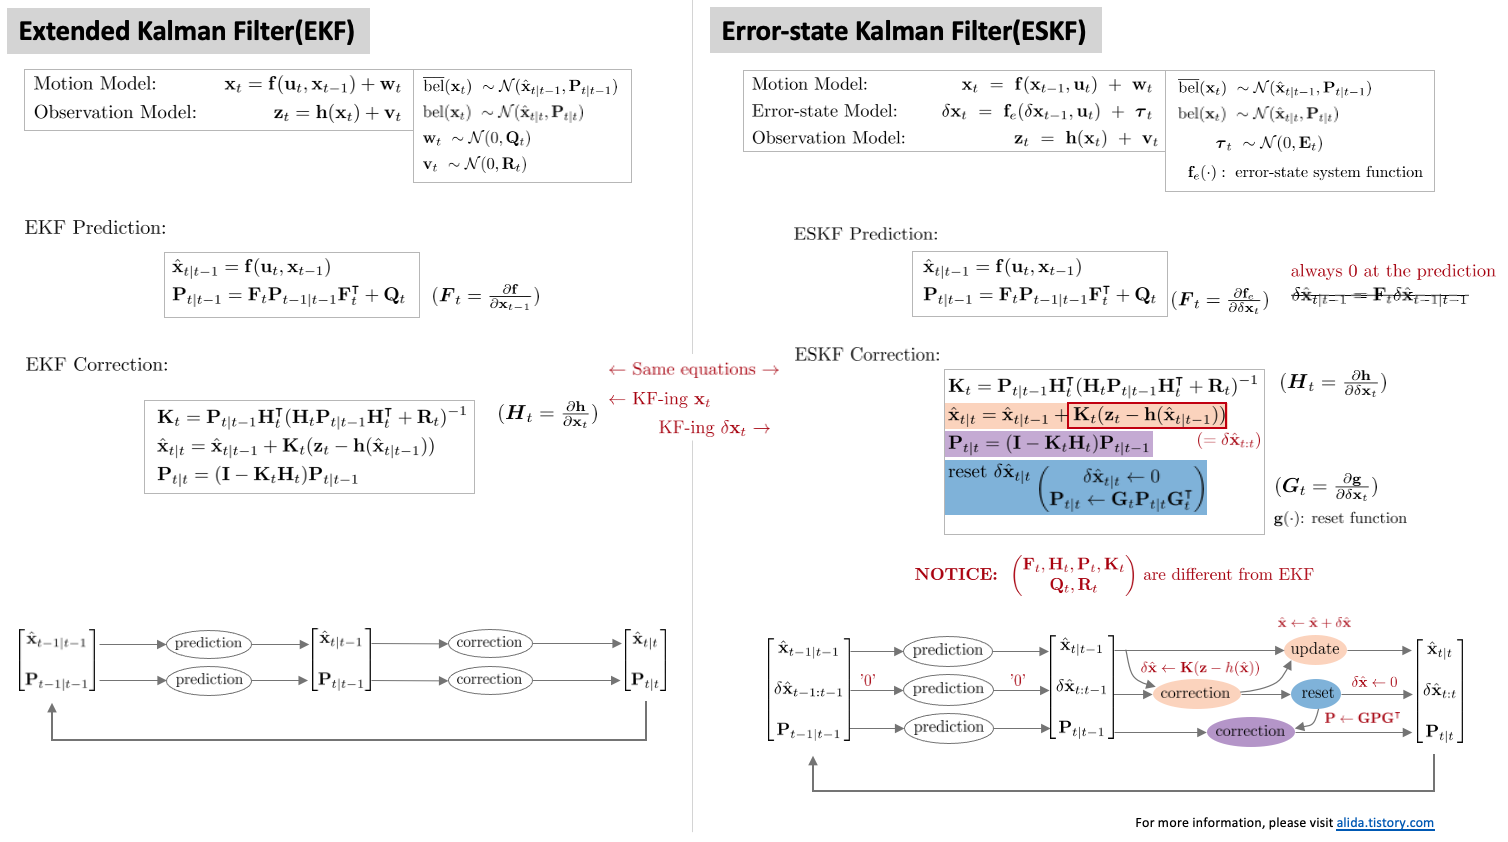

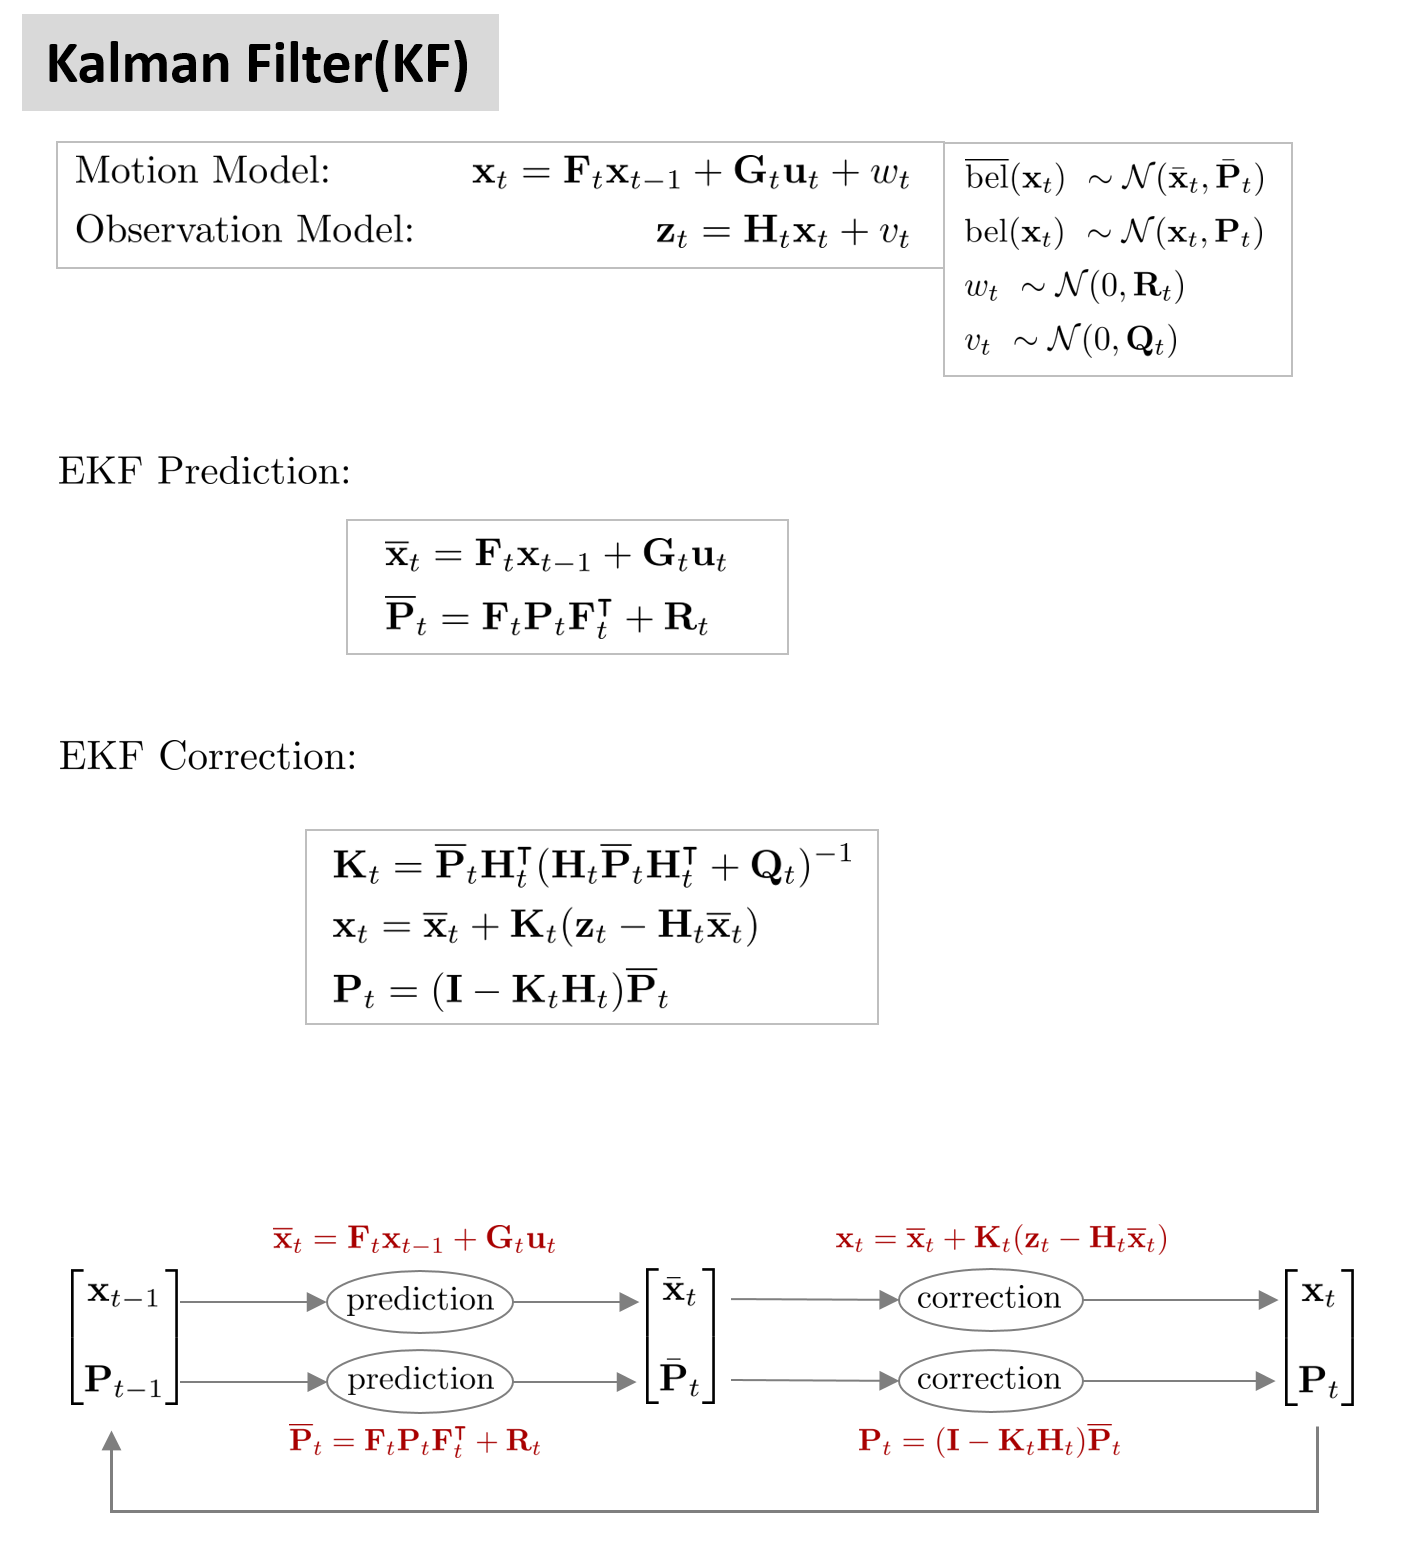 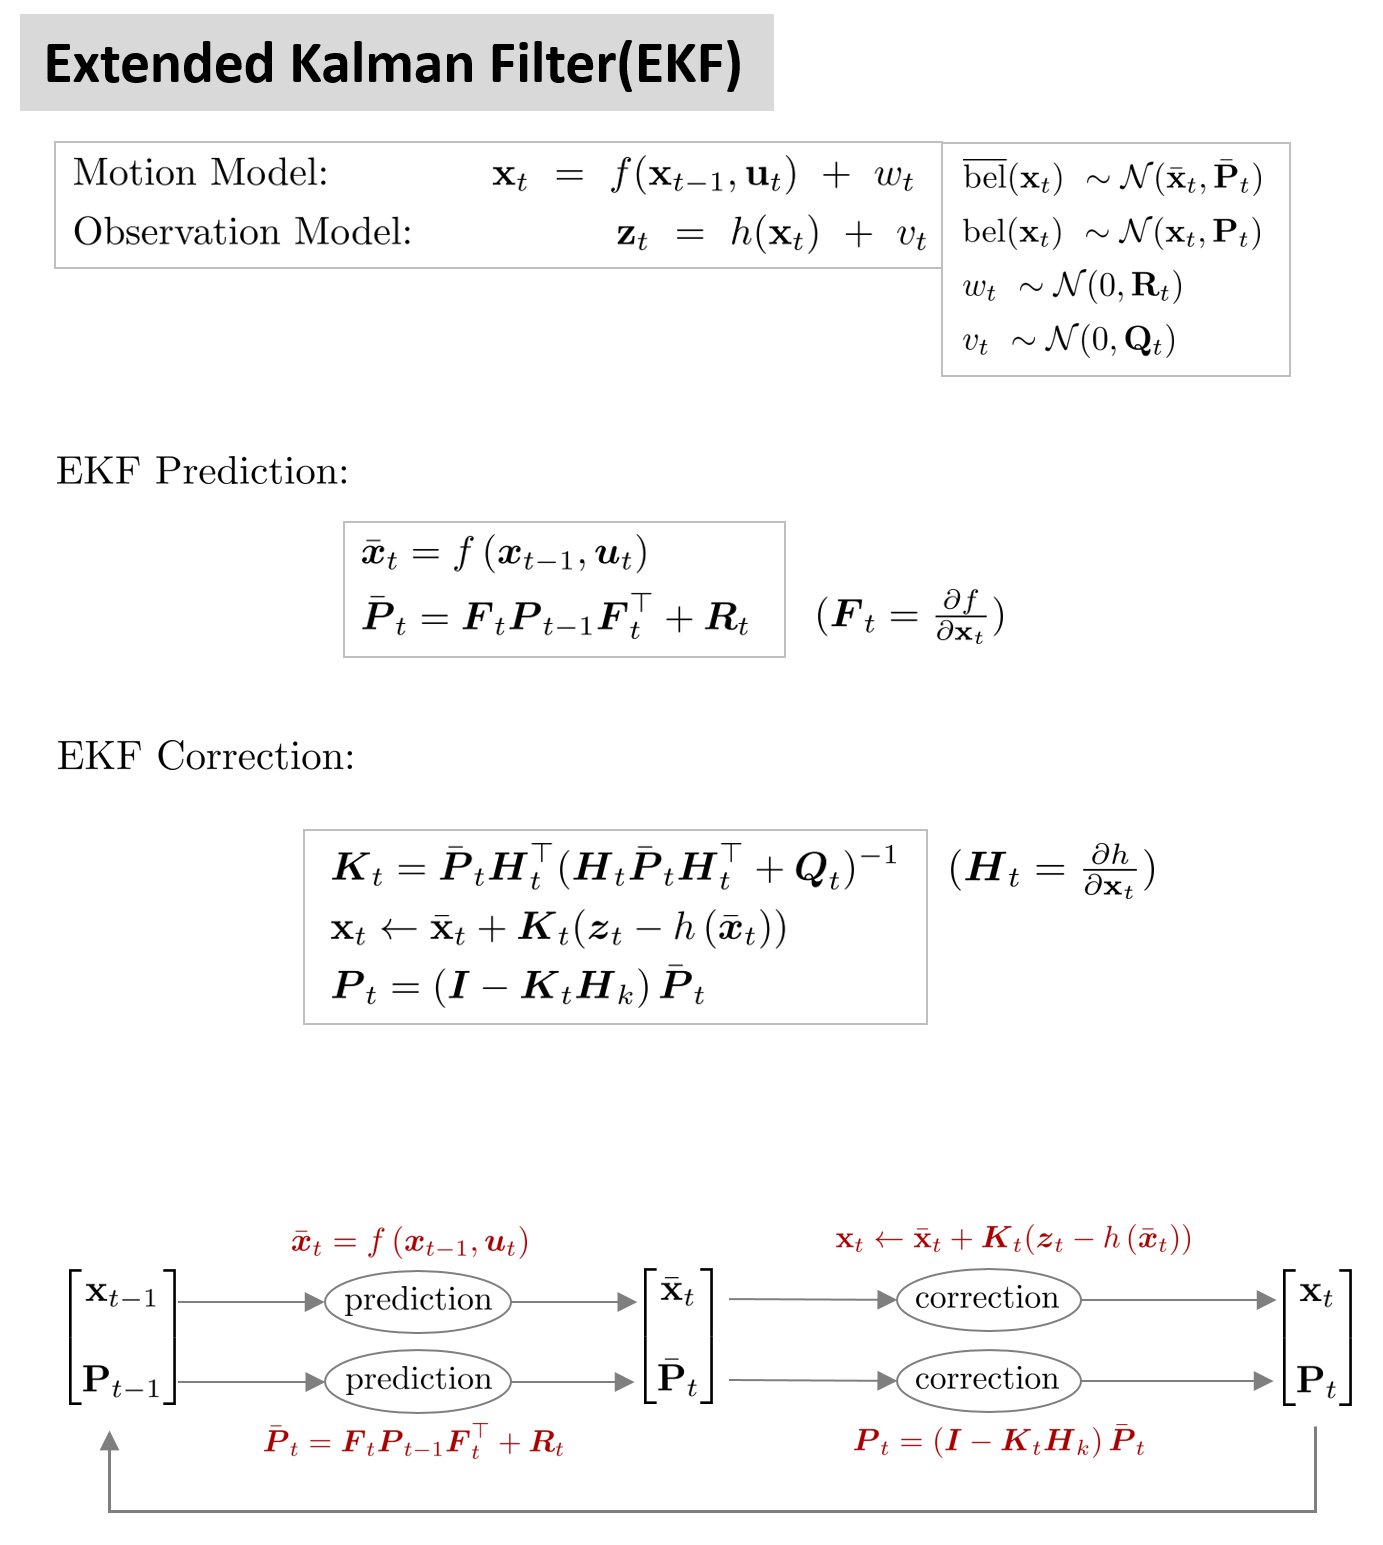

### Acréscimo: a família numa tabela

| filtro | estima | jacobianos em relação a | correção | onde aparece na série |
|---|---|---|---|---|
| **KF** | $\mathbf x$ | (modelo linear) | uma vez | `kalman_passo_a_passo`, Faragher, `mq_hmm_kalman_duas_trilhas` |
| **EKF** | $\mathbf x$ | $\mathbf x$ (e ruídos: $\mathbf F_{\mathbf w},\mathbf H_{\mathbf v}$) | uma vez = 1 passo de Gauss–Newton | `pepe_kalman_parte1_ekf_iekf` |
| **ESKF** | $\delta\mathbf x$ em torno do nominal | $\delta\mathbf x$ | uma vez, depois injeção $\boxplus$ e reset $\mathbf G$ | este notebook (atitude) |
| **IEKF** | $\mathbf x$ | $\mathbf x$, relinearizados | até convergir = Gauss–Newton = MAP | `pepe_kalman_parte1_ekf_iekf`, seção C5b de `mq_hmm_kalman_duas_trilhas` |
| **IESKF** | $\delta\mathbf x$ em torno do iterado | $\delta\mathbf x$, relinearizados, mais $\mathbf J$ | até convergir = Gauss–Newton na variedade | este notebook (atitude) |

Uma regra para guardar: **"estendido" = linearizar; "iterado" = Gauss–Newton até convergir; "de estado de erro" = trabalhar num espaço vetorial tangente quando o estado não é um vetor.** As três ideias são independentes e se combinam.

---
# 12. Notas do tradutor: lista consolidada

Todas as correções feitas no texto, na ordem em que aparecem. A coluna "gravidade" separa os erros que **mudam o resultado** dos que são só de digitação.

| # | onde (no original) | o que está escrito | correção | gravidade | conferido em |
|---|---|---|---|---|---|
| 1 | §2, dedução do filtro de Bayes | última linha com $\overline{\mathrm{bel}}(\mathbf x_{t-1})$ | $\overline{\mathrm{bel}}(\mathbf x_t)$ | digitação | — |
| 2 | §3 e §4, valor inicial | "$\mathbf P_0$ tipicamente pequeno ($<10^{-2}$)" com $\hat{\mathbf x}_0=0$ | $\mathbf P_0$ deve refletir a incerteza inicial: chute ⇒ $\mathbf P_0$ grande | **muda o resultado** | §3 (NEES no transitório) |
| 3 | §3.1, KF 1D | $x_t=x_{t-1}+u_t+\sigma^2_{\text{motion}}$ | soma-se um ruído de variância $\sigma^2$ | conceitual | — |
| 4 | §3.2, ganho | "$\mathbf K_t\to\mathbf 1$" | só vale no caso escalar com $H=1$ | conceitual | — |
| 5 | §5, ESKF | "o EKF é lento e acumula erro; o ESKF é rápido e preciso" | só há diferença quando o estado não é vetor | conceitual | §5.3 (ESKF = EKF) |
| 6 | §5.1, modelos do ESKF | o termo $\mathbf H_t\delta\mathbf x_t$ some da observação | o erro estimado é zero, o erro não | conceitual | — |
| 7 | §5.2, correção do ESKF | $\mathbf H_{\mathbf v}\mathbf R_t\mathbf H_{\mathbf v}$ | $\mathbf H_{\mathbf v}\mathbf R_t\mathbf H_{\mathbf v}^\top$ | digitação | — |
| 8 | §5.2, reset | $\mathbf g(\delta\mathbf x)=\delta\mathbf x-\delta\hat{\mathbf x}_{t\vert t-1}$ | desconta-se $\delta\hat{\mathbf x}_{t\vert t}$ (com $\boxminus$) | conceitual | §5.4 ($\mathbf G=\mathbf J_r$) |
| 9 | §5.3, resumo do ESKF | $\mathbf F_t\hat{\mathbf x}_{t-1\vert t-1}$; $\mathbf G\mathbf P\mathbf P^\top$; retorna $\delta\hat{\mathbf x}$ | $\mathbf F_t\delta\hat{\mathbf x}_{t-1\vert t-1}$; $\mathbf G\mathbf P\mathbf G^\top$; retorna $\hat{\mathbf x}_{t\vert t}$ | digitação | — |
| 10 | **§6, correção do IEKF (texto, resumo, figs. 07 e 12)** | $\hat{\mathbf x}_{t\vert t,j+1}=\hat{\mathbf x}_{t\vert t,j}+\mathbf K\mathbf r_j$ | $\hat{\mathbf x}_{t\vert t,j+1}=\hat{\mathbf x}_{t\vert t-1}+\mathbf K\mathbf r_j$ | **diverge** | §6 (caso linear e não linear) |
| 11 | §7, pesos do IESKF; §10, símbolo $\mathbf R$ | $\mathbf H_{\mathbf v}\mathbf R^{-1}\mathbf H_{\mathbf v}^\top$ | $(\mathbf H_{\mathbf v}\mathbf R\mathbf H_{\mathbf v}^\top)^{-1}$ | só coincide se $\mathbf H_{\mathbf v}$ ortogonal | §10 |
| 12 | §7, problema MAP do IESKF | $\mathbf h(\hat{\mathbf x}_{t\vert t-1},0,0)$ | $\mathbf h(\hat{\mathbf x}_{t\vert t,j},0,0)$ | conceitual | §7 (atitude) |
| 13 | §7, resumo do IESKF | $\mathbf F_t\hat{\mathbf x}_{t-1\vert t-1}$ | $\mathbf F_t\delta\hat{\mathbf x}_{t-1\vert t-1}$ | digitação | — |
| 14 | §8 inteira e fig. 25 | $\mathbf R$ = ruído de movimento, $\mathbf Q$ = ruído de medida | convenção trocada em relação ao resto do texto | confusão de notação | — |
| 15 | §8.2, quadro final | "$\mathbf K_t=\hat{\mathbf x}_{t\vert t-1}+\mathbf K_t(\cdot)$" | $\mathbf K_t=\mathbf P_{t\vert t-1}\mathbf H_t^\top(\mathbf H_t\mathbf P_{t\vert t-1}\mathbf H_t^\top+\mathbf R_t)^{-1}$ | digitação | §8.3 |
| 16 | §9.1, EKF tradicional | $\hat{\mathbf x}_{t\vert t}=\mathbf K_t(\cdot)$ | $\hat{\mathbf x}_{t\vert t}=\hat{\mathbf x}_{t\vert t-1}+\mathbf K_t(\cdot)$ | digitação | — |
| 17 | §9.2, MAP | $\arg\min\exp(\cdot)$ e $\mathbf P^{-1_{t\vert t-1}}$ | minimiza-se o expoente | digitação | — |
| 18 | §9.3, covariância *a posteriori* | $\mathbb E[(\mathbf x_t-\hat{\mathbf x}_{t\vert t-1})(\cdot)^\top]$ | covariância do erro do estimador | conceitual (resultado certo) | §9 |
| 19 | §9.3, iteração de GN | peso $\mathbf P_{t\vert t-1}^{-1}$ | $\mathbf P_{\mathbf e}^{-1}$ (dimensões incompatíveis no original) | **produto indefinido** | §9 (`ValueError`) |

**Leitura.** São erros de anotações de estudo, não de um livro revisado, e quase todos são de digitação. O único que **muda o algoritmo** é o nº 10, e ele é desmentido pelo próprio texto em dois lugares (seção 9, última linha; seção 7, com $\mathbf J=\mathbf I$). Encontrar essa contradição lendo o texto com atenção, e confirmá-la com dez linhas de código, é talvez a lição mais útil deste notebook.

---
# 13. Exercícios

1. **$\mathbf P_0$ e confiança.** Na seção 3, encontre o menor $\mathbf P_0=p\,\mathbf I$ para o qual o NEES médio dos passos 1–20 fica abaixo de 6. Relacione $p$ com o erro inicial ($50$ m na posição, $4$ m/s na velocidade).

2. **O EKF quebra.** No exemplo da seção 6, aumente $P_{yy}$ da predição de 4 para 16 e depois para 64. Para cada caso, compare o erro do EKF (iteração 1) e do IEKF até o MAP. A partir de que incerteza o EKF fica pior que a própria predição?

3. **Bell e Cathey em uma linha.** Mostre algebricamente que a forma "incremental" $\hat{\mathbf x}_{j+1}=\hat{\mathbf x}_j+\big[\mathbf K_j\mathbf r_j-(\hat{\mathbf x}_j-\hat{\mathbf x}_{t|t-1})\big]$ coincide com a forma da seção 6.3, e implemente-a numa linha alterando `iekf_correcao`.

4. **Observabilidade na atitude.** Na seção 5.4, retire o magnetômetro (use só as três primeiras componentes de $\mathbf z$ e de $\mathbf H$). Rode o ESKF e explique o que acontece com o desvio reportado de $\delta\theta_z$ e com o erro verdadeiro. Por que o acelerômetro não "vê" a rotação em torno da vertical?

5. **Quaternions em vez de matrizes.** Reescreva `boxplus` e `boxminus` usando quaternions unitários, com $\mathbf q\boxplus\delta\boldsymbol\theta=\mathbf q\otimes\mathrm{Exp}_q(\delta\boldsymbol\theta)$. Confira que o ESKF da seção 5.4 dá exatamente as mesmas estimativas.

6. **O EKF "ingênuo" no quaternion.** Implemente um EKF cujo estado é o quaternion $\mathbf q\in\mathbb R^4$ (covariância $4\times4$), somando a correção diretamente e normalizando depois. Compare com o ESKF no mesmo cenário: erro, NEES e o que acontece com a covariância na direção radial $\mathbf q$.

7. **Gauss–Newton amortecido.** Troque, em `gauss_newton_aumentado`, o passo de Gauss–Newton por um passo de Levenberg–Marquardt, $(\tilde{\mathbf H}+\lambda\mathbf I)\delta\mathbf x=\mathbf J^\top\mathbf P_{\mathbf e}^{-1}\mathbf r$. Em que situação isso ajuda o IEKF? (Dica: medidas muito precisas de uma função muito curva, longe da predição.)

---
# 14. Referências

**Obra traduzida.** G. E. Im, *Notes on Kalman Filter (KF, EKF, ESKF, IEKF, IESKF)*, arXiv:2406.06427v3, 2024. Licença CC BY (conforme informado). Histórico de revisões do original: 13 versões, de 23/06/2020 a 28/06/2024.

**Referências do original** (numeração mantida, citadas no texto como [n]):
1. [Kalman filter — Wikipedia](https://en.wikipedia.org/wiki/Kalman_filter).
2. J. Solà, *Quaternion kinematics for the error-state Kalman filter*, [arXiv:1711.02508](https://arxiv.org/abs/1711.02508), 2017.
3. *Robot Mapping*, curso da Universidade de Freiburg (C. Stachniss), [vídeo](https://youtu.be/wVsfCnyt5jA).
4. J. Jeong, [*[SLAM] Kalman filter and EKF*](http://jinyongjeong.github.io/2017/02/14/lec03_kalman_filter_and_EKF/) (blog).
5. [*Error-State Kalman Filter: compreensão e dedução das fórmulas*](https://blog.csdn.net/liu3612162/article/details/114120772) (CSDN, blog).
6. D. He, W. Xu, F. Zhang, *Kalman filters on differentiable manifolds*, [arXiv:2102.03804](https://arxiv.org/abs/2102.03804), 2021.
7. X. Gao et al., [*SLAM in Autonomous Driving*](https://github.com/gaoxiang12/slam_in_autonomous_driving) (livro e código).
8. W. Xu, F. Zhang, *FAST-LIO: a fast, robust LiDAR-inertial odometry package by tightly-coupled iterated Kalman filter*, IEEE RA-L 6(2):3317–3324, 2021, [arXiv:2010.08196](https://arxiv.org/abs/2010.08196).
9. J. Huai, X. Gao, *A quick guide for the iterated extended Kalman filter on manifolds*, [arXiv:2307.09237](https://arxiv.org/abs/2307.09237), 2023.
10. M. Bloesch et al., *Iterated extended Kalman filter based visual-inertial odometry using direct photometric feedback*, IJRR 36(10):1053–1072, 2017.
11. M. A. Skoglund, G. Hendeby, D. Axehill, *Extended Kalman filter modifications based on an optimization view point*, FUSION 2015.
12. [*From MAP, MLE, OLS, GN to IEKF, EKF*](https://cgabc.xyz/posts/784a80cb/) (blog).
13. S. Thrun, W. Burgard, D. Fox, *Probabilistic Robotics*, MIT Press, 2005 (o original cita, por engano, o artigo homônimo de Thrun em *Communications of the ACM* 45(3), 2002).

**Acrescentadas nesta tradução.**
- B. M. Bell, F. W. Cathey, *The iterated Kalman filter update as a Gauss–Newton method*, IEEE Trans. Automatic Control 38(2):294–297, 1993. (A forma correta do IEKF.)
- V. Madyastha et al., *Extended Kalman filter vs. error state Kalman filter for aircraft attitude estimation*, AIAA GNC, 2011. (Citado no original sem entrada na lista.)
- Os outros notebooks da série; veja `kalman_guia_da_serie`.